In [1]:
# ==============================
# Start of execution
# ==============================
import time
start = time.time()

# 🛒 Instacart Market Basket Analysis — Recommender Systems

**Notebook goal:** understand Instacart's business problem, explore the data (EDA), and build recommender systems that anticipate which products each customer will buy in their next order.

**Dataset:** [Instacart Market Basket Analysis — Kaggle](https://www.kaggle.com/c/instacart-market-basket-analysis)
~3 million orders from ~200k anonymized customers across ~50k products (2017).

---

## 1. Business Understanding

### 1.1 Context
Instacart is an online grocery delivery app (US and Canada). Customers choose a store, build their cart in the app, and a *shopper* picks up the items and delivers them to their home.

Building a grocery cart is a **repetitive and tedious** task: many items, mostly the same ones every time, and a high chance of forgetting something.

### 1.2 Business Question
> **Given a customer's purchase history, which products will they buy in their next order?**

### 1.3 Why It Matters — Business Value

| In-app use case | Benefit | Related KPI |
|---|---|---|
| **"Buy it again"** / pre-filled cart | Saves customers time, reduces friction | Time to checkout, conversion rate |
| **"Forgot something?"** before checkout | Prevents forgotten items, completes the order | Average order value, items per order |
| **"Frequently bought together"** | Cross-selling | Attach rate, average order value |
| **"Discover"** new products | Expands the basket, monetizes brands | % of new products purchased |
| **Reorder reminders** | Customer retention | Purchase frequency, churn |

At its core, this is a **customer experience and loyalty** problem: if the app "knows" the customer, shopping there becomes easier than with any competitor.

### 1.4 What Makes This Problem Different (vs. recommending movies or music)
1. **Repetition is the norm:** grocery customers buy the same products over and over (milk, bread, bananas). Much of the value lies in predicting **reorders**, not just discovering new products.
2. **Implicit feedback:** there are no ratings; we only know what was bought, when, and in what order.
3. **We predict an entire basket**, not a single item, and we also need to decide **how many** products to recommend.
4. **Long-tail catalog:** a small number of products account for most sales, which creates a risk of **popularity bias**.

### 1.5 Framing as a Machine Learning Problem
- **Competition framing (Kaggle):** predict which **previously purchased** products will appear in the customer's next order → binary classification (customer × product), evaluated with **mean F1-score**.
- **Recommender framing:** generate a Top-K list of products for each customer (reorders + new products), evaluated with **Precision@K, Recall@K, Hit Rate@K and NDCG@K**, plus **catalog coverage** to measure diversity.

### 1.6 Validation Scheme
The dataset is already split over time:
- **`prior`**: each customer's order history → data to learn from.
- **`train`**: the **last order** of a subset of customers → what we try to predict (validation).
- **`test`**: the last order of other customers, without labels (for Kaggle submission).

This lets us evaluate models the way they would work in production: **we use the past to predict the next order**, with no data leakage.

## 2. Setup

Import libraries, define global parameters, and set a consistent plotting style for the rest of the notebook.

In [2]:
# ==============================
# Libraries
# ==============================
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

warnings.filterwarnings("ignore")

# ==============================
# Global parameters
# ==============================
DATA_DIR = Path("data")   # folder containing the Kaggle CSV files
SEED = 42                 # for reproducibility
rng = np.random.default_rng(SEED)

# ==============================
# Display options
# ==============================
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# ==============================
# Plotting style
# ==============================
BLUE, ORANGE, GREEN, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8a85"

plt.rcParams.update({
    "figure.figsize": (10, 4.5),
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#ecebe6",
    "axes.axisbelow": True,
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "axes.titlelocation": "left",
})

def pct_axis(ax, axis="y"):
    """Format an axis as percentage (0-1 scale)."""
    target = ax.yaxis if axis == "y" else ax.xaxis
    target.set_major_formatter(mtick.PercentFormatter(1.0))

print(f"pandas {pd.__version__} | numpy {np.__version__}")

pandas 2.2.3 | numpy 2.4.6


In [3]:
# ==============================
# Download data from Kaggle (Colab)
# ==============================
import os
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

!kaggle datasets download -d psparks/instacart-market-basket-analysis -p data --unzip
!ls -lh data

Dataset URL: https://www.kaggle.com/datasets/psparks/instacart-market-basket-analysis
License(s): CC0-1.0
100% 197M/197M [00:10<00:00, 19.3MB/s]

total 681M
-rw-r--r-- 1 root root 2.6K Nov 14 22:07 aisles.csv
-rw-r--r-- 1 root root  270 Nov 14 22:07 departments.csv
-rw-r--r-- 1 root root 551M Nov 14 22:07 order_products__prior.csv
-rw-r--r-- 1 root root  24M Nov 14 22:07 order_products__train.csv
-rw-r--r-- 1 root root 104M Nov 14 22:07 orders.csv
-rw-r--r-- 1 root root 2.1M Nov 14 22:07 products.csv


## 3. Data Loading

The dataset is a relational set of 6 files:

| File | Granularity | Description |
|---|---|---|
| `orders.csv` | 1 row per order | Who placed the order, when (day of week, hour), days since the previous order, and which set it belongs to (`prior` / `train` / `test`) |
| `order_products__prior.csv` | 1 row per product in an order | Products in each customer's **historical** orders, cart position and whether it was a reorder |
| `order_products__train.csv` | 1 row per product in an order | Products in each customer's **last** order (our target) |
| `products.csv` | 1 row per product | Product name, aisle and department |
| `aisles.csv` | 1 row per aisle | Aisle names (134) |
| `departments.csv` | 1 row per department | Department names (21) |

**Relationships:** `orders` ⟶ `order_products__*` (via `order_id`) ⟶ `products` (via `product_id`) ⟶ `aisles` / `departments`.

The prior table has ~32M rows, so we load it with **compact data types** to reduce memory usage.

In [4]:
# ==============================
# Load data with optimized dtypes
# ==============================
orders = pd.read_csv(DATA_DIR / "orders.csv", dtype={
    "order_id": "int32",
    "user_id": "int32",
    "eval_set": "category",
    "order_number": "int16",
    "order_dow": "int8",
    "order_hour_of_day": "int8",
    "days_since_prior_order": "float32",
})

order_products_dtypes = {
    "order_id": "int32",
    "product_id": "int32",
    "add_to_cart_order": "int16",
    "reordered": "int8",
}
prior = pd.read_csv(DATA_DIR / "order_products__prior.csv", dtype=order_products_dtypes)
train = pd.read_csv(DATA_DIR / "order_products__train.csv", dtype=order_products_dtypes)

products = pd.read_csv(DATA_DIR / "products.csv", dtype={
    "product_id": "int32", "aisle_id": "int16", "department_id": "int8"})
aisles = pd.read_csv(DATA_DIR / "aisles.csv")
departments = pd.read_csv(DATA_DIR / "departments.csv")

# Enrich products with aisle and department names
products = (products
            .merge(aisles, on="aisle_id", how="left")
            .merge(departments, on="department_id", how="left"))

# ==============================
# Overview: size and memory
# ==============================
tables = {"orders": orders, "prior": prior, "train": train,
          "products": products, "aisles": aisles, "departments": departments}

overview = pd.DataFrame({
    "rows": [df.shape[0] for df in tables.values()],
    "columns": [df.shape[1] for df in tables.values()],
    "memory_MB": [df.memory_usage(deep=True).sum() / 1e6 for df in tables.values()],
}, index=tables.keys())

overview.style.format({"rows": "{:,}", "memory_MB": "{:,.1f}"})

,rows,columns,memory_MB
orders,"3,421,083",7,58.2
prior,"32,434,489",4,356.8
train,"1,384,617",4,15.2
products,"49,688",6,10.3
aisles,134,2,0.0
departments,21,2,0.0


In [5]:
for name, df in tables.items():
    print(f"\n{'='*60}\n{name.upper()}  —  {df.shape[0]:,} rows × {df.shape[1]} cols\n{'='*60}")
    display(df.head(3))

print("\nOrders by eval_set:")
display(orders["eval_set"].value_counts().to_frame("n_orders"))

print(f"Unique customers: {orders['user_id'].nunique():,}")
print(f"Unique products : {products['product_id'].nunique():,}")


ORDERS  —  3,421,083 rows × 7 cols


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.000
2,473747,1,prior,3,3,12,21.000



PRIOR  —  32,434,489 rows × 4 cols


,order_id,product_id,add_to_cart_order,reordered
0,2,33120,1,1
1,2,28985,2,1
2,2,9327,3,0



TRAIN  —  1,384,617 rows × 4 cols


,order_id,product_id,add_to_cart_order,reordered
0,1,49302,1,1
1,1,11109,2,1
2,1,10246,3,0


... (5 outputs left out)

,department_id,department
0,1,frozen
1,2,other
2,3,bakery



Orders by eval_set:


,n_orders
eval_set,
prior,3214874
train,131209
test,75000


Unique customers: 206,209
Unique products : 49,688


## 4. Data Quality

Before exploring the data, we check that it is reliable:

1. **Missing values** — where they are and whether they make sense.
2. **Duplicates** — repeated orders or repeated products within an order.
3. **Referential integrity** — every key in one table exists in the related table.
4. **Consistency of the split** — each customer has exactly one `train`/`test` order, and it is their last one.
5. **Value ranges** — values within expected limits (hours 0–23, days 0–6, etc.).

In [6]:
# ==============================
# 4.1 Missing values
# ==============================
missing = pd.concat(
    {name: df.isna().sum() for name, df in tables.items()}, names=["table", "column"]
).to_frame("n_missing")
missing["pct_missing"] = missing["n_missing"] / missing.index.get_level_values("table").map(
    lambda t: len(tables[t]))
display(missing[missing["n_missing"] > 0])

# Are the missing days_since_prior_order exactly the customers' first orders?
null_days = orders["days_since_prior_order"].isna()
first_orders = orders["order_number"] == 1
print(f"Missing days_since_prior_order: {null_days.sum():,}")
print(f"First orders (order_number = 1): {first_orders.sum():,}")
print(f"Missing values match first orders exactly: {(null_days == first_orders).all()}")

# ==============================
# 4.2 Duplicates
# ==============================
duplicates = pd.Series({
    "orders (order_id)": orders["order_id"].duplicated().sum(),
    "prior (order_id, product_id)": prior.duplicated(["order_id", "product_id"]).sum(),
    "train (order_id, product_id)": train.duplicated(["order_id", "product_id"]).sum(),
    "products (product_id)": products["product_id"].duplicated().sum(),
}, name="n_duplicates")
display(duplicates.to_frame())

,,n_missing,pct_missing
table,column,,
orders,days_since_prior_order,206209,0.060


Missing days_since_prior_order: 206,209
First orders (order_number = 1): 206,209
Missing values match first orders exactly: True


,n_duplicates
orders (order_id),0
"prior (order_id, product_id)",0
"train (order_id, product_id)",0
products (product_id),0


In [7]:
# ==============================
# 4.3 Referential integrity
# ==============================
integrity = pd.Series({
    "prior.order_id not in orders": (~prior["order_id"].isin(orders["order_id"])).sum(),
    "train.order_id not in orders": (~train["order_id"].isin(orders["order_id"])).sum(),
    "prior.product_id not in products": (~prior["product_id"].isin(products["product_id"])).sum(),
    "train.product_id not in products": (~train["product_id"].isin(products["product_id"])).sum(),
    "products with unknown aisle": products["aisle"].isna().sum(),
    "products with unknown department": products["department"].isna().sum(),
}, name="n_issues")
display(integrity.to_frame())

# ==============================
# 4.4 Consistency of the train/test split
# ==============================
last_orders = orders[orders["eval_set"] != "prior"]
max_order = orders.groupby("user_id")["order_number"].max()

print("Each customer has exactly one train/test order:",
      last_orders.groupby("user_id").size().eq(1).all())
print("That order is always the customer's last one:",
      (last_orders.set_index("user_id")["order_number"] == max_order.loc[last_orders["user_id"]].values).all())
print("No customer is in both train and test:",
      last_orders.groupby("user_id")["eval_set"].nunique().eq(1).all())

# ==============================
# 4.5 Value ranges
# ==============================
ranges = orders[["order_number", "order_dow", "order_hour_of_day", "days_since_prior_order"]].agg(["min", "max"]).T
ranges["expected"] = ["1 – 100", "0 – 6", "0 – 23", "0 – 30"]

display(ranges)

print(f"reordered values in prior: {sorted(prior['reordered'].unique())}")

# ==============================
# 4.6 Placeholder categories
# ==============================
placeholder = products[(products["department"] == "missing") | (products["aisle"] == "missing")]
print(f"\nProducts in 'missing' department/aisle: {len(placeholder):,} "
      f"({len(placeholder) / len(products):.1%} of catalog)")
display(placeholder.head())

,n_issues
prior.order_id not in orders,0
train.order_id not in orders,0
prior.product_id not in products,0
train.product_id not in products,0
products with unknown aisle,0
products with unknown department,0


Each customer has exactly one train/test order: True
That order is always the customer's last one: True
No customer is in both train and test: True


,min,max,expected
order_number,1.000,100.000,1 – 100
order_dow,0.000,6.000,0 – 6
order_hour_of_day,0.000,23.000,0 – 23
days_since_prior_order,0.000,30.000,0 – 30


reordered values in prior: [np.int8(0), np.int8(1)]

Products in 'missing' department/aisle: 1,258 (2.5% of catalog)


,product_id,product_name,aisle_id,department_id,aisle,department
37,38,Ultra Antibacterial Dish Liquid,100,21,missing,missing
71,72,Organic Honeycrisp Apples,100,21,missing,missing
109,110,Uncured Turkey Bologna,100,21,missing,missing
296,297,"Write Bros Ball Point Pens, Cap-Pen, Medium (1...",100,21,missing,missing
416,417,Classics Baby Binks Easter Chocolate Bunny,100,21,missing,missing


### 4.7 Data Quality — Key Findings

**Missing values**
- The only nulls are in `days_since_prior_order`, and they correspond exactly to each customer's **first order** (there is no previous order to measure from).
- This is expected behavior, not a data error → we keep them as `NaN` and exclude them from time-between-orders analyses.

**Duplicates**
- No duplicated orders and no repeated products within the same order.

**Referential integrity** ✅
- All `order_id`s in `prior` and `train` exist in `orders`.
- All `product_id`s in `prior` and `train` exist in `products`.
- Every product has an aisle and a department assigned (no unmatched keys).

**Train/test split consistency** ✅
- Each customer has **exactly one** `train` or `test` order.
- That order is **always the customer's last one**.
- No customer appears in both `train` and `test`.
- → The split is a clean **temporal holdout**: we learn from the past (`prior`) and predict the next order (`train`), with no data leakage.

**Value ranges** ✅
| Variable | Observed | Comment |
|---|---|---|
| `order_number` | 1 – 100 | Order sequence within each customer |
| `order_dow` | 0 – 6 | Day of week (encoding not documented by Instacart) |
| `order_hour_of_day` | 0 – 23 | Hour of day |
| `days_since_prior_order` | 0 – 30 | **Capped at 30**: a value of 30 means *"30 days or more"* |
| `reordered` | 0 / 1 | Binary flag, as expected |

**Uncategorized products**
- **1,258 products (2.5% of the catalog)** belong to the `missing` aisle (`aisle_id = 100`) and `missing` department (`department_id = 21`).
- They are **real, valid products** that were simply not categorized: e.g. *Organic Honeycrisp Apples* (produce), *Ultra Antibacterial Dish Liquid* (household), *Turkey Bologna* (deli).
- Decision: **keep them** as their own category, since they are legitimate purchases. Category-level analyses should be read with this caveat in mind. A possible improvement would be to re-categorize them using their product names (e.g., text similarity with categorized products).

**Conclusion:** the dataset is clean and internally consistent. No rows need to be removed, and we can move on to exploratory analysis.

## 5. Exploratory Data Analysis (EDA)

The EDA is guided by questions that matter for the recommender:

| Block | Business question | Why it matters for recommendations |
|---|---|---|
| **5.1 Customers** | How many orders does each customer place, and how often? | How much history we have per customer (personalization vs. cold start) |
| **5.2 Time** | When do customers shop (day, hour)? | Timing of recommendations and reminders |
| **5.3 Baskets** | How many products are in an order? | How many items to recommend (K) |
| **5.4 Products** | What sells the most? How concentrated are sales? | Popularity bias, catalog coverage |
| **5.5 Reorders** | How much of each order is repeat purchases? | Weight of "Buy it again" vs. discovery |
| **5.6 Co-purchases** | Which products are bought together? | "Frequently bought together" |

---

### 5.1 Customers

**Questions:**
- How many orders does each customer have? → How much history do we have to personalize?
- How often do customers come back? → Are there distinct purchase rhythms (weekly, monthly)?

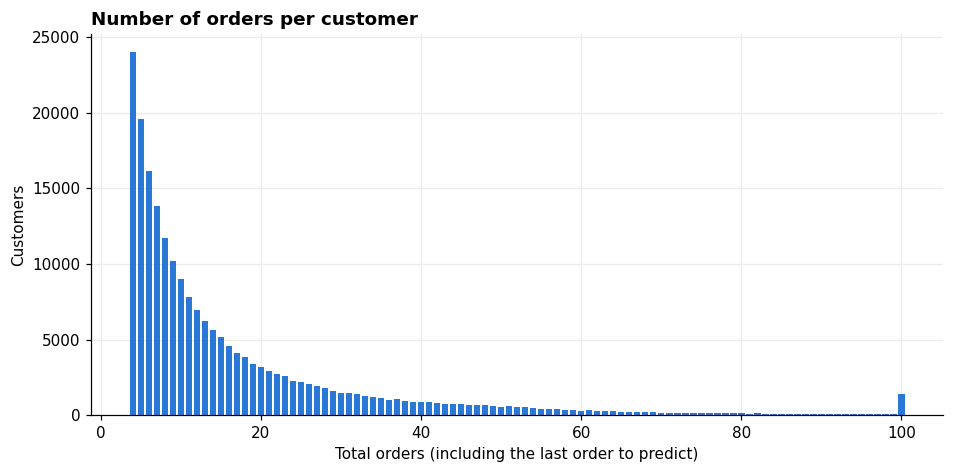

,count,mean,std,min,25%,50%,75%,90%,max
orders_per_customer,"206,209.000",16.590,16.655,4.000,6.000,10.000,20.000,38.000,100.000


,customers,share
order_number,,
4–5,"43,576",21.1%
6–10,"60,937",29.6%
11–20,"50,965",24.7%
21–50,"39,821",19.3%
51–100,"10,910",5.3%


In [8]:
# ==============================
# 5.1.1 Orders per customer
# ==============================
orders_per_customer = orders.groupby("user_id")["order_number"].max()

fig, ax = plt.subplots()
counts = orders_per_customer.value_counts().sort_index()
ax.bar(counts.index, counts.values, color=BLUE, width=0.8)
ax.set(title="Number of orders per customer",
       xlabel="Total orders (including the last order to predict)",
       ylabel="Customers")
plt.show()

display(orders_per_customer.describe(percentiles=[.25, .5, .75, .9]).to_frame("orders_per_customer").T)

# Share of customers by history length
bins = [0, 5, 10, 20, 50, 100]
labels = ["4–5", "6–10", "11–20", "21–50", "51–100"]
segments = pd.cut(orders_per_customer, bins=bins, labels=labels)
seg_table = segments.value_counts().sort_index().to_frame("customers")
seg_table["share"] = seg_table["customers"] / seg_table["customers"].sum()
display(seg_table.style.format({"customers": "{:,}", "share": "{:.1%}"}))

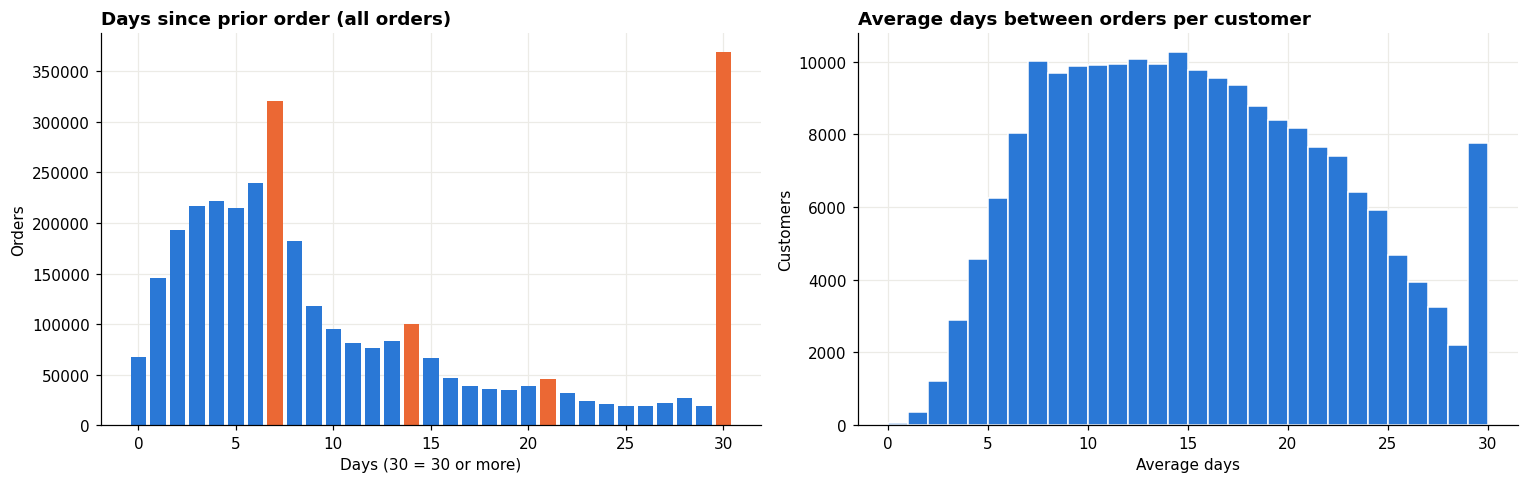

,customers,share
days_since_prior_order,,
Weekly or more (≤7d),"24,471",11.9%
Biweekly (8–14d),"69,579",33.7%
Every 3 weeks (15–21d),"64,353",31.2%
Monthly+ (22–30d),"47,806",23.2%


Spearman correlation (n° of orders vs. avg days between orders): -0.60


In [9]:
# ==============================
# 5.1.2 Purchase frequency per customer
# ==============================
# Average days between orders for each customer (first order excluded: NaN)
customer_freq = orders.groupby("user_id")["days_since_prior_order"].mean()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Distribution of days between orders (all orders)
d = orders["days_since_prior_order"].dropna().value_counts().sort_index()
highlight = [ORANGE if x in (7, 14, 21, 30) else BLUE for x in d.index]
axes[0].bar(d.index, d.values, color=highlight, width=0.8)
axes[0].set(title="Days since prior order (all orders)",
            xlabel="Days (30 = 30 or more)", ylabel="Orders")

# Distribution of each customer's average
axes[1].hist(customer_freq.dropna(), bins=30, color=BLUE, edgecolor="white")
axes[1].set(title="Average days between orders per customer",
            xlabel="Average days", ylabel="Customers")

plt.tight_layout()
plt.show()

# Customer segmentation by purchase rhythm
freq_bins = [0, 7, 14, 21, 30]
freq_labels = ["Weekly or more (≤7d)", "Biweekly (8–14d)", "Every 3 weeks (15–21d)", "Monthly+ (22–30d)"]
freq_segments = pd.cut(customer_freq, bins=freq_bins, labels=freq_labels, include_lowest=True)
freq_table = freq_segments.value_counts().sort_index().to_frame("customers")
freq_table["share"] = freq_table["customers"] / freq_table["customers"].sum()
display(freq_table.style.format({"customers": "{:,}", "share": "{:.1%}"}))

# Do frequent buyers also have longer histories?
corr = pd.concat([orders_per_customer, customer_freq], axis=1).corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation (n° of orders vs. avg days between orders): {corr:.2f}")

In [10]:
print(f"Customers averaging 30 days between orders: {(customer_freq == 30).sum():,}")

Customers averaging 30 days between orders: 5,573


### 5.1 Customers — Key Findings

**1. Most customers have a short history**
- 206,209 customers, with a **median of 10 orders** (mean 16.6 → right-skewed distribution).
- The most common case is the minimum: **4 orders**. Counts drop sharply as history grows.
- **~51% of customers have 10 orders or fewer** (21.1% with 4–5 and 29.6% with 6–10), while only **5.3% have more than 50**.
- The spike at **100 orders** is an artifact: history was capped at 100, so it groups all customers with 100+ orders.

**2. Clear weekly and monthly purchase cycles**
- Days between orders peak at **7 days** (weekly shopping) with smaller bumps at **14 and 21 days**, plus a high concentration within the **first 1–6 days**.
- The largest spike, at **30 days**, is mostly a capping effect: it groups every order placed **30 or more days** after the previous one.

**3. Customers have different shopping rhythms**
| Segment (avg. days between orders) | Share of customers |
|---|---|
| Weekly or more (≤7d) | 11.9% |
| Biweekly (8–14d) | 33.7% |
| Every 3 weeks (15–21d) | 31.2% |
| Monthly+ (22–30d) | 23.2% |

- Most customers come back **every 1–3 weeks** (~65%).
- A distinct group of **~5.6k customers (5,573)** averages **30 days**, meaning they almost always take a month or more to return → occasional shoppers.

**4. Frequent shoppers are also the ones with longer histories**
- Spearman correlation between number of orders and average days between orders: **−0.60** (strong negative).
- Customers who buy more often accumulate more orders → a small group of **loyal, high-frequency customers** concentrates much of the activity.

**Implications for the recommender:**
- **Limited history for half the customers:** pure personal-history models will struggle for them. We should **combine personal signals with collective signals** (popularity, similar customers), and evaluate results **by history length**.
- **Heavy users** are the most valuable, and they also have the richest history. "Buy it again" should work especially well for them.
- **Recency matters:** with weekly cycles, recent purchases should weigh more than older ones (time-decay weighting).
- **Timing as a feature:** each customer's rhythm (days since last order vs. their usual interval) can predict *when* they will need to restock. This is useful for **reorder reminders** and as a model feature.
- `days_since_prior_order` should be interpreted with care because of the **30-day cap**.

### 5.2 Time: When Do Customers Shop?

**Questions:**
- Which days of the week concentrate the most orders?
- At what times of day do customers shop?
- Is there an interaction between day and hour (e.g., weekend mornings vs. weekday evenings)?

**Note:** Instacart did not document the `order_dow` encoding. It is commonly assumed that **0 = Saturday and 1 = Sunday**, but this is not confirmed. We will let the data suggest which days behave like the weekend.

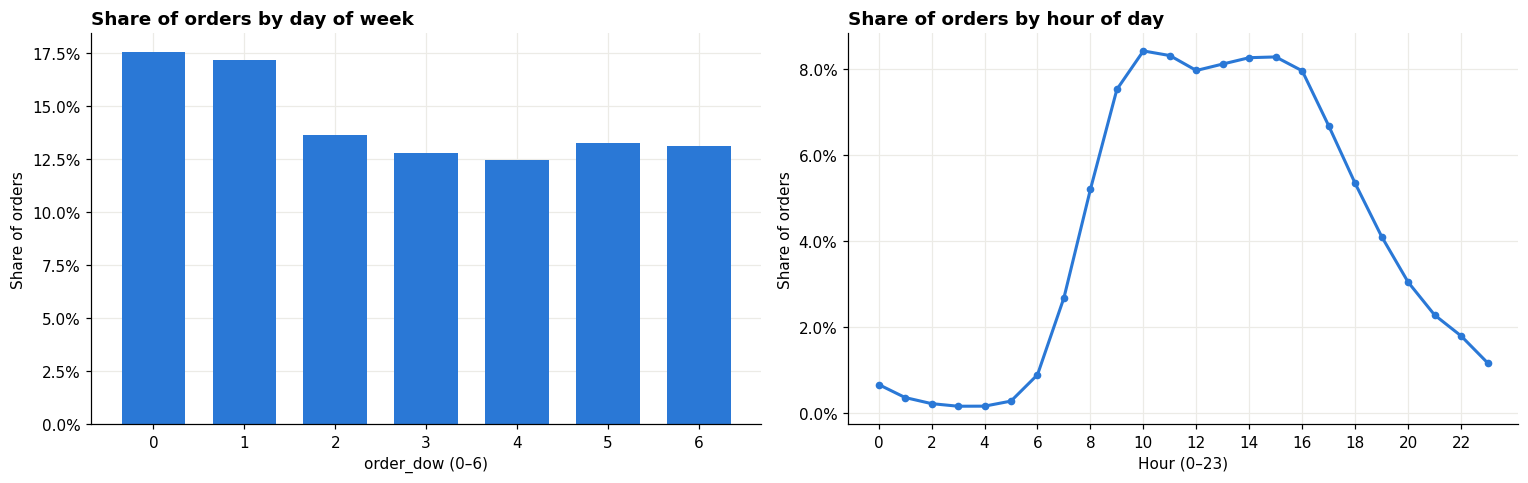

Hours covering ~80% of orders: 9h – 18h (10 hours)
Busiest day: 0 (17.6%) | Quietest day: 4 (12.5%)


In [11]:
# ==============================
# 5.2.1 Orders by day of week and hour of day
# ==============================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Day of week
by_dow = orders["order_dow"].value_counts(normalize=True).sort_index()
axes[0].bar(by_dow.index, by_dow.values, color=BLUE, width=0.7)
axes[0].set(title="Share of orders by day of week", xlabel="order_dow (0–6)", ylabel="Share of orders")
axes[0].set_xticks(range(7))
pct_axis(axes[0])

# Hour of day
by_hour = orders["order_hour_of_day"].value_counts(normalize=True).sort_index()
axes[1].plot(by_hour.index, by_hour.values, color=BLUE, lw=2, marker="o", ms=4)
axes[1].set(title="Share of orders by hour of day", xlabel="Hour (0–23)", ylabel="Share of orders")
axes[1].set_xticks(range(0, 24, 2))
pct_axis(axes[1])

plt.tight_layout()
plt.show()

# Peak hours: smallest window of hours that covers 80% of orders
cum_hours = by_hour.sort_values(ascending=False).cumsum()
peak_hours = sorted(cum_hours[cum_hours <= 0.80].index.tolist())
print(f"Hours covering ~80% of orders: {peak_hours[0]}h – {peak_hours[-1]}h ({len(peak_hours)} hours)")
print(f"Busiest day: {by_dow.idxmax()} ({by_dow.max():.1%}) | Quietest day: {by_dow.idxmin()} ({by_dow.min():.1%})")

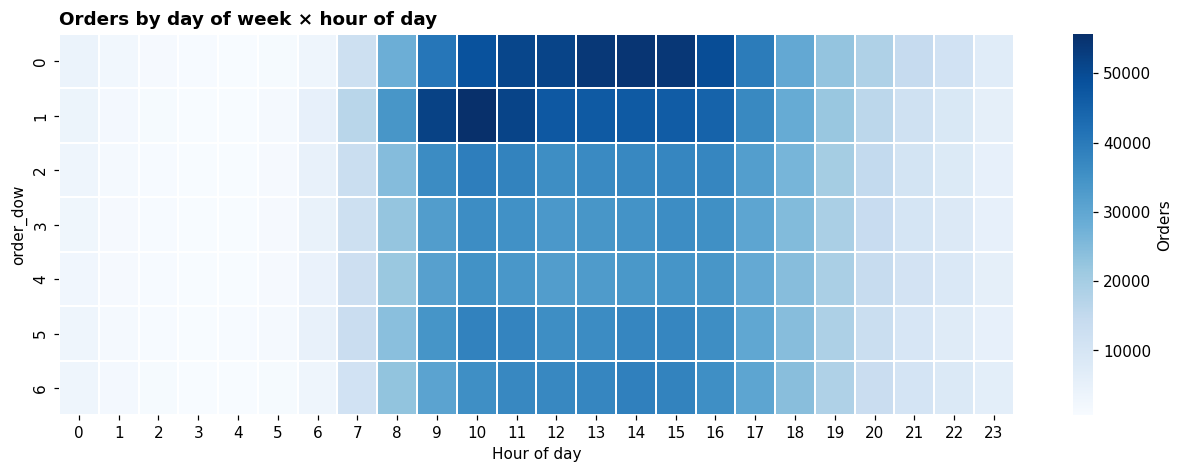

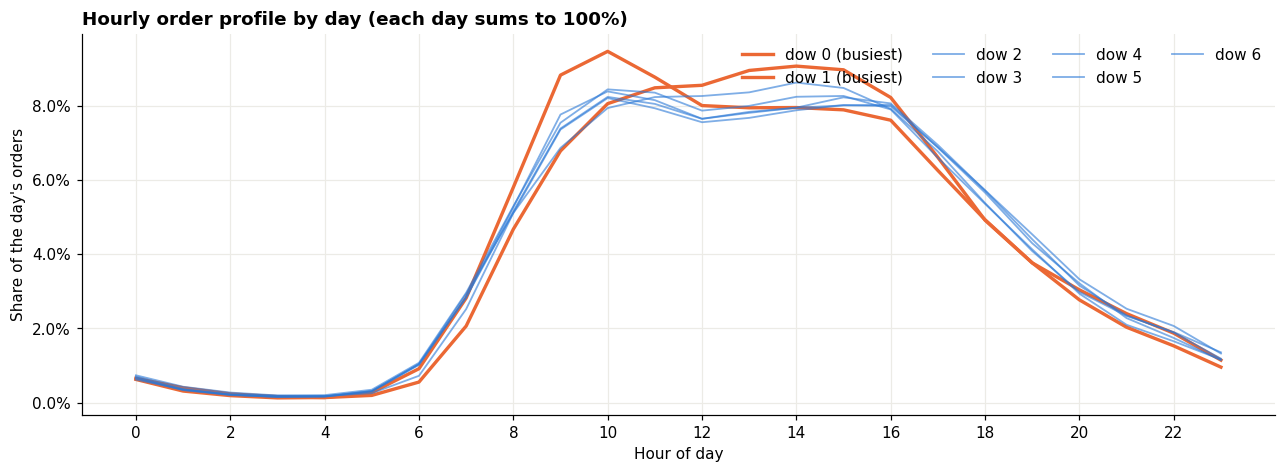

In [12]:
# ==============================
# 5.2.2 Day × Hour heatmap
# ==============================
heat = orders.pivot_table(index="order_dow", columns="order_hour_of_day",
                          values="order_id", aggfunc="count")

fig, ax = plt.subplots(figsize=(14, 4.5))
sns.heatmap(heat, cmap="Blues", ax=ax, cbar_kws={"label": "Orders"}, linewidths=0.3, linecolor="white")
ax.set(title="Orders by day of week × hour of day", xlabel="Hour of day", ylabel="order_dow")
plt.show()

# Hourly profile per day (normalized): do weekdays and weekends have different shapes?
profile = heat.div(heat.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(14, 4.5))
for dow in profile.index:
    is_top2 = dow in by_dow.nlargest(2).index
    ax.plot(profile.columns, profile.loc[dow],
            color=ORANGE if is_top2 else BLUE,
            lw=2.2 if is_top2 else 1.2,
            alpha=1 if is_top2 else 0.6,
            label=f"dow {dow}" + (" (busiest)" if is_top2 else ""))
ax.set(title="Hourly order profile by day (each day sums to 100%)", xlabel="Hour of day", ylabel="Share of the day's orders")
ax.set_xticks(range(0, 24, 2))
pct_axis(ax)
ax.legend(ncol=4, frameon=False)
plt.show()

### 5.2 Time — Key Findings

**1. Two days concentrate much more demand → likely the weekend**
- `order_dow` **0 (17.6%)** and **1 (~17.2%)** together account for **~35% of all orders**, vs. ~28.6% if demand were uniform across days.
- Days 2–6 are stable, between **12.5% and 13.6%** each (day 4 is the quietest at 12.5%).
- This supports the common assumption that **0 and 1 are the weekend days**, although the exact mapping (e.g., Saturday/Sunday vs. Sunday/Monday) cannot be confirmed from the data.

**2. Shopping happens during daytime hours**
- **~80% of orders are placed between 9h and 18h** (10 hours).
- Activity ramps up quickly from 7h, peaks around **10h (~8.4% of orders)**, stays on a **plateau until ~16h**, and declines steadily through the evening.
- Between 0h and 5h, there is almost no activity.

**3. The two busiest days have different hourly shapes**
- **Day 1** has a sharp **morning peak (9–10h)**, the single busiest slot in the heatmap.
- **Day 0** starts later and peaks in the **early afternoon (13–15h)**.
- **Weekdays (2–6)** share a very similar, flatter profile: a morning peak around 10h and a steady plateau until 16h.

**Implications for the business and the recommender:**
- **Timing of communications:** reorder reminders and push notifications should be sent **just before demand peaks** (weekend mornings and early afternoons, and around 9–10h on weekdays).
- **Operations:** weekend daytime peaks require more shopper capacity. Recommendations could even promote **off-peak delivery slots** to balance demand.
- **Temporal context as a feature:** day and hour can be added as **context features** in the model (e.g., an order placed on a weekend may look different from a weekday one). However, since the hourly *shape* is very similar across days, we should expect **time context to be a secondary signal** compared to the customer's own history.
- **Open question for later:** *what* customers buy might also change with the time of day (e.g., breakfast items in the morning). We will check this in the products/reorder analysis.

### 5.3 Baskets: How Many Products per Order?

**Questions:**
- How many products does a typical order contain?
- Is the basket size stable for each customer, or does it vary a lot between orders?
- Does basket size depend on how long the customer waited since their previous order?
- What does this imply for **K** (the number of products we recommend)?

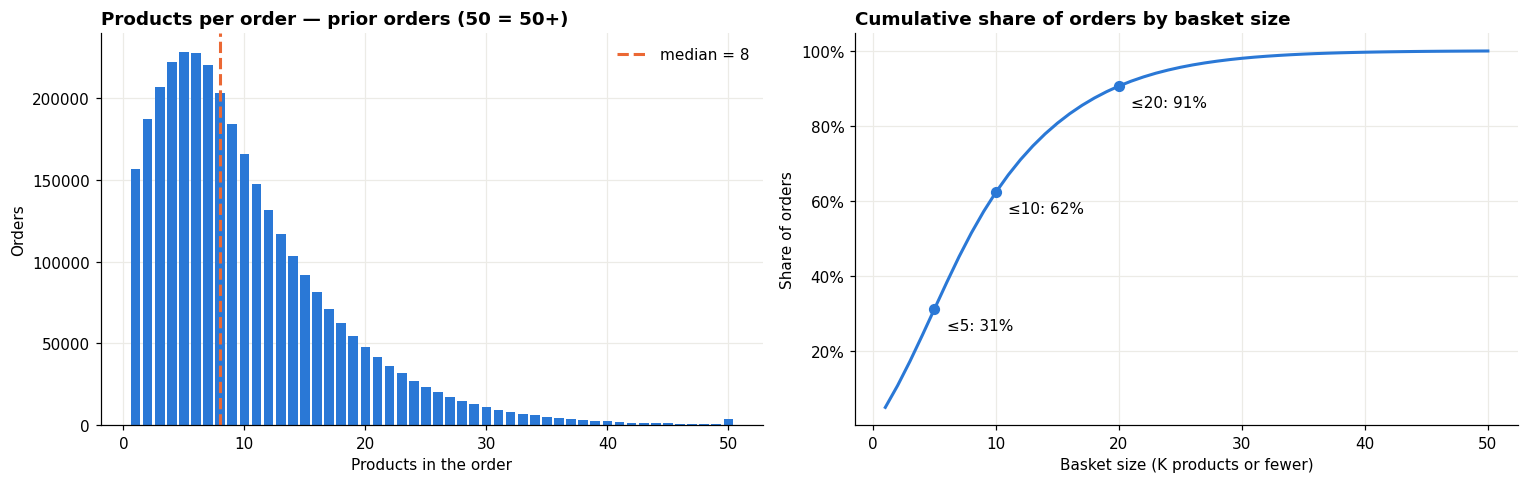

,count,mean,std,min,25%,50%,75%,90%,max
prior,"3,214,874.000",10.089,7.525,1.000,5.000,8.000,14.000,20.000,145.000
train (target),"131,209.000",10.553,7.933,1.000,5.000,9.000,14.000,21.000,80.000


In [13]:
# ==============================
# 5.3.1 Basket size distribution
# ==============================
basket_prior = prior.groupby("order_id").size().rename("basket_size")
basket_train = train.groupby("order_id").size().rename("basket_size")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

b = basket_prior.clip(upper=50).value_counts().sort_index()
axes[0].bar(b.index, b.values, color=BLUE, width=0.8)
axes[0].axvline(basket_prior.median(), color=ORANGE, lw=2, ls="--",
                label=f"median = {basket_prior.median():.0f}")
axes[0].set(title="Products per order — prior orders (50 = 50+)",
            xlabel="Products in the order", ylabel="Orders")
axes[0].legend(frameon=False)

# Cumulative share: what % of orders have K products or fewer?
ks = np.arange(1, 51)
cum_share = [(basket_prior <= k).mean() for k in ks]
axes[1].plot(ks, cum_share, color=BLUE, lw=2)
for k in (5, 10, 20):
    v = (basket_prior <= k).mean()
    axes[1].scatter([k], [v], color=BLUE, s=40, zorder=3)
    axes[1].annotate(f"≤{k}: {v:.0%}", (k, v), xytext=(8, -14), textcoords="offset points")
axes[1].set(title="Cumulative share of orders by basket size",
            xlabel="Basket size (K products or fewer)", ylabel="Share of orders")
pct_axis(axes[1])

plt.tight_layout()
plt.show()

summary = pd.concat([basket_prior.describe(percentiles=[.25, .5, .75, .9]),
                     basket_train.describe(percentiles=[.25, .5, .75, .9])],
                    axis=1, keys=["prior", "train (target)"]).T
display(summary)

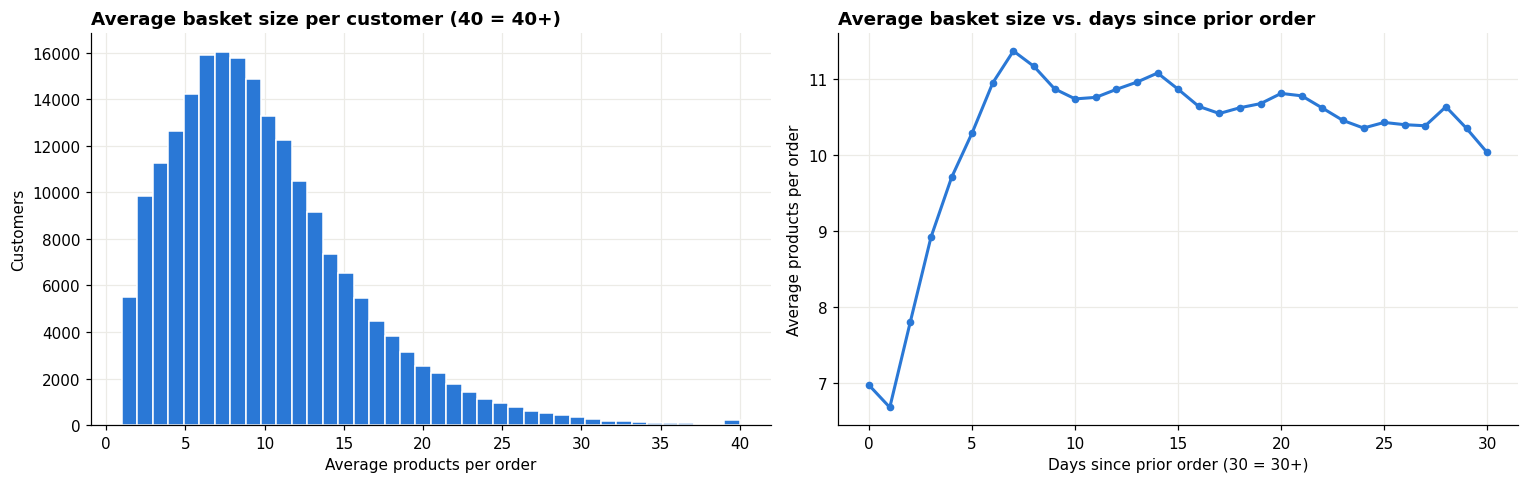

Median of customers' average basket size: 8.9
Median coefficient of variation within a customer: 0.44
Spearman correlation (basket size vs. days since prior): 0.10


In [14]:
# ==============================
# 5.3.2 Basket size by customer and by days since prior order
# ==============================
basket_df = (basket_prior.reset_index()
             .merge(orders[["order_id", "user_id", "days_since_prior_order"]], on="order_id"))

# Stability within each customer: coefficient of variation (std / mean)
per_customer = basket_df.groupby("user_id")["basket_size"].agg(["mean", "std"])
per_customer["cv"] = per_customer["std"] / per_customer["mean"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].hist(per_customer["mean"].clip(upper=40), bins=40, color=BLUE, edgecolor="white")
axes[0].set(title="Average basket size per customer (40 = 40+)",
            xlabel="Average products per order", ylabel="Customers")

by_days = basket_df.groupby("days_since_prior_order")["basket_size"].mean()
axes[1].plot(by_days.index, by_days.values, color=BLUE, lw=2, marker="o", ms=4)
axes[1].set(title="Average basket size vs. days since prior order",
            xlabel="Days since prior order (30 = 30+)", ylabel="Average products per order")

plt.tight_layout()
plt.show()

print(f"Median of customers' average basket size: {per_customer['mean'].median():.1f}")
print(f"Median coefficient of variation within a customer: {per_customer['cv'].median():.2f}")
print(f"Spearman correlation (basket size vs. days since prior): "
      f"{basket_df[['basket_size','days_since_prior_order']].corr(method='spearman').iloc[0,1]:.2f}")

In [15]:
# ==============================
# 5.3.3 Theoretical ceiling of Precision@K and Recall@K
# ==============================
# Even a perfect model cannot exceed these values:
#   - Precision@K ≤ min(basket, K) / K   (small baskets can't fill K slots)
#   - Recall@K    ≤ min(basket, K) / basket   (large baskets can't be fully covered)
ceiling = pd.DataFrame({
    "K": [5, 10, 15, 20],
    "max_precision@K": [np.mean(np.minimum(basket_train, k) / k) for k in (5, 10, 15, 20)],
    "max_recall@K":    [np.mean(np.minimum(basket_train, k) / basket_train) for k in (5, 10, 15, 20)],
    "orders_with_basket_≤_K": [(basket_train <= k).mean() for k in (5, 10, 15, 20)],
}).set_index("K")

display(ceiling.style.format("{:.1%}"))

,max_precision@K,max_recall@K,orders_with_basket_≤_K
K,,,
5,88.8%,62.0%,30.0%
10,73.0%,84.7%,59.7%
15,59.3%,93.7%,78.4%
20,48.7%,97.4%,89.0%


### 5.3 Baskets — Key Findings

**1. A typical order has around 8–10 products**
- Prior orders: **mean 10.1, median 8** products, with half of the orders between **5 and 14** products.
- The distribution is **right-skewed**: the most frequent basket size is **5–6 products**, but a long tail reaches up to 145 products.
- **31%** of orders have ≤5 products, **62%** have ≤10, and **91%** have ≤20.

**2. The target orders look like the historical ones**
- Train orders (the ones we want to predict): **mean 10.6, median 9**, with very similar quartiles (5 / 9 / 14).
- They are only slightly larger than prior orders, so historical behavior is **representative of what we will predict** → no relevant distribution shift.

**3. Metrics have a theoretical ceiling**
Even a *perfect* model is limited by basket size:

| K | Max Precision@K | Max Recall@K | Orders with basket ≤ K |
|---|---|---|---|
| 5 | 88.8% | 62.0% | 30.0% |
| **10** | **73.0%** | **84.7%** | **59.7%** |
| 15 | 59.3% | 93.7% | 78.4% |
| 20 | 48.7% | 97.4% | 89.0% |

- With **K = 10**, a perfect model would reach at most **73% precision**: in ~60% of the orders there are not enough products to fill all 10 slots.
- **Precision and recall move in opposite directions** as K grows: K = 5 maximizes precision (88.8%) but can cover at most 62% of the cart, while K = 20 covers almost the entire cart (97.4%) but caps precision below 50%.

**4. Basket size varies across customers and depends on purchase timing**
- The **median customer averages 8.9 products per order**, but customers differ a lot: most average between 5 and 12 products, while some average 2–3 and others more than 25.
- Within each customer, basket size is **moderately stable**: the median coefficient of variation is **0.44** (e.g., a customer averaging 10 products typically orders between ~6 and ~14). A customer's own average is a good *reference* for how many products to recommend, but not an exact rule.
- Basket size is **not linearly related** to days since the prior order (Spearman = **0.10**, weak), but the curve shows a clear **non-linear pattern**:
  - Orders placed **0–1 days** after the previous one are small (**~7 products**) → **top-up orders**, likely forgotten items or urgent needs.
  - Basket size grows quickly up to a **peak at ~7 days (~11.4 products)**, which is the regular **weekly shopping trip**.
  - After that it stays on a **plateau (~10.5–11 products)** and slightly declines for 30+ days (~10 products).
  - The weak correlation is explained by this shape: the effect is concentrated in the first week and then flattens, so a linear coefficient underestimates it.

**Implications for the recommender:**
- **K = 10** will be our main evaluation setting: it balances both ceilings (73% / 85%), is close to the median basket, and matches what a "Buy it again" section can show on screen. We will also report **K = 5 and K = 20** for sensitivity.
- **Model metrics must be read relative to these ceilings**, not against 100%. For example, a Precision@10 of 35% means reaching roughly half of what is theoretically achievable.
- **The right K depends on the use case:**
  - **Small K (≈5)** → for limited space where every suggestion must be right (e.g., checkout "Forgot something?").
  - **Large K (≈15–20)** → for a pre-filled cart, where covering the whole order matters more.
- **A fixed K is not ideal for every customer.** Someone who buys 4 products and someone who buys 25 need different list lengths → a better approach is a **personalized K** based on each customer's typical basket size (this is also what the Kaggle F1 metric rewards).
- **Order context matters:** a top-up order 1 day after the previous one calls for a few targeted suggestions (what they likely forgot), while a weekly order calls for a fuller list. *Days since prior order* will be a useful **feature** for deciding both K and which products to recommend.

### 5.4 Products: What Do Customers Buy?

**Questions:**
- Which products, aisles and departments concentrate the most purchases?
- How concentrated are sales? Do a few products explain most of the volume (long tail)?
- How many products are rarely bought? → Products that are hard to recommend (item cold start).

**Why it matters:** if a few products dominate, a naive recommender will tend to suggest the same popular items to everyone (**popularity bias**), leaving most of the catalog unseen.

Products purchased at least once: 49,677 of 49,688 in the catalog


,product_name,department,purchases,share_purchases,share_customers
product_id,,,,,
24852,Banana,produce,"472,565",1.46%,35.9%
13176,Bag of Organic Bananas,produce,"379,450",1.17%,30.8%
21137,Organic Strawberries,produce,"264,683",0.82%,28.5%
21903,Organic Baby Spinach,produce,"241,921",0.75%,26.7%
47209,Organic Hass Avocado,produce,"213,584",0.66%,21.1%
47766,Organic Avocado,produce,"176,815",0.55%,20.7%
47626,Large Lemon,produce,"152,657",0.47%,22.5%
16797,Strawberries,produce,"142,951",0.44%,20.9%
26209,Limes,produce,"140,627",0.43%,21.8%


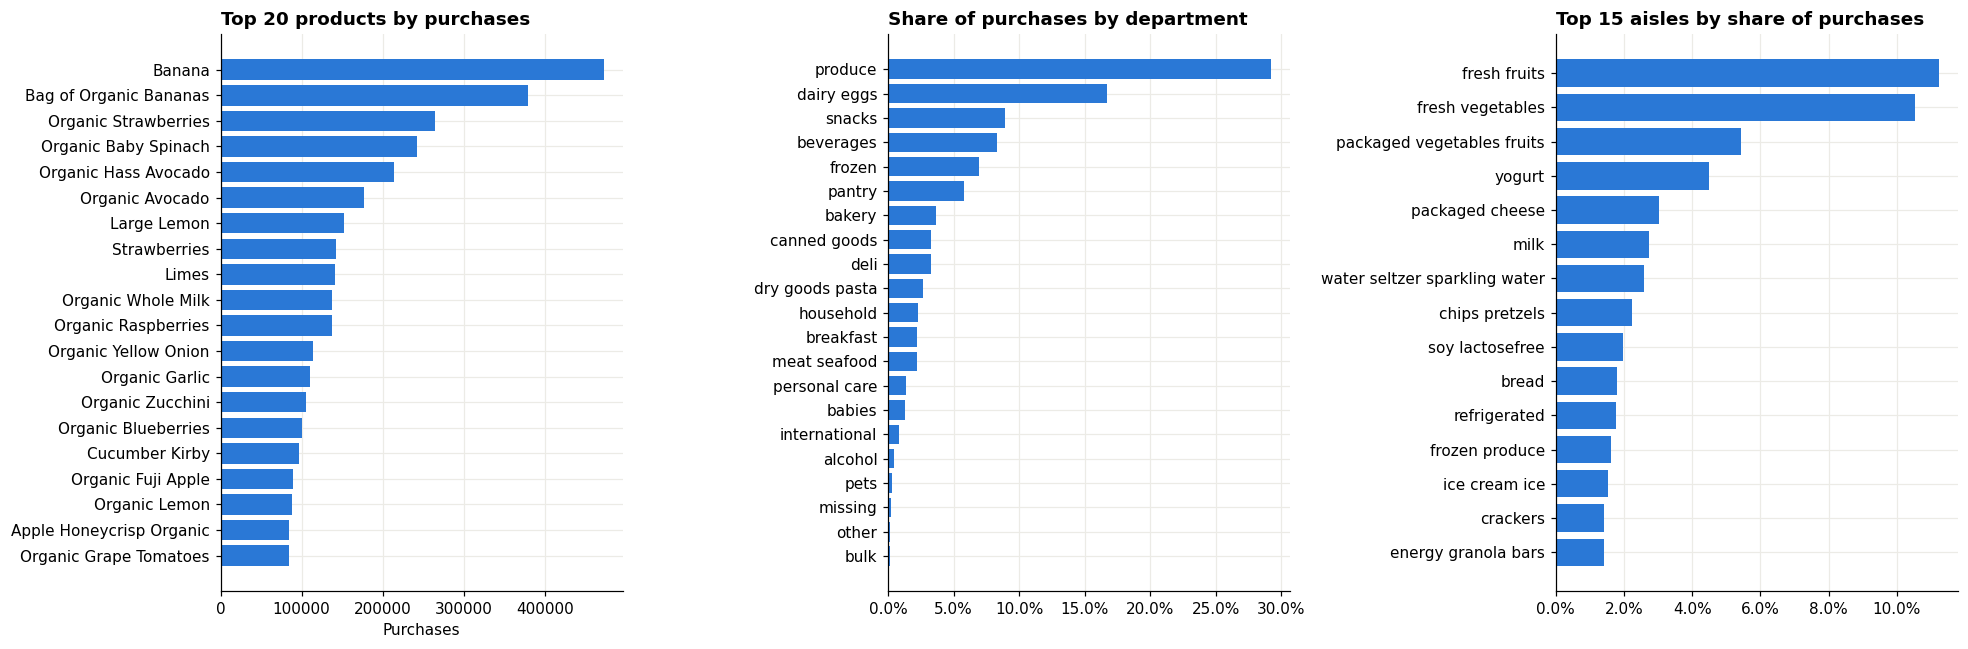

In [16]:
# ==============================
# 5.4.1 Enrich prior with customer info (reused in the next blocks)
# ==============================
prior = prior.merge(
    orders[["order_id", "user_id", "order_number", "order_dow",
            "order_hour_of_day", "days_since_prior_order"]],
    on="order_id", how="left")

# Product-level statistics
product_stats = (prior.groupby("product_id")
                 .agg(purchases=("order_id", "size"),
                      customers=("user_id", "nunique"),
                      reorder_rate=("reordered", "mean"))
                 .join(products.set_index("product_id")[["product_name", "aisle", "department"]])
                 .sort_values("purchases", ascending=False))

total_purchases = product_stats["purchases"].sum()
n_customers = prior["user_id"].nunique()
product_stats["share_purchases"] = product_stats["purchases"] / total_purchases
product_stats["share_customers"] = product_stats["customers"] / n_customers

print(f"Products purchased at least once: {len(product_stats):,} of {len(products):,} in the catalog")
display(product_stats.head(20)[["product_name", "department", "purchases",
                                "share_purchases", "share_customers"]]
        .style.format({"purchases": "{:,}", "share_purchases": "{:.2%}", "share_customers": "{:.1%}"}))

# ==============================
# 5.4.2 Top products, departments and aisles
# ==============================
top20 = product_stats.head(20)
dept_share = product_stats.groupby("department")["purchases"].sum().sort_values() / total_purchases
aisle_share = product_stats.groupby("aisle")["purchases"].sum().sort_values().tail(15) / total_purchases

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

axes[0].barh(top20["product_name"][::-1], top20["purchases"][::-1], color=BLUE)
axes[0].set(title="Top 20 products by purchases", xlabel="Purchases")

axes[1].barh(dept_share.index, dept_share.values, color=BLUE)
axes[1].set(title="Share of purchases by department")
pct_axis(axes[1], "x")

axes[2].barh(aisle_share.index, aisle_share.values, color=BLUE)
axes[2].set(title="Top 15 aisles by share of purchases")
pct_axis(axes[2], "x")

plt.tight_layout()
plt.show()

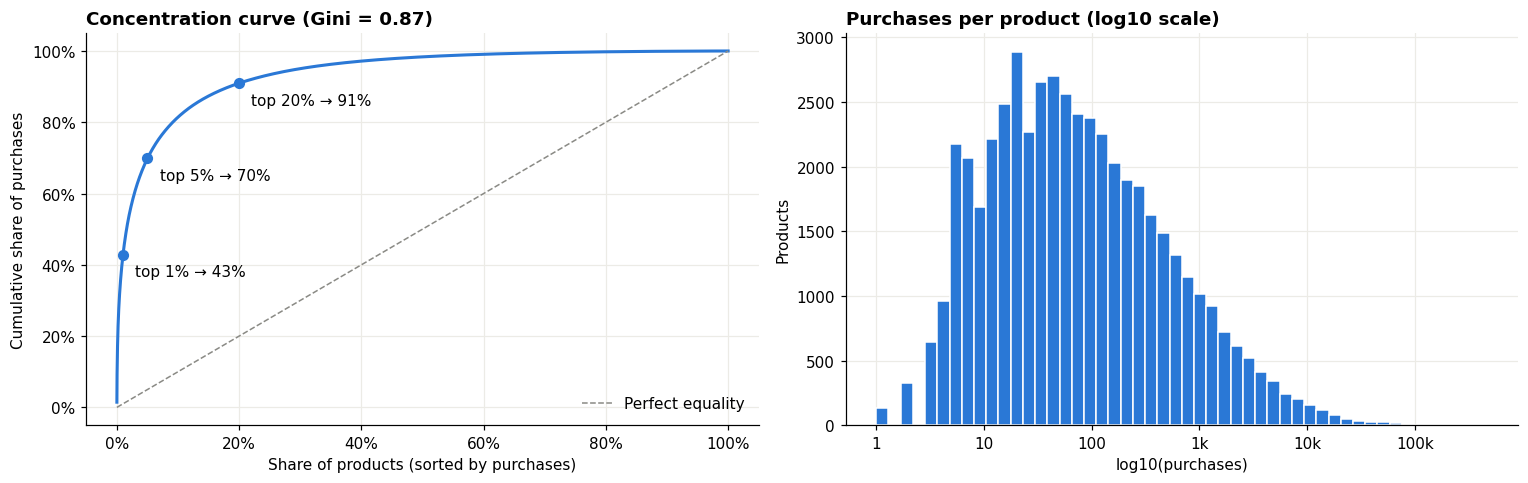

,coverage_target,n_products_needed,share_of_catalog
0,50%,787,1.6%
1,80%,"4,538",9.1%
2,90%,"9,152",18.4%
3,95%,"14,818",29.8%


Products with <  10 purchases: 7,165 (14.4% of catalog)
Products with <  50 purchases: 22,991 (46.3% of catalog)
Products with < 100 purchases: 29,610 (59.6% of catalog)


In [17]:
# ==============================
# 5.4.3 Sales concentration (long tail)
# ==============================
sorted_purchases = product_stats["purchases"].values          # already sorted desc
cum_share = np.cumsum(sorted_purchases) / sorted_purchases.sum()
share_products = np.arange(1, len(sorted_purchases) + 1) / len(sorted_purchases)

# Gini coefficient (0 = all products sell the same, 1 = one product sells everything)
asc = np.sort(sorted_purchases)
gini = 1 - 2 * (np.cumsum(asc) / asc.sum()).mean() + 1 / len(asc)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

axes[0].plot(share_products, cum_share, color=BLUE, lw=2)
axes[0].plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Perfect equality")
for p in (0.01, 0.05, 0.20):
    v = cum_share[int(p * len(cum_share)) - 1]
    axes[0].scatter([p], [v], color=BLUE, s=40, zorder=3)
    axes[0].annotate(f"top {p:.0%} → {v:.0%}", (p, v), xytext=(8, -14), textcoords="offset points")
axes[0].set(title=f"Concentration curve (Gini = {gini:.2f})",
            xlabel="Share of products (sorted by purchases)", ylabel="Cumulative share of purchases")
axes[0].legend(frameon=False, loc="lower right")
pct_axis(axes[0]); pct_axis(axes[0], "x")

# Purchases per product (log scale) → shape of the long tail
axes[1].hist(np.log10(product_stats["purchases"]), bins=50, color=BLUE, edgecolor="white")
axes[1].set(title="Purchases per product (log10 scale)",
            xlabel="log10(purchases)", ylabel="Products")
axes[1].set_xticks(range(0, 6))
axes[1].set_xticklabels(["1", "10", "100", "1k", "10k", "100k"])

plt.tight_layout()
plt.show()

# How many products are needed to cover X% of purchases?
coverage = pd.DataFrame({
    "coverage_target": [0.5, 0.8, 0.9, 0.95],
    "n_products_needed": [int(np.searchsorted(cum_share, t) + 1) for t in (0.5, 0.8, 0.9, 0.95)],
})
coverage["share_of_catalog"] = coverage["n_products_needed"] / len(product_stats)
display(coverage.style.format({"coverage_target": "{:.0%}", "n_products_needed": "{:,}",
                               "share_of_catalog": "{:.1%}"}))

# Rarely purchased products (hard to recommend)
for threshold in (10, 50, 100):
    n = (product_stats["purchases"] < threshold).sum()
    print(f"Products with < {threshold:>3} purchases: {n:,} ({n / len(product_stats):.1%} of catalog)")

### 5.4 Products — Key Findings

**1. Fresh produce dominates, and organic is the norm**
- **49,677 of 49,688 products** (99.98%) were purchased at least once.
- **19 of the top 20 products are from `produce`**, the only exception being *Organic Whole Milk* (dairy eggs).
- **15 of the top 20 are organic**, which suggests a customer base with a strong preference for organic products.
- **Bananas** are the clear #1: *Banana* (1.46% of all purchases, bought by **35.9% of customers**) and *Bag of Organic Bananas* (1.17%, 30.8% of customers).
- At the department level, **produce (~29%)** and **dairy eggs (~17%)** account for **almost half of all purchases**, followed by snacks, beverages and frozen (~7–9% each).
- At the aisle level, **fresh fruits (~11%)** and **fresh vegetables (~10.5%)** lead by a wide margin, followed by packaged vegetables/fruits and yogurt.

**2. Popular products include close substitutes**
- Several top products are near-duplicates: *Banana* vs. *Bag of Organic Bananas*, *Organic Hass Avocado* vs. *Organic Avocado*, *Strawberries* vs. *Organic Strawberries*, *Large Lemon* vs. *Organic Lemon*.
- These are **substitutes, not complements**: a customer usually buys one *or* the other.

**3. Reach vs. purchase intensity**
- Some products are bought by many customers (reach), while others are bought **repeatedly by fewer customers** (intensity).
- Example: *Organic Whole Milk* has about as many purchases as *Limes* (~138k vs. ~141k) but is bought by only **11.3%** of customers vs. **21.8%** → the customers who buy milk **buy it very often**.

**4. Sales are extremely concentrated (long tail)**
- **Gini coefficient = 0.87** (0 = equal sales across products, 1 = one product sells everything).
- The **top 1%** of products accounts for **43%** of purchases, the **top 5%** for **70%**, and the **top 20%** for **91%**.

| Coverage of purchases | Products needed | Share of catalog |
|---|---|---|
| 50% | 787 | 1.6% |
| 80% | 4,538 | 9.1% |
| 90% | 9,152 | 18.4% |
| 95% | 14,818 | 29.8% |

**5. Most of the catalog is rarely purchased**
- On a log scale, the typical product is bought only **tens to a few hundred times** across 3.2M orders.
- **14.4%** of products have fewer than **10** purchases, **46.3%** have fewer than **50**, and **59.6%** have fewer than **100**.

**Implications for the recommender:**
- **Popularity is a strong but naive baseline:** recommending bananas, strawberries and spinach will hit many baskets, but it gives everyone the **same list** and ignores **>99.9% of the catalog**. We will measure **catalog coverage** alongside accuracy to detect this bias.
- **Collaborative models can focus on the head of the catalog:** restricting them to the **top ~5k–10k products** keeps **80–90% of purchases** while making the user × product matrix far smaller and less sparse.
- **The long tail needs a different strategy:** products with very few purchases have too little interaction data for collaborative filtering (**item cold start**). For them, **content-based signals** (aisle, department, product name) are a better option.
- **Substitutes must be handled carefully:** recommending *Banana* to someone who always buys *Bag of Organic Bananas* is redundant. Product **attributes** (organic, aisle) and **co-purchase patterns** help distinguish substitutes from complements.
- **Customer preferences are visible in the data:** the strong presence of organic products suggests that attributes like **"organic share of the customer's purchases"** could be useful features for personalization.
- **Reach and intensity are different signals:** for "Buy it again", what matters is how often **each customer** repurchases a product, not only how popular it is overall. This leads directly to the next block: **reorders**.

### 5.5 Reorders: How Much of the Cart Is Repeated?

**Questions:**
- What share of purchased products are **reorders**?
- In the order we want to predict (`train`), how many products had the customer **already bought before**? → This sets the ceiling of a "Buy it again" approach.
- Which products and departments are reordered the most?
- How does reordering relate to **cart position**, **days since prior order** and **customer tenure**?
- How many products does a customer buy **only once** vs. repeatedly?

**Note:** in a customer's **first order** every product is new by definition (`reordered = 0`), so reorder rates are computed **excluding first orders** where relevant.

Reorder rate — prior (all orders):          59.0%
Reorder rate — prior (excluding 1st order): 63.0%
Reorder rate — train (target orders):       59.9%

Customer–product pairs in history: 13,307,953
Products in target orders already bought before: 59.9%
Consistency check (in_history == reordered flag): 100.00%

Target orders with NO reorders (all products new):  6.6%
Target orders with ONLY reorders (no new products): 18.4%
Median share of each target order already in history: 63.2%


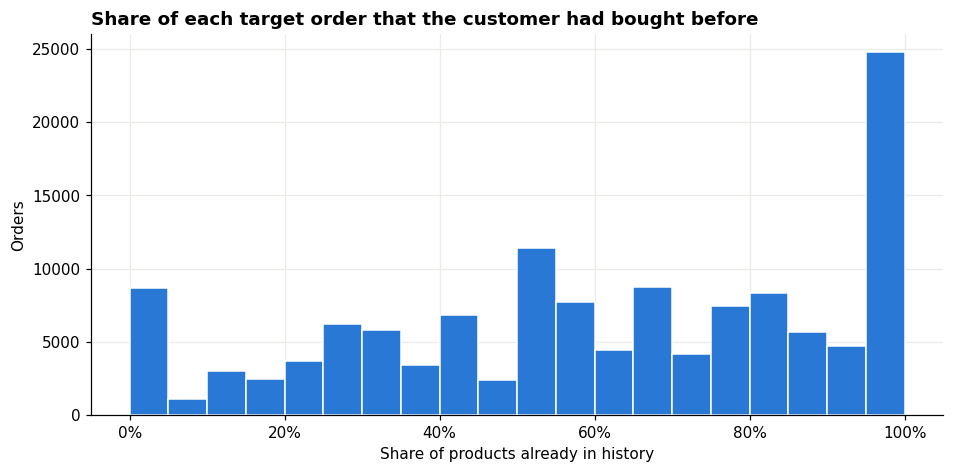

In [18]:
# ==============================
# 5.5.1 Global reorder rate
# ==============================
print(f"Reorder rate — prior (all orders):          {prior['reordered'].mean():.1%}")
print(f"Reorder rate — prior (excluding 1st order): {prior.loc[prior['order_number'] > 1, 'reordered'].mean():.1%}")
print(f"Reorder rate — train (target orders):       {train['reordered'].mean():.1%}")

# ==============================
# 5.5.2 Customer × product history (reused later by the models)
# ==============================
user_product = (prior.groupby(["user_id", "product_id"])
                .agg(times_bought=("order_id", "size"),
                     last_order_number=("order_number", "max"))
                .reset_index())
print(f"\nCustomer–product pairs in history: {len(user_product):,}")

# ==============================
# 5.5.3 Was each product in the target order already in the customer's history?
# ==============================
train_u = (train.merge(orders[["order_id", "user_id"]], on="order_id")
                .merge(user_product[["user_id", "product_id"]].assign(in_history=1),
                       on=["user_id", "product_id"], how="left"))
train_u["in_history"] = train_u["in_history"].fillna(0).astype("int8")

print(f"Products in target orders already bought before: {train_u['in_history'].mean():.1%}")
print(f"Consistency check (in_history == reordered flag): {(train_u['in_history'] == train_u['reordered']).mean():.2%}")

per_order = train_u.groupby("order_id")["in_history"].agg(["sum", "count", "mean"])
print(f"\nTarget orders with NO reorders (all products new):  {(per_order['sum'] == 0).mean():.1%}")
print(f"Target orders with ONLY reorders (no new products): {(per_order['mean'] == 1).mean():.1%}")
print(f"Median share of each target order already in history: {per_order['mean'].median():.1%}")

fig, ax = plt.subplots()
ax.hist(per_order["mean"], bins=20, color=BLUE, edgecolor="white")
ax.set(title="Share of each target order that the customer had bought before",
       xlabel="Share of products already in history", ylabel="Orders")
pct_axis(ax, "x")
plt.show()

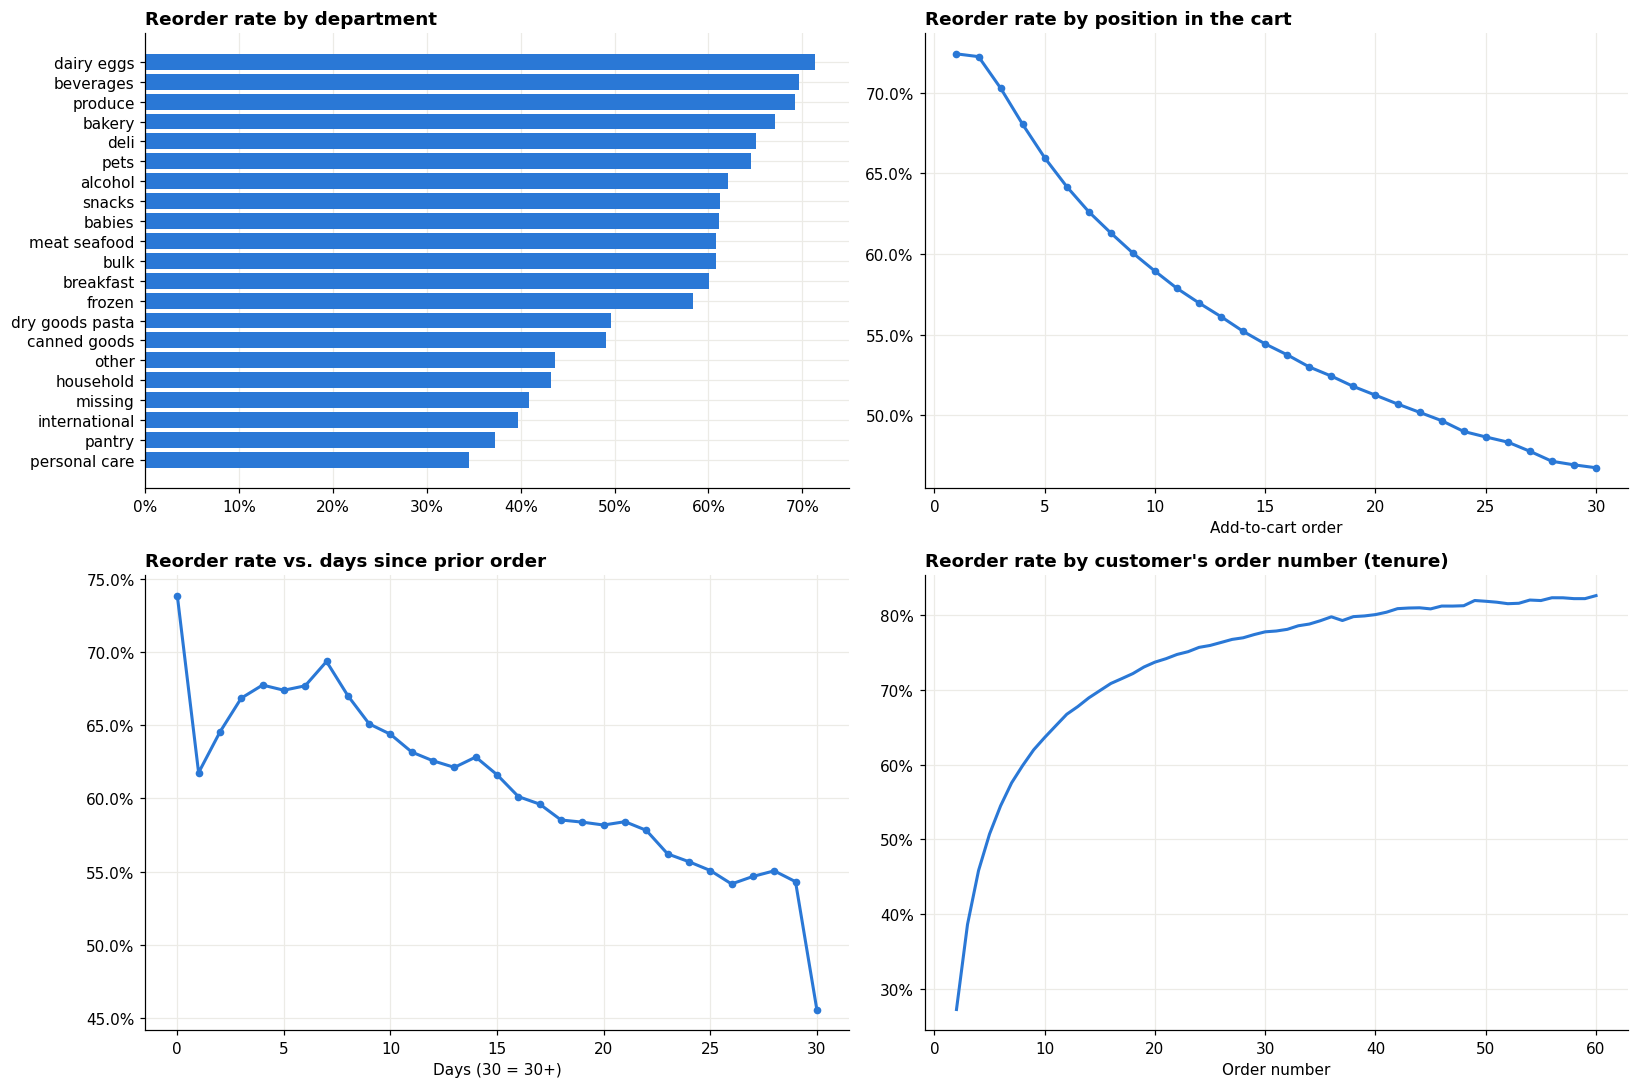

In [19]:
# ==============================
# 5.5.4 Reorder rate by department, cart position, days since prior and tenure
# ==============================
p = prior[prior["order_number"] > 1]   # exclude first orders

dept_id = p["product_id"].map(products.set_index("product_id")["department_id"])
dept_rr = (p["reordered"].groupby(dept_id).mean()
           .rename(index=departments.set_index("department_id")["department"])
           .sort_values())

pos_rr  = p[p["add_to_cart_order"] <= 30].groupby("add_to_cart_order")["reordered"].mean()
days_rr = p.groupby("days_since_prior_order")["reordered"].mean()
num_rr  = p[p["order_number"] <= 60].groupby("order_number")["reordered"].mean()

fig, axes = plt.subplots(2, 2, figsize=(15, 10))

axes[0, 0].barh(dept_rr.index, dept_rr.values, color=BLUE)
axes[0, 0].set(title="Reorder rate by department")
pct_axis(axes[0, 0], "x")

axes[0, 1].plot(pos_rr.index, pos_rr.values, color=BLUE, lw=2, marker="o", ms=4)
axes[0, 1].set(title="Reorder rate by position in the cart", xlabel="Add-to-cart order")
pct_axis(axes[0, 1])

axes[1, 0].plot(days_rr.index, days_rr.values, color=BLUE, lw=2, marker="o", ms=4)
axes[1, 0].set(title="Reorder rate vs. days since prior order", xlabel="Days (30 = 30+)")
pct_axis(axes[1, 0])

axes[1, 1].plot(num_rr.index, num_rr.values, color=BLUE, lw=2)
axes[1, 1].set(title="Reorder rate by customer's order number (tenure)", xlabel="Order number")
pct_axis(axes[1, 1])

plt.tight_layout()
plt.show()

Top 15 products by reorder rate (≥1,000 purchases):


,product_name,department,purchases,reorder_rate
product_id,,,,
9292,Half And Half Ultra Pasteurized,dairy eggs,"2,921",86.2%
45504,Whole Organic Omega 3 Milk,dairy eggs,"9,108",86.0%
43394,Organic Lactose Free Whole Milk,dairy eggs,"8,477",85.9%
5514,Organic Homogenized Whole Milk,dairy eggs,"3,970",85.8%
47231,Ultra-Purified Water,beverages,"1,489",85.8%
29447,"Milk, Organic, Vitamin D",dairy eggs,"20,198",85.4%
38689,Organic Reduced Fat Milk,dairy eggs,"35,663",85.1%
34197,Goat Milk,dairy eggs,"5,185",85.0%
24852,Banana,produce,"472,565",84.4%


Bottom 10 products by reorder rate (≥1,000 purchases):


,product_name,department,purchases,reorder_rate
product_id,,,,
42421,Organic Ground Nutmeg,pantry,"1,055",3.5%
35838,Cumin Seed,pantry,"1,009",5.5%
8203,Ground Ginger,pantry,"1,726",5.9%
2380,Cayenne Pepper,pantry,"1,683",6.2%
28805,100% Pure Corn Starch,pantry,"1,165",7.5%
12113,Corn Starch,pantry,"1,831",7.5%
35973,Paprika,pantry,"2,837",7.7%
33884,Bay Leaves,pantry,"2,898",7.7%
5605,Sesame Seed,pantry,"1,968",7.9%


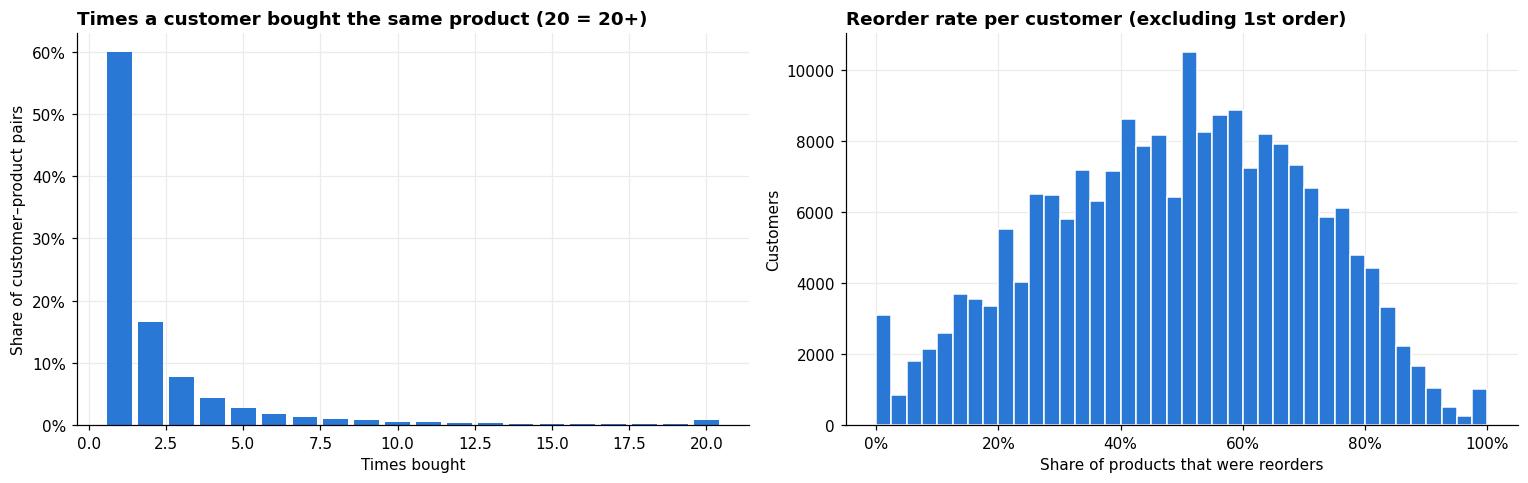

Customer–product pairs bought only once: 60.0%
Median reorder rate per customer: 50.0%


In [20]:
# ==============================
# 5.5.5 Product level: which products are reordered the most?
# ==============================
popular = product_stats[product_stats["purchases"] >= 1000]

print("Top 15 products by reorder rate (≥1,000 purchases):")
display(popular.nlargest(15, "reorder_rate")[["product_name", "department", "purchases", "reorder_rate"]]
        .style.format({"purchases": "{:,}", "reorder_rate": "{:.1%}"}))

print("Bottom 10 products by reorder rate (≥1,000 purchases):")
display(popular.nsmallest(10, "reorder_rate")[["product_name", "department", "purchases", "reorder_rate"]]
        .style.format({"purchases": "{:,}", "reorder_rate": "{:.1%}"}))

# ==============================
# 5.5.6 Customer level: one-off vs. repeated products
# ==============================
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# How many times does a customer buy the same product?
tb = user_product["times_bought"].clip(upper=20).value_counts(normalize=True).sort_index()
axes[0].bar(tb.index, tb.values, color=BLUE, width=0.8)
axes[0].set(title="Times a customer bought the same product (20 = 20+)",
            xlabel="Times bought", ylabel="Share of customer–product pairs")
pct_axis(axes[0])

# Each customer's reorder ratio (excluding first order)
cust_rr = p.groupby("user_id")["reordered"].mean()
axes[1].hist(cust_rr, bins=40, color=BLUE, edgecolor="white")
axes[1].set(title="Reorder rate per customer (excluding 1st order)",
            xlabel="Share of products that were reorders", ylabel="Customers")
pct_axis(axes[1], "x")

plt.tight_layout()
plt.show()

print(f"Customer–product pairs bought only once: {(user_product['times_bought'] == 1).mean():.1%}")
print(f"Median reorder rate per customer: {cust_rr.median():.1%}")

### 5.5 Reorders — Key Findings

**1. Most of what customers buy, they have bought before**
| Metric | Value |
|---|---|
| Reorder rate — prior (all orders) | 59.0% |
| Reorder rate — prior (excluding 1st order) | **63.0%** |
| Reorder rate — train (target orders) | 59.9% |

- Around **6 out of 10 products** in an order are repeat purchases. Excluding first orders (where everything is new by definition), the rate rises to **63%**.
- The target orders behave like the historical ones (59.9%) → consistent behavior over time.
- The history contains **13.3M customer–product pairs**, the base for personalized models.

**2. A "Buy it again" model can cover at most ~60% of the next order**
- **59.9%** of the products in the target orders had **already been bought** by that customer (the `reordered` flag matches our history check 100%, which validates the data).
- At the order level:
  - Median share of each order already in history: **63.2%**.
  - **18.4%** of orders contain **only reorders** → for them, a perfect "Buy it again" model could cover the whole cart.
  - **6.6%** of orders contain **only new products** → no history-based model can get any of them right.
- The histogram shows spikes (0%, 50%, ~67%, 100%) because many baskets are small, so only a few fractions are possible.
- → History is the **dominant signal**, but **~40% of purchased products are new to the customer**. Covering them requires **discovery** (collaborative filtering, popularity, co-purchases).

**3. Staples vs. occasional categories**
- **Highest reorder rates:** dairy eggs (~71%), beverages (~70%), produce (~69%), bakery (~67%), deli (~65%), pets (~64%) → **perishable, everyday staples**.
- **Lowest reorder rates:** personal care (~34%), pantry (~37%), international (~40%), household (~43%), canned goods and dry goods/pasta (~49–50%) → **long-lasting or occasional products**, bought less often or with more variety.

**4. What drives a reorder**
- **Cart position:** products added **first** are reordered **~72%** of the time, falling steadily to **~47%** by position 30 → customers add their **staples first** and explore later in the cart.
- **Days since prior order:**
  - Orders placed the **same day (0 days)** have the highest reorder rate (**~74%**), likely repeated or split orders.
  - It drops at **1 day (~62%)**, when top-up orders bring in different products, then peaks again at **~7 days (~69%)**, the weekly routine.
  - From there it **declines steadily**, to **~54%** at 29 days and **~45%** at 30+ days → the longer a customer is away, the less their next order resembles their past ones.
- **Customer tenure:** the reorder rate grows from **~27% on the 2nd order** to **~70% by order ~16** and **~80%+ after order ~35**. Customers **settle into a routine** over time. Part of this effect is mechanical: the more orders a customer has, the more products are already in their history.

**5. Product and customer-level patterns**
- **Milk is the most "loyal" product:** among products with ≥1,000 purchases, **14 of the top 15 by reorder rate are milk variants** (organic, lactose-free, goat, omega-3, reduced fat…), all between **83% and 86%**. The other one is *Ultra-Purified Water* (85.8%).
  - Even niche variants (goat milk, lactose-free) are reordered at very high rates → once customers choose **their** variant, they stick to it.
- **Banana is both the most popular and one of the most reordered products** (472k purchases, **84.4%** reorder rate): a universal staple.
- **Spices and baking ingredients are almost never reordered:** the bottom 10 are all **pantry** items, between **3.5% and 7.9%** (nutmeg, cumin, ginger, cayenne, corn starch, paprika, bay leaves, sesame). A jar lasts for months, so these are bought once and rarely repeated within the observed period.
- **Most customer–product pairs are one-offs:** **60%** were bought **only once**, ~17% twice, ~8% three times, and only a small tail is bought 10+ times. → Each customer has a **small core of staples** surrounded by many occasional purchases.
- **Customers differ in how routine they are:** the **median customer reorder rate is 50%** (below the global 63%, because heavy users reorder more and weigh more in the global figure). The distribution is wide:
  - Most customers fall between **30% and 70%**.
  - A group of ~3k customers **never reorders** (explorers), and a few reorder almost everything (strict routine).

**Implications for the recommender:**
- **"Buy it again" is the core use case:** with ~60% of the next order coming from history, ranking the customer's own past products well is the most valuable task.
- **…but it is not enough:** the ~40% of new products sets a hard ceiling for history-only models. A **hybrid approach** (history + discovery) is needed to go beyond it.
- **Not everything in the history should be recommended:** since 60% of past products were one-off purchases, recommending the entire history would add a lot of noise. Products must be **ranked**, not just listed.
- **Strong features for ranking past products:**
  - **Frequency:** how many times the customer bought the product.
  - **Recency:** how many orders ago it was last bought (time-decay).
  - **Typical cart position:** products usually added first are the customer's staples.
  - **Product reorder rate** and **department**: milk, bananas or produce are much more likely to be repeated than spices, personal care or pantry items.
  - **Days since prior order:** recommendations should lean more on history for weekly shoppers and include more discovery after long gaps.
- **The customer's own reorder propensity sets the mix:** routine customers (high reorder rate) should get mostly "Buy it again" suggestions, while explorers (low reorder rate) should get more **discovery** recommendations. *(Hypothesis tested in M5, section 7.6: rejected offline.)*
- **Low-reorder products belong to other surfaces:** spices or pantry items are poor "Buy it again" candidates, but they can be suggested through **complementary or contextual recommendations** (e.g., related to recipes or other products in the cart).
- **New customers need a different strategy:** with only ~27% reorders on the 2nd order, early-stage customers benefit more from **popularity and collaborative signals** than from their short history.
- **"None" orders exist:** 6.6% of orders have no reorders at all. In the Kaggle formulation, predicting *"None"* for these customers is part of the problem.

### 5.5b Purchase Cycles: Does a Product Become "Due"?

**Hypothesis:** each customer has a personal repurchase cycle for each product (e.g., milk every week, detergent every month). If enough time has passed since the last purchase relative to that cycle, the product is **"due"** and is more likely to appear in the next order.

We measure it with a **due ratio** for each customer–product pair:

$$\text{due ratio} = \frac{\text{days since the customer last bought the product}}{\text{customer's average interval between purchases of that product}}$$

- **≈ 0.3** → bought recently, probably not needed yet.
- **≈ 1** → the product is due.
- **> 1** → overdue: either the customer needs it now… or they **stopped buying it** (switched to a substitute, lost interest).

**Caveats:**
- Requires **at least 2 purchases** of the product (60% of customer–product pairs are one-offs).
- Days are reconstructed by accumulating `days_since_prior_order`, which is **capped at 30**, so long gaps are underestimated.

**Test:** for each customer in `train`, take the products they bought 2+ times, compute the due ratio at the moment of the target order, and check how often each product is actually bought.

In [21]:
# ==============================
# 5.5b.1 Reconstruct a timeline (cumulative days per customer)
# ==============================
orders = orders.sort_values(["user_id", "order_number"])
orders["cum_days"] = (orders["days_since_prior_order"].fillna(0)
                      .groupby(orders["user_id"]).cumsum().astype("float32"))

prior["cum_days"] = prior["order_id"].map(orders.set_index("order_id")["cum_days"]).astype("float32")

# ==============================
# 5.5b.2 Purchase cycle per customer–product (bought 2+ times)
# ==============================
cycle = (prior.groupby(["user_id", "product_id"])["cum_days"]
         .agg(n_purchases="size", first_day="min", last_day="max")
         .reset_index())
cycle = cycle[cycle["n_purchases"] >= 2].copy()
cycle["avg_interval"] = (cycle["last_day"] - cycle["first_day"]) / (cycle["n_purchases"] - 1)
cycle = cycle[cycle["avg_interval"] > 0]

# ==============================
# 5.5b.3 Due ratio at the moment of the target (train) order
# ==============================
target = (orders.loc[orders["eval_set"] == "train", ["user_id", "cum_days"]]
          .rename(columns={"cum_days": "target_day"}))

cand = cycle.merge(target, on="user_id")                     # only train customers
cand["days_since_last"] = cand["target_day"] - cand["last_day"]
cand["due_ratio"] = cand["days_since_last"] / cand["avg_interval"]

bought = train_u[["user_id", "product_id"]].assign(bought=1)
cand = cand.merge(bought, on=["user_id", "product_id"], how="left")
cand["bought"] = cand["bought"].fillna(0).astype("int8")

print(f"Candidate customer–product pairs (bought 2+ times): {len(cand):,}")
print(f"Base purchase rate of these candidates: {cand['bought'].mean():.1%}")

reorders_in_target = train_u["in_history"].sum()
covered = cand["bought"].sum()
print(f"Share of target reorders covered by 2+ purchase products: {covered / reorders_in_target:.1%}")

Candidate customer–product pairs (bought 2+ times): 3,362,036
Base purchase rate of these candidates: 17.5%
Share of target reorders covered by 2+ purchase products: 70.9%


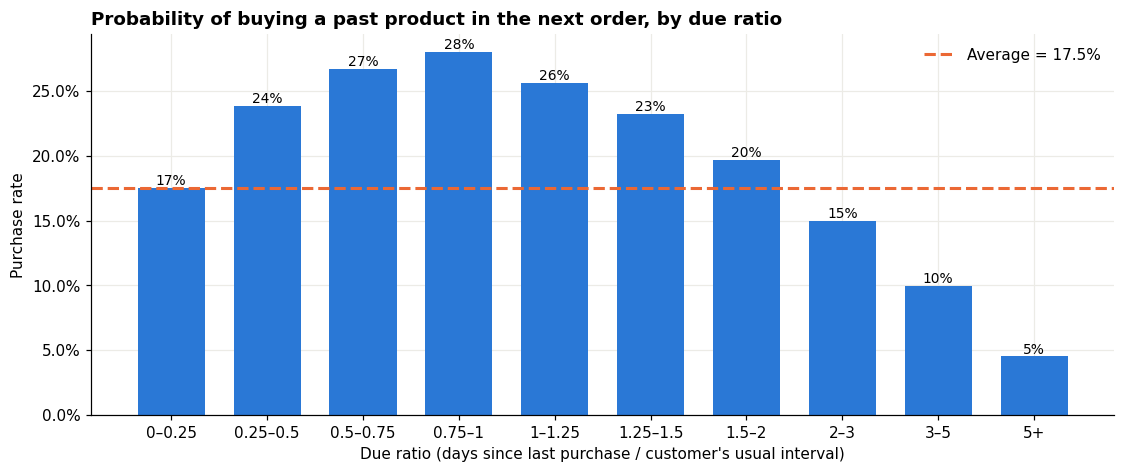

,pairs,purchase_rate,share_pairs
due_bucket,,,
0–0.25,"335,706",17.5%,10.0%
0.25–0.5,"392,901",23.8%,11.7%
0.5–0.75,"329,018",26.7%,9.8%
0.75–1,"292,526",28.0%,8.7%
1–1.25,"212,016",25.6%,6.3%
1.25–1.5,"180,083",23.2%,5.4%
1.5–2,"272,795",19.7%,8.1%
2–3,"340,298",15.0%,10.1%
3–5,"354,417",10.0%,10.5%


In [22]:
# ==============================
# 5.5b.4 Purchase probability vs. due ratio
# ==============================
bins   = [0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5, 2, 3, 5, np.inf]
labels = ["0–0.25", "0.25–0.5", "0.5–0.75", "0.75–1", "1–1.25",
          "1.25–1.5", "1.5–2", "2–3", "3–5", "5+"]
cand["due_bucket"] = pd.cut(cand["due_ratio"], bins=bins, labels=labels, include_lowest=True)

due_table = cand.groupby("due_bucket", observed=True).agg(
    pairs=("bought", "size"), purchase_rate=("bought", "mean"))
due_table["share_pairs"] = due_table["pairs"] / due_table["pairs"].sum()

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.bar(due_table.index.astype(str), due_table["purchase_rate"], color=BLUE, width=0.7)
ax.axhline(cand["bought"].mean(), color=ORANGE, ls="--", lw=2,
           label=f"Average = {cand['bought'].mean():.1%}")
for i, v in enumerate(due_table["purchase_rate"]):
    ax.text(i, v, f"{v:.0%}", ha="center", va="bottom", fontsize=9)
ax.set(title="Probability of buying a past product in the next order, by due ratio",
       xlabel="Due ratio (days since last purchase / customer's usual interval)",
       ylabel="Purchase rate")
pct_axis(ax)
ax.legend(frameon=False)
plt.show()

display(due_table.style.format({"pairs": "{:,}", "purchase_rate": "{:.1%}", "share_pairs": "{:.1%}"}))

### 5.5b Purchase Cycles — Key Findings

**1. Most reorders come from products with a measurable cycle**
- **3.36M candidate customer–product pairs** (products bought 2+ times) for the train customers → **~26 candidates per customer** on average.
- Base purchase rate of these candidates in the next order: **17.5%** (roughly 1 in 6).
- These products account for **70.9% of all reorders** in the target orders. The remaining 29.1% are products the customer had bought **only once** (no personal cycle can be computed for them).
- Combined with the reorder rate (59.9%), purchase cycles can explain **~42% of everything a customer buys** in their next order.

**2. The hypothesis holds: products become "due"**

| Due ratio | Purchase rate | Share of pairs |
|---|---|---|
| 0–0.25 (just bought) | 17.5% | 10.0% |
| 0.25–0.5 | 23.8% | 11.7% |
| 0.5–0.75 | 26.7% | 9.8% |
| **0.75–1 (due)** | **28.0%** | 8.7% |
| 1–1.25 | 25.6% | 6.3% |
| 1.25–1.5 | 23.2% | 5.4% |
| 1.5–2 | 19.7% | 8.1% |
| 2–3 | 15.0% | 10.1% |
| 3–5 | 10.0% | 10.5% |
| **5+ (long overdue)** | **4.5%** | **19.4%** |

- The relationship has an **inverted-U shape**: purchase probability rises as the product approaches its usual cycle, peaks at **0.75–1 (28%, 1.6× the average)**, and then falls.
- The peak occurs **slightly before** the cycle is complete: customers tend to **restock before running out**. (The average interval may also be slightly inflated by occasional long gaps.)

**3. "Overdue" means needed — but only for a short window**
- Right after the cycle is complete (ratio **1–1.5**), the probability is still high (**23–26%**) → a missed purchase is likely to happen in the next order.
- Beyond **~2× the usual cycle**, probability drops below average, down to **4.5%** for ratios above 5 → the customer most likely **stopped buying the product** (switched to a substitute, changed habits, or buys it elsewhere).
- This "abandoned" group is large: **19.4% of all candidates** have a due ratio above 5.

**Implications for the recommender:**
- **The due ratio is a promising ranking feature** for "Buy it again". It captures **timing**, which frequency alone does not: a product bought 20 times is not useful if it was bought yesterday. *(Tested later in M2b, M6 and the ablation in section 7.9: once frequency and recency are included, its incremental value turned out to be small, ~0.3% F1.)*
- **Filtering long-overdue products could improve precision:** excluding or down-weighting candidates with a due ratio above ~3 removes ~30% of the candidates while keeping the ones most likely to be bought.
- **The relationship is non-linear**, so it should enter the model either as **buckets** or through a model that captures non-linearities (e.g., gradient boosting), not as a simple linear term.
- **Reorder reminders have a clear optimal window:** notify when the due ratio is around **0.75–1.25**. Earlier, the customer still has the product; much later, they have probably moved on.
- **Products bought only once (29% of reorders)** need a fallback: the **average cycle of the product across all customers** can replace the personal cycle.
- **Caveat:** timelines are reconstructed from `days_since_prior_order`, which is capped at 30 days, so cycles for infrequent customers are underestimated. A version measured in **number of orders** instead of days would be a useful robustness check.

### 5.6 Co-purchases: Which Products Are Bought Together?

**Questions:**
- Which product pairs appear together most often in the same order?
- Which pairs are **truly associated** (bought together more than expected by chance), and which are just two popular products?
- Are strong associations **complements** (e.g., tortillas + salsa) or **variants/substitutes** of the same product (e.g., two yogurt flavors)?

**Association rule metrics** for a pair A → B:

| Metric | Formula | Meaning |
|---|---|---|
| **Support** | P(A and B) | How often the pair appears together (popularity of the pair) |
| **Confidence** | P(B \| A) | Of the orders with A, what share also has B |
| **Lift** | P(A and B) / (P(A) · P(B)) | How much more often they appear together than if they were independent. **Lift > 1** = positive association |

To keep the computation manageable, we use the **top 2,000 products** by purchases and a sparse **order × product** matrix.

In [23]:
# ==============================
# 5.6.1 Order × product matrix (top products)
# ==============================
from scipy import sparse

TOP_N_RULES = 2_000
MIN_COOC = 200            # minimum number of orders containing the pair

top_ids = product_stats.index[:TOP_N_RULES].to_numpy()
pid_to_col = pd.Series(np.arange(TOP_N_RULES), index=top_ids)

pr = prior.loc[prior["product_id"].isin(top_ids), ["order_id", "product_id"]]
row_codes, row_uniques = pd.factorize(pr["order_id"])
O = sparse.csr_matrix(
    (np.ones(len(pr), dtype=np.float32), (row_codes, pr["product_id"].map(pid_to_col).values)),
    shape=(len(row_uniques), TOP_N_RULES))

N_ORDERS = len(basket_prior)                                   # all prior orders
count = product_stats.loc[top_ids, "purchases"].values         # orders containing each product

print(f"Top {TOP_N_RULES:,} products cover {product_stats['share_purchases'].iloc[:TOP_N_RULES].sum():.1%} of purchases")
print(f"Order × product matrix: {O.shape[0]:,} × {O.shape[1]:,} | non-zeros: {O.nnz:,}")

# ==============================
# 5.6.2 Co-occurrence counts and association metrics
# ==============================
C = sparse.triu(O.T @ O, k=1).tocoo()          # upper triangle → each pair once

rules = pd.DataFrame({"a": C.row, "b": C.col, "n_ab": C.data.astype(np.int64)})
rules = rules[rules["n_ab"] >= MIN_COOC].copy()

n_a, n_b = count[rules["a"]], count[rules["b"]]
rules["support"]  = rules["n_ab"] / N_ORDERS
rules["conf_a_b"] = rules["n_ab"] / n_a
rules["conf_b_a"] = rules["n_ab"] / n_b
rules["lift"]     = rules["n_ab"] * N_ORDERS / (n_a * n_b)

# Product info
info = products.set_index("product_id")
for side in ("a", "b"):
    pid = top_ids[rules[side]]
    rules[f"product_{side}"] = info.loc[pid, "product_name"].values
    rules[f"aisle_{side}"]   = info.loc[pid, "aisle"].values
    rules[f"dept_{side}"]    = info.loc[pid, "department"].values
rules["same_aisle"] = rules["aisle_a"] == rules["aisle_b"]

print(f"\nPairs with ≥ {MIN_COOC} co-occurrences: {len(rules):,}")
print(f"Pairs with lift > 1 (positive association): {(rules['lift'] > 1).mean():.1%}")

Top 2,000 products cover 66.0% of purchases
Order × product matrix: 3,071,259 × 2,000 | non-zeros: 21,415,760

Pairs with ≥ 200 co-occurrences: 93,628
Pairs with lift > 1 (positive association): 94.9%


Top 15 pairs by SUPPORT (most frequent together):


,product_a,product_b,n_ab,support,conf_a_b,conf_b_a,lift,same_aisle
9,Bag of Organic Bananas,Organic Hass Avocado,"62,341",1.94%,16.4%,29.2%,2.47,True
1,Bag of Organic Bananas,Organic Strawberries,"61,628",1.92%,16.2%,23.3%,1.97,True
2,Banana,Organic Strawberries,"56,156",1.75%,11.9%,21.2%,1.44,True
14,Banana,Organic Avocado,"53,395",1.66%,11.3%,30.2%,2.05,True
5,Banana,Organic Baby Spinach,"51,395",1.60%,10.9%,21.2%,1.45,False
3,Bag of Organic Bananas,Organic Baby Spinach,"50,372",1.57%,13.3%,20.8%,1.76,False
27,Banana,Strawberries,"41,232",1.28%,8.7%,28.8%,1.96,True
19,Banana,Large Lemon,"40,880",1.27%,8.7%,26.8%,1.82,True
6,Organic Strawberries,Organic Hass Avocado,"40,794",1.27%,15.4%,19.1%,2.32,True
54,Bag of Organic Bananas,Organic Raspberries,"40,503",1.26%,10.7%,29.6%,2.50,False


Top 15 pairs by LIFT (strongest association, ≥ MIN_COOC orders):


,product_a,product_b,n_ab,support,conf_a_b,conf_b_a,lift,same_aisle
1561939,Chocolate Sea Salt,Coconut Chocolate Bar,"1,376",0.04%,31.8%,45.2%,335.28,True
659261,Almond Milk Blueberry Yogurt,Almond Milk Peach Yogurt,"2,260",0.07%,47.9%,48.0%,327.31,True
654972,Almond Milk Strawberry Yogurt,Almond Milk Blueberry Yogurt,"2,702",0.08%,47.2%,57.3%,322.07,True
1735811,Coconut Chia Bar,Acai Berry Chia Bar,"1,332",0.04%,28.6%,46.2%,318.72,True
1492462,Unsweetened Watermelon Water,Unsweetened Blackberry Water,"1,271",0.04%,30.7%,40.7%,316.19,True
1413636,Organic Stage 2 Peaches & Bananas Baby Food,Stage 1 Apples & Strawberries Organic Pureed Baby Food,"1,043",0.03%,30.9%,32.4%,308.37,True
659262,Almond Milk Strawberry Yogurt,Almond Milk Peach Yogurt,"2,477",0.08%,43.3%,52.6%,295.82,True
1590859,Non-Fat Greek Yogurt With Strawberries on the Bottom,Non-Fat Blueberry on the Bottom Greek Yogurt,"1,222",0.04%,26.3%,40.4%,279.29,True
676153,Coconut Chia Bar,Chocolate Peanut Butter,"1,870",0.06%,40.2%,40.2%,277.20,True
1398849,Stage 1 Apples Sweet Potatoes Pumpkin & Blueberries Organic Pureed Baby Food,Organic 4 Months Butternut Squash Carrots Apples + Prunes Baby Food,"1,531",0.05%,27.4%,47.3%,272.36,True


,same_aisle_share
Top 100 by support,37.0%
Top 100 by lift,99.0%
All pairs,9.3%


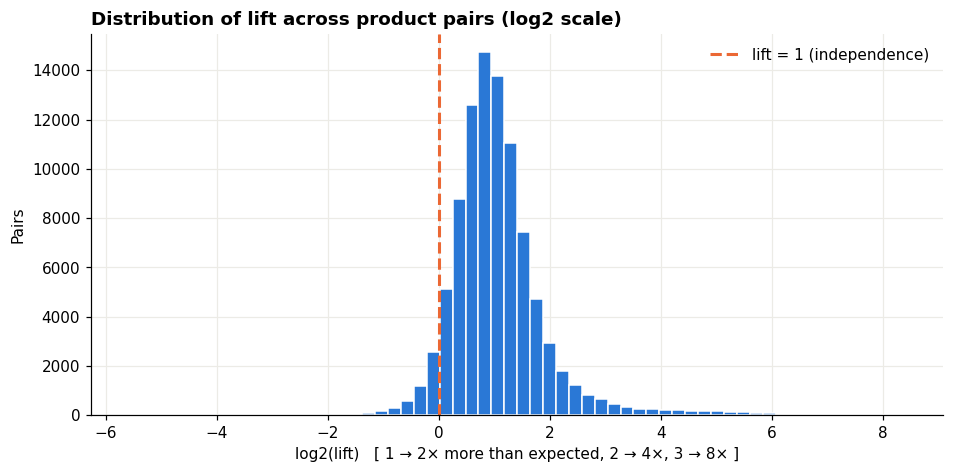


Frequently bought together with 'Organic Hass Avocado' (excluding same aisle):


,with,aisle,n_ab,confidence,lift,same_aisle
385353,"Tortillas, Corn, Organic",tortillas flat bread,"1,523",0.7%,3.76,False
20272,Organic Large Green Asparagus,fresh vegetables,"4,754",2.2%,3.71,False
1578122,Organic Red Cherry Tomato,fresh vegetables,695,0.3%,3.45,False
53444,Organic Original Hommus,fresh dips tapenades,"2,908",1.4%,3.28,False
405832,"Hummus, Hope, Original Recipe",fresh dips tapenades,"1,290",0.6%,3.28,False
222,Organic Cucumber,fresh vegetables,"17,456",8.2%,3.27,False
103242,Organic Orange Bell Pepper,fresh vegetables,"2,275",1.1%,3.26,False
425089,Black Beans No Salt Added,canned meals beans,"1,225",0.6%,3.21,False



Frequently bought together with 'Organic Whole Milk' (excluding same aisle):


,with,aisle,n_ab,confidence,lift,same_aisle
36514,Whole Milk Plain Yogurt,yogurt,"4,083",3.0%,6.23,False
1356065,Apples + Strawberries Organic Nibbly Fingers,baby food formula,680,0.5%,4.81,False
594355,Blueberry Whole Milk Yogurt Pouch,yogurt,"1,002",0.7%,4.74,False
993605,Organic Whole Milk French Vanilla Yogurt,yogurt,760,0.6%,4.55,False
1072608,Organic Stage 4 Green Bean Pear & Pea Baby Food,baby food formula,718,0.5%,4.51,False
246850,Plain Whole Milk Yogurt,yogurt,"1,394",1.0%,4.43,False
157935,YoBaby Peach Pear Yogurt,yogurt,"1,579",1.1%,4.26,False
176254,Yobaby Organic Plain Yogurt,yogurt,"1,474",1.1%,4.12,False



Frequently bought together with 'Limes' (excluding same aisle):


,with,aisle,n_ab,confidence,lift,same_aisle
1585136,Lemon Grass,fresh herbs,957,0.7%,7.23,False
323134,Poblano Pepper,fresh vegetables,"1,799",1.3%,6.31,False
2141,Bunched Cilantro,fresh herbs,"12,491",8.9%,6.27,False
16091,Organic Jalapeno Pepper,fresh vegetables,"5,427",3.9%,6.12,False
2554,Jalapeno Peppers,fresh vegetables,"11,393",8.1%,6.12,False
551,Organic Cilantro,fresh herbs,"17,565",12.5%,5.78,False
964541,Authentic Red Curry Paste,condiments,993,0.7%,5.75,False
833435,Tonic Water,water seltzer sparkling water,"1,015",0.7%,5.48,False


In [24]:
# ==============================
# 5.6.3 Top pairs by support vs. by lift
# ==============================
cols = ["product_a", "product_b", "n_ab", "support", "conf_a_b", "conf_b_a", "lift", "same_aisle"]
fmt = {"n_ab": "{:,}", "support": "{:.2%}", "conf_a_b": "{:.1%}", "conf_b_a": "{:.1%}", "lift": "{:.2f}"}

print("Top 15 pairs by SUPPORT (most frequent together):")
display(rules.nlargest(15, "support")[cols].style.format(fmt))

print("Top 15 pairs by LIFT (strongest association, ≥ MIN_COOC orders):")
display(rules.nlargest(15, "lift")[cols].style.format(fmt))

# ==============================
# 5.6.4 Variants vs. complements: are strong pairs from the same aisle?
# ==============================
summary = pd.DataFrame({
    "same_aisle_share": [
        rules.nlargest(100, "support")["same_aisle"].mean(),
        rules.nlargest(100, "lift")["same_aisle"].mean(),
        rules["same_aisle"].mean(),
    ]}, index=["Top 100 by support", "Top 100 by lift", "All pairs"])
display(summary.style.format("{:.1%}"))

fig, ax = plt.subplots()
ax.hist(np.log2(rules["lift"]), bins=60, color=BLUE, edgecolor="white")
ax.axvline(0, color=ORANGE, ls="--", lw=2, label="lift = 1 (independence)")
ax.set(title="Distribution of lift across product pairs (log2 scale)",
       xlabel="log2(lift)   [ 1 → 2× more than expected, 2 → 4×, 3 → 8× ]", ylabel="Pairs")
ax.legend(frameon=False)
plt.show()

# ==============================
# 5.6.5 "Frequently bought together" for a given product
# ==============================
def bought_together(product_name, n=8, exclude_same_aisle=False):
    """Products most associated with a given product (ranked by lift, min support applied)."""
    pid = products.loc[products["product_name"] == product_name, "product_id"]
    if pid.empty or pid.iloc[0] not in pid_to_col.index:
        return f"'{product_name}' not found among the top {TOP_N_RULES:,} products"
    col = pid_to_col[pid.iloc[0]]
    side_a = rules[rules["a"] == col].rename(columns={"product_b": "with", "conf_a_b": "confidence", "aisle_b": "aisle"})
    side_b = rules[rules["b"] == col].rename(columns={"product_a": "with", "conf_b_a": "confidence", "aisle_a": "aisle"})
    out = pd.concat([side_a, side_b])[["with", "aisle", "n_ab", "confidence", "lift", "same_aisle"]]
    if exclude_same_aisle:
        out = out[~out["same_aisle"]]
    return out.nlargest(n, "lift").style.format({"n_ab": "{:,}", "confidence": "{:.1%}", "lift": "{:.2f}"})

for name in ["Organic Hass Avocado", "Organic Whole Milk", "Limes"]:
    print(f"\nFrequently bought together with '{name}' (excluding same aisle):")
    display(bought_together(name, exclude_same_aisle=True))

### 5.6 Co-purchases — Key Findings

**1. Most product pairs show a positive association**
- The analysis uses the **top 2,000 products**, which cover **66.0% of all purchases** and appear in **3.07M orders** (95.5% of prior orders).
- **93,628 pairs** appear together in at least 200 orders, and **94.9% of them have lift > 1**.
- The lift distribution is centered around **log2(lift) ≈ 1**: most pairs are bought together **~2× more often than expected by chance**, with a long right tail reaching lifts above **300×**.
- Part of this is a selection effect: requiring ≥200 co-occurrences favors pairs that already appear together often.

**2. Frequent pairs are just popular products bought together**
- The **top pairs by support** are all combinations of the most popular produce: bananas, avocados, strawberries, baby spinach, raspberries, lemons.
  - #1: *Bag of Organic Bananas* + *Organic Hass Avocado* → **62,341 orders (1.94%)**, lift 2.47.
  - Even the most frequent pair appears in **less than 2% of orders**.
- Their lift is moderate (**1.4–3.0**): they co-occur mainly because **both products are very popular**, not because of a strong relationship. Only **37%** of the top 100 by support share the same aisle.
- **Customers are consistent in the variants they choose:** *Bag of Organic Bananas* pairs most with *Organic **Hass** Avocado*, while *Banana* pairs most with *Organic Avocado*. Shoppers tend to choose the same "style" of product across categories, which reflects different shopper profiles.

**3. Strongly associated pairs are variants of the same product**
- **99%** of the top 100 pairs by lift belong to the **same aisle** (vs. **9.3%** across all pairs), with lifts between **230× and 335×** and high confidence (**25–57%**):
  - Snack bars of the same brand/line: *Chocolate Sea Salt* + *Coconut Chocolate Bar* (lift **335**), *Coconut Chia Bar* + *Acai Berry Chia Bar* (319).
  - Yogurt flavors: *Almond Milk Blueberry* + *Peach Yogurt* (327), Greek yogurt with fruit on the bottom (279), lemon + key lime (245).
  - Flavored waters: *Unsweetened Watermelon* + *Blackberry Water* (316).
  - Baby food purées of different flavors and stages (247–308) and kids' yogurt pouches (230–236).
- → The strongest associations reflect customers **buying several flavors of the same product line**: when they buy one, there is a 25–57% chance they also buy another flavor.

**4. Excluding the same aisle reveals real complements, often driven by recipes**
| Product | Strongest cross-aisle associations | Context |
|---|---|---|
| **Organic Hass Avocado** | Corn tortillas (3.8), asparagus, cherry tomatoes, hummus, cucumber, bell pepper, black beans (lift 3.2–3.8) | Mexican food, salads, dips |
| **Limes** | Lemongrass (7.2), poblano, cilantro, jalapeño, red curry paste, **tonic water** (5.5) | Mexican and Thai cooking… and gin & tonic |
| **Organic Whole Milk** | Whole milk yogurt (6.2), toddler yogurts, baby food (lift 4.1–4.8) | **Households with young children** |

- Cross-aisle associations are **semantically meaningful** and can be grouped into **meal or recipe contexts**.
- Co-purchases also reveal **customer segments**: whole milk + baby food + toddler yogurts point to families with small children.

**5. Lift and confidence tell different stories**
- **Variant pairs** (same aisle) have both **very high lift and high confidence** (25–57%).
- **Complement pairs** (cross-aisle) have **moderate lift (3–7×) but low confidence**: e.g., *Limes → Lemon Grass* has lift **7.2** but confidence of only **0.7%**, while *Limes → Organic Cilantro* has lift 5.8 and confidence **12.5%**.
- **Lift alone favors niche pairs**, while **confidence/support alone favors popular products**. Ranking must balance both.

**Implications for the recommender:**
- **"Frequently bought together" should separate variants from complements:**
  - **"More flavors you may like"** → same-aisle, high-lift pairs: discovery within a product line the customer already buys.
  - **"Complete your meal"** → cross-aisle complements (avocado → tortillas, limes → cilantro): true cross-selling.
- **Popular pairs (high support) add little value** as recommendations: suggesting strawberries to someone buying bananas is something most customers would do anyway.
- **Basket context matters:** recommendations based on **what is already in the cart** (session-based) can capture recipe intent that the customer's history does not show.
- **Co-purchase signals help with discovery:** they suggest products the customer has never bought but that fit their current basket, which addresses part of the **~40% of new products** found in the reorders analysis.
- **Shopper profiles and household inference:** variant consistency (organic vs. conventional, specific brands) and associations like milk → baby food can be used to infer **customer segments** and personalize beyond individual products.
- **Ranking must balance lift and popularity:** a combined score (e.g., lift × confidence, or lift with a minimum support) avoids recommending either only bananas or only rare niche items.

## 6. EDA Summary and Modeling Decisions

### 6.1 What We Learned

| # | Finding | Evidence | Consequence for the recommender |
|---|---|---|---|
| 1 | **Customers repeat what they buy** | 59.9% of products in the next order were bought before; 18.4% of orders are only reorders | "Buy it again" is the core use case and the strongest signal |
| 2 | **…but history has a ceiling** | ~40% of products in the next order are new to the customer; 6.6% of orders have no reorders | History-only models cannot exceed ~60% recall → **discovery** is needed |
| 3 | **Each customer has a small core of staples** | 60% of customer–product pairs were bought only once | Past products must be **ranked**, not simply listed |
| 4 | **Products have personal purchase cycles** | Purchase probability peaks at due ratio 0.75–1 (28% vs. 17.5% avg) and drops to 4.5% when long overdue | **Timing** (due ratio, recency) is a key feature; long-overdue items can be filtered |
| 5 | **Some products are staples, others are occasional** | Milk and bananas reorder at 83–86%; spices at 3–8%; dairy/produce ~70% vs. personal care/pantry ~35% | Product and department reorder rates are strong priors |
| 6 | **Cart position reveals staples** | Reorder rate falls from ~72% (1st item) to ~47% (30th item) | Average cart position is a useful feature |
| 7 | **Customers differ in routine and history** | Median of 10 orders; reorder rate per customer from 0% to 100% (median 50%); reorder rate grows with tenure | Personalize the **mix** of buy-again vs. discovery; new customers need collective signals |
| 8 | **Context changes the basket** | Top-up orders (0–1 days) are small; weekly orders are larger; reorder rate drops after long gaps | Days since prior order affects **what** and **how many** to recommend |
| 9 | **Basket size varies a lot** | Median 8–9 products, CV 0.44 within customers; Precision@10 ceiling = 73% | A **personalized K** should beat a fixed K |
| 10 | **Sales are extremely concentrated** | Gini = 0.87; 1.6% of products = 50% of purchases; 46% of products have <50 purchases | Watch **popularity bias** and coverage; collaborative models can focus on top products |
| 11 | **Co-purchases are meaningful** | Same-aisle variants (lift 230–335×) and recipe complements (avocado → tortillas, limes → cilantro) | Basket-context recommendations for discovery and cross-selling |
| 12 | **Time-of-day/day-of-week matter less** | Hourly shape is similar across days | Temporal context is a secondary feature; more useful for **when** to communicate |

### 6.2 Modeling Plan

**Problem framing**
For each customer, **rank candidate products** by their probability of being in the next order, and then decide **how many** to recommend.

**Evaluation setup**
- **History:** `prior` orders. **Target:** each customer's `train` order (temporal holdout, no leakage).
- **Sample:** a random subset of 30k train customers for fast iteration (a full-set evaluation was left as a next step).
- **Ranking metrics @K (K = 5, 10, 20):** Precision, Recall, F1, Hit Rate, NDCG, always read **relative to the theoretical ceilings** from section 5.3.
- **Beyond accuracy:** catalog coverage and share of hits that are **new products** for the customer.
- **Variable K:** precision, recall and **F1 per order** (the Kaggle metric).
- **Segments:** results broken down by **history length** (short vs. long) and **customer routine** (low vs. high reorder rate).

**Models, from simple to complex**

| # | Model | Idea | Covers |
|---|---|---|---|
| M0 | **Popularity** | Same top-K products for everyone | Baseline / cold start |
| M1 | **Buy it again — frequency** | Customer's most frequently bought products | Reorders |
| M2 | **Buy it again — frequency + recency + cycle** | Score combining frequency, time-decay and due ratio | Reorders (timing-aware) |
| M3 | **Collaborative filtering** (item-item / matrix factorization) | Products bought by similar customers | Discovery |
| M4 | **Association rules** | Products that complement the customer's usual basket | Discovery / cross-selling |
| M5 | **Hybrid** | Buy-again slots + discovery slots, mix based on the customer's reorder propensity | Both |
| M6 | **Supervised reorder model** (LightGBM) | Binary classifier on customer × product candidates with engineered features | Best ranking of reorders |
| M7 | **Personalized K** | Rule-based K, then probability threshold / F1 optimization on top of M6 | How many to recommend |

**Feature groups for M6 (from the EDA)**
- **Customer–product:** times bought, share of the customer's orders that include it, orders since last purchase, **due ratio**, average cart position.
- **Product:** overall reorder rate, popularity, department/aisle, average purchase cycle across customers.
- **Customer:** number of orders, reorder rate, average basket size, average days between orders, organic share.
- **Order context:** days since prior order, day of week, hour of day.

**Success criteria**
- Each model must beat the previous one on **F1@10 / NDCG@10**, without collapsing **coverage**.
- The final model should show **where** it improves (segments) and **why** (feature importance), so the results can be translated into business recommendations.

### 6.3 Evaluation Strategy: Fixed K vs. Variable K

The evaluation is done in **two stages**, because they answer different questions:

**Stage 1 — Fixed K: which model ranks products best?**
- All models (M0–M6) recommend exactly **K = 5, 10 and 20** products per customer.
- A fixed K isolates **ranking quality**: no model can "win" just by recommending fewer products.
- It also represents a real surface: a **carousel** with a fixed number of slots.
- Metrics: Precision@K, Recall@K, F1@K, Hit Rate@K, NDCG@K, coverage.

**Stage 2 — Variable K: how many products should we recommend?**
Applied on top of the best ranking model(s):

| Method | How K is chosen | Applicable to |
|---|---|---|
| **Customer rule** | Customer's typical number of reorders per order (avg. basket × reorder rate) | Any model (incl. M1, M2) |
| **Probability threshold** | All products with P(purchase) above a tuned threshold | M6 (requires calibrated probabilities) |
| **Expected F1 optimization** | K that maximizes each customer's expected F1 (the `None` option is added in section 9 for the Kaggle metric) | M6 |

- This represents the **pre-filled cart**, where every extra product is friction for the customer.
- Metrics: **precision, recall and F1 per order** (the Kaggle metric).

**Comparison:** both stages are compared using **F1 per order**, so we can separate:
1. The gain from a **better ranking model** (same K, different model).
2. The gain from **personalizing K** (same model, different K strategy).

## 7. Recommender Models

### 7.1 Evaluation Setup

**Data split**
- **History:** `prior` orders → what models can learn from.
- **Target:** each customer's `train` order → what we try to predict.
- **Evaluation sample:** a random subset of train customers for fast iteration (set `EVAL_SAMPLE = None` to use all of them).

**Metrics** (computed per customer and then averaged):
| Metric | Question it answers |
|---|---|
| **Precision@K** | Of the K recommended products, what share was bought? |
| **Recall@K** | Of the products bought, what share did we recommend? |
| **F1@K** | Balance between precision and recall |
| **Hit Rate@K** | Did we get at least one product right? |
| **NDCG@K** | Are the correct products ranked at the top? |
| **Coverage** | What share of the catalog appears in at least one recommendation? |
| **New-hits share** | What share of correct recommendations are products the customer had **never bought**? (discovery) |

**Reference ceilings** (computed on the same sample):
- **Perfect model:** recommends exactly the products in the next order → the maximum achievable given basket sizes.
- **Perfect "Buy it again":** recommends exactly the next-order products **that were already in the customer's history** → the maximum for any model that only recommends past products.

In [25]:
# ==============================
# 7.1.1 Evaluation sample
# ==============================
EVAL_SAMPLE = 30_000       # None → use all train customers
KS = [5, 10, 20]

train_customers = orders.loc[orders["eval_set"] == "train", "user_id"].unique()
if EVAL_SAMPLE:
    eval_users = np.sort(rng.choice(train_customers, size=min(EVAL_SAMPLE, len(train_customers)), replace=False))
else:
    eval_users = np.sort(train_customers)

# Ground truth: products in each customer's next (train) order
truth = (train_u[train_u["user_id"].isin(eval_users)]
         .groupby("user_id")["product_id"].apply(set).to_dict())

# History: products each customer bought in prior orders
history = (user_product[user_product["user_id"].isin(eval_users)]
           .groupby("user_id")["product_id"].apply(set).to_dict())

print(f"Evaluation customers: {len(truth):,}")
print(f"Avg. products in the next order: {np.mean([len(t) for t in truth.values()]):.1f}")
print(f"Avg. distinct products in history: {np.mean([len(h) for h in history.values()]):.1f}")

Evaluation customers: 30,000
Avg. products in the next order: 10.6
Avg. distinct products in history: 65.1


In [26]:
# ==============================
# 7.1.2 Evaluation functions
# ==============================
def evaluate(recs, k=10, name="model"):
    """
    recs: dict {user_id: ranked list of product_ids}
    k:    int → fixed K (lists are truncated to k; precision uses k as denominator)
          None → variable K (each list is used as-is; precision uses its own length)
    Returns (summary Series, per-user DataFrame).
    """
    rows = []
    for u, t in truth.items():
        r = list(recs.get(u, []))
        r = r[:k] if k is not None else r
        kk = k if k is not None else len(r)

        hits = np.array([p in t for p in r], dtype=bool)
        n_hits = int(hits.sum())

        precision = n_hits / kk if kk > 0 else (1.0 if len(t) == 0 else 0.0)
        recall = n_hits / len(t) if len(t) > 0 else (1.0 if len(r) == 0 else 0.0)
        f1 = 0.0 if precision + recall == 0 else 2 * precision * recall / (precision + recall)

        if len(r) > 0:
            dcg = (hits / np.log2(np.arange(2, len(r) + 2))).sum()
            idcg = (1 / np.log2(np.arange(2, min(len(t), kk) + 2))).sum()
            ndcg = dcg / idcg if idcg > 0 else 0.0
        else:
            ndcg = 0.0

        h = history.get(u, set())
        new_hits = sum(1 for p, m in zip(r, hits) if m and p not in h)
        rows.append((u, precision, recall, f1, n_hits > 0, ndcg, n_hits, new_hits, len(r)))

    per_user = pd.DataFrame(rows, columns=["user_id", "precision", "recall", "f1", "hit",
                                           "ndcg", "n_hits", "new_hits", "list_len"]).set_index("user_id")

    rec_items = {p for u in truth for p in (list(recs.get(u, []))[:k] if k is not None else recs.get(u, []))}
    summary = pd.Series({
        "model": name,
        "K": k if k is not None else "variable",
        "precision": per_user["precision"].mean(),
        "recall": per_user["recall"].mean(),
        "f1": per_user["f1"].mean(),
        "hit_rate": per_user["hit"].mean(),
        "ndcg": per_user["ndcg"].mean(),
        "avg_list_len": per_user["list_len"].mean(),
        "coverage": len(rec_items) / len(products),
        "new_hits_share": per_user["new_hits"].sum() / max(per_user["n_hits"].sum(), 1),
    })
    return summary, per_user


# Registry of results (summary) and per-user results (for segment analysis later)
results, per_user_results = [], {}

def run_eval(recs, name, ks=KS):
    """Evaluate a model for several K values and store the results."""
    out = []
    for k in ks:
        s, pu = evaluate(recs, k=k, name=name)
        results.append(s)
        per_user_results[(name, s["K"])] = pu
        out.append(s)
    return pd.DataFrame(out)

FMT = {"precision": "{:.3f}", "recall": "{:.3f}", "f1": "{:.3f}", "hit_rate": "{:.1%}",
       "ndcg": "{:.3f}", "avg_list_len": "{:.1f}", "coverage": "{:.2%}", "new_hits_share": "{:.1%}"}

def show_results(k=None):
    """Show all stored results (optionally filtered by K)."""
    df = pd.DataFrame(results)
    if k is not None:
        df = df[df["K"] == k]
    display(df.reset_index(drop=True).style.format(FMT))

In [27]:
# ==============================
# 7.1.3 Reference ceilings
# ==============================
# Perfect model: recommends exactly the products of the next order
recs_perfect = {u: list(t) for u, t in truth.items()}

# Perfect "Buy it again": only the next-order products that were already in history
recs_perfect_bia = {u: list(t & history.get(u, set())) for u, t in truth.items()}

run_eval(recs_perfect, "Ceiling: perfect model")
run_eval(recs_perfect_bia, "Ceiling: perfect buy-it-again")
show_results()

,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,Ceiling: perfect model,5,0.889,0.621,0.641,100.0%,1.000,4.4,36.10%,40.3%
1,Ceiling: perfect model,10,0.730,0.847,0.699,100.0%,1.000,7.3,45.91%,40.3%
2,Ceiling: perfect model,20,0.487,0.974,0.585,100.0%,1.000,9.7,51.48%,40.1%
3,Ceiling: perfect buy-it-again,5,0.714,0.449,0.483,93.4%,0.825,3.6,29.26%,0.0%
4,Ceiling: perfect buy-it-again,10,0.515,0.554,0.470,93.4%,0.749,5.2,34.70%,0.0%
5,Ceiling: perfect buy-it-again,20,0.306,0.597,0.361,93.4%,0.700,6.1,37.35%,0.0%


### 7.2 M0 — Popularity Baseline

**Idea:** recommend the **same top-K best-selling products to every customer**.

- Uses **no customer information** → no personalization.
- Sets the **minimum bar**: any personalized model must beat it.
- Useful for **cold start** (customers without history).
- Expected weakness: near-zero **catalog coverage** (everyone gets bananas, strawberries and spinach).

In [28]:
# ==============================
# 7.2.1 M0 — Popularity
# ==============================
popular_products = product_stats.index[:max(KS)].tolist()      # already sorted by purchases
recs_m0 = {u: popular_products for u in truth}

print("Recommended to everyone:")
print(products.set_index("product_id").loc[popular_products[:10], "product_name"].tolist())

run_eval(recs_m0, "M0 Popularity")
show_results()

Recommended to everyone:
['Banana', 'Bag of Organic Bananas', 'Organic Strawberries', 'Organic Baby Spinach', 'Organic Hass Avocado', 'Organic Avocado', 'Large Lemon', 'Strawberries', 'Limes', 'Organic Whole Milk']


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,Ceiling: perfect model,5,0.889,0.621,0.641,100.0%,1.000,4.4,36.10%,40.3%
1,Ceiling: perfect model,10,0.730,0.847,0.699,100.0%,1.000,7.3,45.91%,40.3%
2,Ceiling: perfect model,20,0.487,0.974,0.585,100.0%,1.000,9.7,51.48%,40.1%
3,Ceiling: perfect buy-it-again,5,0.714,0.449,0.483,93.4%,0.825,3.6,29.26%,0.0%
4,Ceiling: perfect buy-it-again,10,0.515,0.554,0.470,93.4%,0.749,5.2,34.70%,0.0%
5,Ceiling: perfect buy-it-again,20,0.306,0.597,0.361,93.4%,0.700,6.1,37.35%,0.0%
6,M0 Popularity,5,0.094,0.046,0.055,36.1%,0.108,5.0,0.01%,15.4%
7,M0 Popularity,10,0.073,0.069,0.063,45.5%,0.097,10.0,0.02%,17.8%
8,M0 Popularity,20,0.051,0.094,0.060,51.9%,0.097,20.0,0.04%,20.5%


### 7.2 M0 — Results

**Reference ceilings (30k customers sample)**
| | K | Precision | Recall | F1 | Hit Rate | NDCG |
|---|---|---|---|---|---|---|
| Perfect model | 10 | 0.730 | 0.847 | **0.699** | 100% | 1.000 |
| Perfect buy-it-again | 10 | 0.515 | 0.554 | **0.470** | 93.4% | 0.749 |

- The perfect model reproduces the ceilings from section 5.3 (Precision@10 = 0.730), confirming that the **sample is representative**.
- Even a perfect model does not reach F1 = 1 with a fixed K, because basket sizes differ from K.
- **40.3%** of the perfect model's hits are products new to the customer, consistent with the reorders analysis.
- A perfect **buy-it-again** model is capped at **F1@10 = 0.470** and fails completely for **6.6%** of customers (hit rate 93.4%). The gap between 0.470 and 0.699 can only be closed with **discovery**.

**M0 — Popularity**
| K | Precision | Recall | F1 | Hit Rate | NDCG | Coverage | New-hits share |
|---|---|---|---|---|---|---|---|
| 5 | 0.094 | 0.046 | 0.055 | 36.1% | 0.108 | 0.01% | 15.4% |
| **10** | **0.073** | **0.069** | **0.063** | **45.5%** | **0.097** | **0.02%** | **17.8%** |
| 20 | 0.051 | 0.094 | 0.060 | 51.9% | 0.097 | 0.04% | 20.5% |

**Interpretation**
- **Low accuracy:** F1@10 = 0.063, only **~9% of the perfect model's F1** and ~13% of the buy-it-again ceiling. Fewer than 1 in 10 recommended products is bought.
- **Misleadingly high hit rate:** recommending the same 10 products to everyone gets at least one right for **45.5%** of customers, thanks to universal staples like bananas. **Hit rate is easy to inflate with popular products**, so F1 and NDCG will be our main metrics.
- **No personalization, no diversity:** only 10–20 products out of ~49.7k are ever recommended (coverage ≈ **0.02%**). This is the extreme case of **popularity bias**.
- **Some discovery, by chance:** ~18% of its hits are products the customer had never bought (popular items they simply hadn't tried yet).
- **Increasing K** raises recall and hit rate but lowers precision; F1 peaks around K = 10.

**Conclusion:** popularity is a useful **floor** and a fallback for **cold-start** customers, but it ignores the strongest signal found in the EDA: **each customer's own history**. That is what M1 and M2 will use.

### 7.3 M1 & M2 — "Buy It Again" Models

These models only recommend products **from the customer's own history**, ranked by a score. Their ceiling is the *perfect buy-it-again* (F1@10 = 0.470).

| Model | Score | EDA finding behind it |
|---|---|---|
| **M1 — Frequency** | Number of times the customer bought the product | 60% of past products are one-offs → rank, don't list |
| **M2a — Frequency + recency** | Time-decayed frequency: each past purchase weighs $0.9^{\text{orders ago}}$ | Recent behavior is more predictive; reorder rate drops after long gaps |
| **M2b — + Purchase cycle** | M2a score × **due-ratio multiplier** | Purchase probability peaks when a product is "due" and drops when long overdue |

**Due-ratio multiplier:** for each due-ratio bucket, how much more (or less) likely a product is to be bought than average:

$$\text{multiplier}(\text{bucket}) = \frac{P(\text{bought} \mid \text{bucket})}{P(\text{bought})}$$

To avoid **data leakage**, these multipliers are estimated on **train customers that are NOT in the evaluation sample**, and then applied to the evaluation customers. Products bought only once (no personal cycle) get their own "no cycle" bucket.

**Note on timing:** the due ratio uses the days elapsed until the target order (`days_since_prior_order` of the `train` order). This is known at prediction time: in production it corresponds to the moment the customer opens the app.

In [29]:
# ==============================
# 7.3.1 Candidate features for evaluation customers
# ==============================
DECAY = 0.9

n_prior_orders = orders[orders["eval_set"] == "prior"].groupby("user_id")["order_number"].max()

p_eval = prior.loc[prior["user_id"].isin(eval_users), ["user_id", "product_id", "order_number"]].copy()
p_eval["orders_ago"] = p_eval["user_id"].map(n_prior_orders) - p_eval["order_number"]
p_eval["decay_w"] = DECAY ** p_eval["orders_ago"]

cand_eval = (p_eval.groupby(["user_id", "product_id"])
             .agg(times_bought=("order_number", "size"),
                  last_order=("order_number", "max"),
                  decay_score=("decay_w", "sum"))
             .reset_index())

# Due ratio at the moment of the target order (from section 5.5b)
cand_eval = cand_eval.merge(cand[["user_id", "product_id", "due_ratio"]],
                            on=["user_id", "product_id"], how="left")

def to_due_bucket(due_ratio):
    b = pd.cut(due_ratio, bins=bins, labels=labels, include_lowest=True)
    return b.cat.add_categories("no cycle").fillna("no cycle")

cand_eval["due_bucket"] = to_due_bucket(cand_eval["due_ratio"])

print(f"Candidates (customer × past product): {len(cand_eval):,}")
print(f"Avg. candidates per customer: {cand_eval.groupby('user_id').size().mean():.1f}")
print(f"Candidates with a personal cycle: {cand_eval['due_ratio'].notna().mean():.1%}")

Candidates (customer × past product): 1,951,532
Avg. candidates per customer: 65.1
Candidates with a personal cycle: 39.7%


In [30]:
# ==============================
# 7.3.2 Due-ratio multipliers estimated on NON-evaluation customers
# ==============================
ref_users = np.setdiff1d(train_customers, eval_users)

ref = user_product.loc[user_product["user_id"].isin(ref_users), ["user_id", "product_id"]]
ref = ref.merge(cand[["user_id", "product_id", "due_ratio"]], on=["user_id", "product_id"], how="left")
ref = ref.merge(train_u[["user_id", "product_id"]].assign(bought=1), on=["user_id", "product_id"], how="left")
ref["bought"] = ref["bought"].fillna(0).astype("int8")
ref["due_bucket"] = to_due_bucket(ref["due_ratio"])

due_mult_table = ref.groupby("due_bucket", observed=True)["bought"].agg(["size", "mean"])
due_mult_table["multiplier"] = due_mult_table["mean"] / ref["bought"].mean()
due_mult_table.columns = ["candidates", "purchase_rate", "multiplier"]

print(f"Reference customers (not in evaluation): {len(ref_users):,}")
display(due_mult_table.style.format({"candidates": "{:,}", "purchase_rate": "{:.1%}", "multiplier": "{:.2f}"}))

cand_eval["due_mult"] = cand_eval["due_bucket"].map(due_mult_table["multiplier"]).astype(float)

Reference customers (not in evaluation): 101,209


,candidates,purchase_rate,multiplier
due_bucket,,,
0–0.25,"258,760",17.4%,1.78
0.25–0.5,"303,029",23.8%,2.43
0.5–0.75,"253,265",26.8%,2.74
0.75–1,"225,446",28.0%,2.86
1–1.25,"163,215",25.6%,2.62
1.25–1.5,"138,718",23.3%,2.38
1.5–2,"209,783",19.7%,2.01
2–3,"261,631",15.0%,1.53
3–5,"272,515",9.9%,1.01


In [31]:
# ==============================
# 7.3.3 Scores and recommendations
# ==============================
def top_k_recs(df, score_cols, k=max(KS)):
    """Rank candidates per customer by score (desc) and keep the top k as a list."""
    top = (df.sort_values(["user_id"] + score_cols, ascending=[True] + [False] * len(score_cols))
             .groupby("user_id").head(k))
    return top.groupby("user_id")["product_id"].apply(list).to_dict()

cand_eval["score_m2b"] = cand_eval["decay_score"] * cand_eval["due_mult"]

recs_m1  = top_k_recs(cand_eval, ["times_bought", "last_order"])   # tie-break: most recent
recs_m2a = top_k_recs(cand_eval, ["decay_score"])
recs_m2b = top_k_recs(cand_eval, ["score_m2b"])

run_eval(recs_m1,  "M1 Buy-again: frequency")
run_eval(recs_m2a, "M2a Buy-again: frequency + recency")
run_eval(recs_m2b, "M2b Buy-again: + purchase cycle")

print("All results:")
show_results()
print("\nComparison at K = 10:")
show_results(k=10)

All results:


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,Ceiling: perfect model,5,0.889,0.621,0.641,100.0%,1.000,4.4,36.10%,40.3%
1,Ceiling: perfect model,10,0.730,0.847,0.699,100.0%,1.000,7.3,45.91%,40.3%
2,Ceiling: perfect model,20,0.487,0.974,0.585,100.0%,1.000,9.7,51.48%,40.1%
3,Ceiling: perfect buy-it-again,5,0.714,0.449,0.483,93.4%,0.825,3.6,29.26%,0.0%
4,Ceiling: perfect buy-it-again,10,0.515,0.554,0.470,93.4%,0.749,5.2,34.70%,0.0%
5,Ceiling: perfect buy-it-again,20,0.306,0.597,0.361,93.4%,0.700,6.1,37.35%,0.0%
6,M0 Popularity,5,0.094,0.046,0.055,36.1%,0.108,5.0,0.01%,15.4%
7,M0 Popularity,10,0.073,0.069,0.063,45.5%,0.097,10.0,0.02%,17.8%
8,M0 Popularity,20,0.051,0.094,0.060,51.9%,0.097,20.0,0.04%,20.5%
9,M1 Buy-again: frequency,5,0.354,0.232,0.238,78.3%,0.416,5.0,33.61%,0.0%



Comparison at K = 10:


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,Ceiling: perfect model,10,0.730,0.847,0.699,100.0%,1.000,7.3,45.91%,40.3%
1,Ceiling: perfect buy-it-again,10,0.515,0.554,0.470,93.4%,0.749,5.2,34.70%,0.0%
2,M0 Popularity,10,0.073,0.069,0.063,45.5%,0.097,10.0,0.02%,17.8%
3,M1 Buy-again: frequency,10,0.276,0.330,0.259,85.5%,0.398,9.8,46.91%,0.0%
4,M2a Buy-again: frequency + recency,10,0.289,0.342,0.270,86.0%,0.415,9.8,47.48%,0.0%
5,M2b Buy-again: + purchase cycle,10,0.288,0.341,0.270,85.9%,0.414,9.8,47.54%,0.0%


### 7.3 M1 & M2 — Results

**Candidates:** each evaluation customer has on average **65 past products** to rank; only **39.7%** of them have a personal purchase cycle (bought 2+ times with a measurable interval).

**Due-ratio multipliers** (estimated on 101k customers outside the evaluation sample) reproduce the EDA pattern: from **×2.86** when the product is due (0.75–1) down to **×0.46** when long overdue (5+), and **×0.48** for products without a personal cycle.

**Comparison at K = 10**
| Model | Precision | Recall | F1 | Hit Rate | NDCG | Coverage | % of buy-again ceiling (F1) |
|---|---|---|---|---|---|---|---|
| Ceiling: perfect model | 0.730 | 0.847 | 0.699 | 100.0% | 1.000 | 45.9% | — |
| Ceiling: perfect buy-it-again | 0.515 | 0.554 | 0.470 | 93.4% | 0.749 | 34.7% | 100% |
| M0 Popularity | 0.073 | 0.069 | 0.063 | 45.5% | 0.097 | 0.02% | 13% |
| M1 Frequency | 0.276 | 0.330 | 0.259 | 85.5% | 0.398 | 46.9% | 55% |
| **M2a Frequency + recency** | **0.289** | **0.342** | **0.270** | **86.0%** | **0.415** | 47.5% | **57%** |
| M2b + purchase cycle | 0.288 | 0.341 | 0.270 | 85.9% | 0.414 | 47.5% | 57% |

**1. Personal history is by far the strongest signal**
- Using only the customer's purchase frequency (M1) multiplies F1@10 by **4×** vs. popularity (0.063 → 0.259) and NDCG by **4×** (0.097 → 0.398).
- **86%** of customers get at least one correct recommendation, and almost **3 out of 10** recommended products are bought.
- Coverage jumps from 0.02% to **~47%** of the catalog, since each customer gets their own products.

**2. Recency adds a consistent improvement**
- Weighting recent purchases more (M2a) improves every metric at every K: F1@10 **+4%** (0.259 → 0.270), NDCG@10 **+4%** (0.398 → 0.415).
- M2a reaches **~57% of the buy-it-again ceiling** in F1 and **~56%** in precision.

**3. The purchase cycle does not add value on top of frequency and recency (in this form)**
- M2b is practically identical to M2a (F1@10 0.270 vs. 0.270, NDCG 0.414 vs. 0.415).
- Why the strong EDA signal does not translate into a gain:
  - **Redundancy:** the multiplier mainly penalizes one-off products and long-overdue products, which are **already ranked low** by frequency and time-decay.
  - **The top of the ranking barely changes:** the products that reach the top 10 are the customer's staples (high frequency, short cycles), and a multiplier between ~1.8 and ~2.9 rarely changes their order.
  - **Univariate effect ≠ incremental effect:** the EDA showed the due ratio's effect *in isolation*; what matters for ranking is what it adds *on top of* other signals.
- A hand-crafted multiplicative rule may be too crude. The **supervised model (M6)** will learn how to combine the due ratio with other features and will tell us, through feature importance and an **ablation study (section 7.9)**, whether it carries **incremental information**.

**4. K = 10 is the best trade-off for these models**
- F1 peaks at **K = 10** (M2a: 0.249 @5, **0.270 @10**, 0.251 @20).
- At K = 20 the average list length is only **18.5**: many customers have fewer than 20 past products, which caps precision for history-only models.

**5. Remaining gap and limitations**
- M2a still leaves **43% of the buy-it-again potential** unrealized → better ranking (M6) can still help.
- By design, these models **never recommend new products** (new-hits share = 0%), so they cannot reach the gap between the buy-it-again ceiling (0.470) and the perfect model (0.699) → this requires **discovery models** (M3, M4) and the **hybrid** (M5).

**Best model so far: M2a (frequency + recency)**, F1@10 = 0.270, NDCG@10 = 0.415.

### 7.4 M3 — Collaborative Filtering (Discovery)

**Goal:** recommend products the customer has **never bought**, based on what **similar customers** buy. This targets the ~40% of next-order products that history-based models (M1, M2) cannot reach.

| Model | Idea |
|---|---|
| **M3a — Item-item CF** | Two products are similar if they are bought by the same customers (cosine similarity). A customer's score for a product = sum of its similarity to the products in their history. |
| **M3b — Matrix factorization (SVD)** | Compresses the customer × product matrix into a few **latent factors** (e.g., "organic", "family with babies", "Mexican cooking") and scores products by how well they match the customer's factors. |

**Setup**
- **Universe:** the top 5,000 products (~80% of purchases), to keep the similarity matrix manageable.
- **Customer × product matrix:** built from the full `prior` history of all customers, with values = log(1 + times bought).

**Two evaluations**
1. **Full next order:** directly comparable with M0–M2.
2. **Discovery only:** history products are excluded from the recommendations, and the ground truth is restricted to products **new to the customer**. Customers whose next order has no new products (18.4%) are excluded from this evaluation. Baselines: a **perfect discovery** ceiling and **popularity among products the customer hasn't bought**.

In [32]:
# ==============================
# 7.4.0 Free memory from large objects no longer needed
# ==============================
import gc
for obj in ["O", "C", "p_eval", "ref", "pr"]:
    if obj in globals():
        del globals()[obj]
gc.collect()

# ==============================
# 7.4.1 Discovery evaluation: only products NEW to the customer
# ==============================
truth_full = truth                                   # keep the original ground truth
truth_new = {u: t - history.get(u, set()) for u, t in truth_full.items()}
truth_new = {u: t for u, t in truth_new.items() if len(t) > 0}

print(f"Customers with at least one new product in the next order: {len(truth_new):,} "
      f"({len(truth_new) / len(truth_full):.1%})")
print(f"Avg. new products per order (among them): {np.mean([len(t) for t in truth_new.values()]):.1f}")

def run_eval_new(recs, name, ks=KS):
    """Evaluate against NEW products only (temporarily swaps the global ground truth)."""
    global truth
    truth = truth_new
    try:
        return run_eval(recs, f"{name} [new only]", ks)
    finally:
        truth = truth_full

# Discovery baselines
recs_perfect_new = {u: list(t) for u, t in truth_new.items()}
popular_all = product_stats.index[:2_000].tolist()
recs_m0_new = {u: [p for p in popular_all if p not in history.get(u, set())][:max(KS)] for u in truth_new}

run_eval_new(recs_perfect_new, "Ceiling: perfect discovery")
run_eval_new(recs_m0_new, "M0 Popularity (excl. history)")

Customers with at least one new product in the next order: 24,483 (81.6%)
Avg. new products per order (among them): 5.2


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,M0 Popularity (excl. history) [new only],5,0.024,0.025,0.021,0.111,0.030,5.000,0.001,1.000
1,M0 Popularity (excl. history) [new only],10,0.020,0.039,0.023,0.168,0.034,10.000,0.001,1.000
2,M0 Popularity (excl. history) [new only],20,0.016,0.061,0.022,0.235,0.041,20.000,0.001,1.000


In [33]:
# ==============================
# 7.4.2 Customer × product matrix (top products)
# ==============================
from scipy import sparse

N_CF = 5_000
cf_items = product_stats.index[:N_CF].to_numpy()
item_idx = pd.Series(np.arange(N_CF), index=cf_items)

users_all = np.sort(user_product["user_id"].unique())
user_idx = pd.Series(np.arange(len(users_all)), index=users_all)

up = user_product[user_product["product_id"].isin(item_idx.index)]
X = sparse.csr_matrix(
    (np.log1p(up["times_bought"].values).astype(np.float32),
     (user_idx[up["user_id"]].values, item_idx[up["product_id"]].values)),
    shape=(len(users_all), N_CF))

print(f"Top {N_CF:,} products cover {product_stats['share_purchases'].iloc[:N_CF].sum():.1%} of purchases")
print(f"Customer × product matrix: {X.shape[0]:,} × {X.shape[1]:,} | non-zeros: {X.nnz:,} "
      f"| density: {X.nnz / (X.shape[0] * X.shape[1]):.3%}")

# ==============================
# Helper: score customers in batches and keep the top-k products
# ==============================
def score_topk(score_fn, users, k=max(KS), exclude_history=False, batch=2_000):
    """score_fn(rows) must return a dense (n_rows × N_CF) score matrix."""
    recs = {}
    rows_all = user_idx.loc[users].values
    for s in range(0, len(users), batch):
        rows = rows_all[s:s + batch]
        scores = np.asarray(score_fn(rows), dtype=np.float32)
        if exclude_history:
            r, c = X[rows].nonzero()
            scores[r, c] = -np.inf
        top = np.argpartition(-scores, k, axis=1)[:, :k]
        order = np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1)
        top = np.take_along_axis(top, order, axis=1)
        for u, row in zip(users[s:s + batch], top):
            recs[u] = cf_items[row].tolist()
    return recs

Top 5,000 products cover 81.5% of purchases
Customer × product matrix: 206,209 × 5,000 | non-zeros: 10,052,377 | density: 0.975%


In [34]:
# ==============================
# 7.4.3 M3a — Item-item collaborative filtering (cosine similarity)
# ==============================
Xb = X.copy()
Xb.data[:] = 1                                        # binary: bought / not bought
co = (Xb.T @ Xb).toarray().astype(np.float32)         # co-purchase counts between products (by customers)
norms = np.sqrt(np.diag(co))
S = co / np.outer(norms, norms)                        # cosine similarity
np.fill_diagonal(S, 0)
del co, Xb; gc.collect()

# Sanity check: most similar products to a few known items
names = products.set_index("product_id")["product_name"]
for pname in ["Organic Hass Avocado", "Organic Whole Milk"]:
    pid = products.loc[products["product_name"] == pname, "product_id"].iloc[0]
    nn = cf_items[np.argsort(-S[item_idx[pid]])[:6]]
    print(f"Most similar to '{pname}': {names.loc[nn].tolist()}")

eval_list = np.array(sorted(truth_full))
item_scores = lambda rows: X[rows] @ S

recs_m3a     = score_topk(item_scores, eval_list)
recs_m3a_new = score_topk(item_scores, eval_list, exclude_history=True)

run_eval(recs_m3a, "M3a Item-item CF")
run_eval_new(recs_m3a_new, "M3a Item-item CF")

Most similar to 'Organic Hass Avocado': ['Organic Strawberries', 'Bag of Organic Bananas', 'Organic Baby Spinach', 'Organic Yellow Onion', 'Organic Garlic', 'Organic Lemon']
Most similar to 'Organic Whole Milk': ['Organic Strawberries', 'Organic Baby Spinach', 'Organic Garlic', 'Bag of Organic Bananas', 'Organic Hass Avocado', 'Organic Yellow Onion']


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,M3a Item-item CF [new only],5,0.031,0.032,0.027,0.138,0.040,5.000,0.015,1.000
1,M3a Item-item CF [new only],10,0.025,0.051,0.030,0.203,0.045,10.000,0.020,1.000
2,M3a Item-item CF [new only],20,0.020,0.083,0.029,0.290,0.055,20.000,0.027,1.000


In [35]:
# ==============================
# 7.4.4 M3b — Matrix factorization (truncated SVD)
# ==============================
from sklearn.decomposition import TruncatedSVD

N_FACTORS = 64
svd = TruncatedSVD(n_components=N_FACTORS, random_state=SEED)
U = svd.fit_transform(X).astype(np.float32)          # customers × factors
V = svd.components_.astype(np.float32)               # factors × products
print(f"Explained variance with {N_FACTORS} factors: {svd.explained_variance_ratio_.sum():.1%}")

svd_scores = lambda rows: U[rows] @ V

recs_m3b     = score_topk(svd_scores, eval_list)
recs_m3b_new = score_topk(svd_scores, eval_list, exclude_history=True)

run_eval(recs_m3b, "M3b SVD")
run_eval_new(recs_m3b_new, "M3b SVD")

Explained variance with 64 factors: 25.3%


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,M3b SVD [new only],5,0.018,0.020,0.016,0.082,0.023,5.000,0.007,1.000
1,M3b SVD [new only],10,0.015,0.034,0.018,0.135,0.027,10.000,0.009,1.000
2,M3b SVD [new only],20,0.013,0.057,0.019,0.214,0.035,20.000,0.012,1.000


In [36]:
# ==============================
# 7.4.5 Comparison at K = 10
# ==============================
df = pd.DataFrame(results)
k10 = df[df["K"] == 10]

print("Full next order (K = 10):")
display(k10[~k10["model"].str.contains("new only")].reset_index(drop=True).style.format(FMT))

print("\nDiscovery — new products only (K = 10):")
display(k10[k10["model"].str.contains("new only")].reset_index(drop=True).style.format(FMT))

# ==============================
# 7.4.6 Example: one customer
# ==============================
u = eval_list[0]
print(f"\nCustomer {u}")
print("Top past products (M2a):        ", names.loc[recs_m2a[u][:6]].tolist())
print("New products suggested (M3a):   ", names.loc[recs_m3a_new[u][:6]].tolist())
print("New products suggested (M3b):   ", names.loc[recs_m3b_new[u][:6]].tolist())
print("Actually bought (new for them): ", names.loc[list(truth_new.get(u, []))[:6]].tolist())

Full next order (K = 10):


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,Ceiling: perfect model,10,0.730,0.847,0.699,100.0%,1.000,7.3,45.91%,40.3%
1,Ceiling: perfect buy-it-again,10,0.515,0.554,0.470,93.4%,0.749,5.2,34.70%,0.0%
2,M0 Popularity,10,0.073,0.069,0.063,45.5%,0.097,10.0,0.02%,17.8%
3,M1 Buy-again: frequency,10,0.276,0.330,0.259,85.5%,0.398,9.8,46.91%,0.0%
4,M2a Buy-again: frequency + recency,10,0.289,0.342,0.270,86.0%,0.415,9.8,47.48%,0.0%
5,M2b Buy-again: + purchase cycle,10,0.288,0.341,0.270,85.9%,0.414,9.8,47.54%,0.0%
6,M3a Item-item CF,10,0.068,0.062,0.058,41.8%,0.080,10.0,2.48%,24.7%
7,M3b SVD,10,0.146,0.150,0.129,63.8%,0.214,10.0,0.68%,2.9%



Discovery — new products only (K = 10):


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,Ceiling: perfect discovery [new only],10,0.463,0.969,0.555,100.0%,1.000,4.6,40.34%,100.0%
1,M0 Popularity (excl. history) [new only],10,0.020,0.039,0.023,16.8%,0.034,10.0,0.10%,100.0%
2,M3a Item-item CF [new only],10,0.025,0.051,0.030,20.3%,0.045,10.0,2.03%,100.0%
3,M3b SVD [new only],10,0.015,0.034,0.018,13.5%,0.027,10.0,0.88%,100.0%



Customer 1
Top past products (M2a):         ['Soda', 'Original Beef Jerky', 'Pistachios', 'Organic String Cheese', 'Zero Calorie Cola', 'Cinnamon Toast Crunch']
New products suggested (M3a):    ['Trail Mix', 'Clementines', "Crunchy Oats 'n Honey Granola Bars", 'Apples', 'Organic Simply Naked Pita Chips', 'Extra Fancy Unsalted Mixed Nuts']
New products suggested (M3b):    ['Clementines', 'Trail Mix', 'Apples', "Crunchy Oats 'n Honey Granola Bars", 'Extra Fancy Unsalted Mixed Nuts', 'Reduced Fat 2% Milk']
Actually bought (new for them):  ['Organic Whole Milk']


### 7.4 M3 — Results

**Setup:** top **5,000 products** (81.5% of purchases); customer × product matrix of 206k × 5k with **0.975% density**. In the evaluation sample, **81.6%** of customers buy at least one new product in their next order (**5.2 new products** on average among them).

**Discovery — new products only (K = 10)**
| Model | Precision | Recall | F1 | Hit Rate | NDCG | Coverage |
|---|---|---|---|---|---|---|
| Ceiling: perfect discovery | 0.463 | 0.969 | 0.555 | 100% | 1.000 | 40.3% |
| M0 Popularity (excl. history) | 0.020 | 0.039 | 0.023 | 16.8% | 0.034 | 0.10% |
| **M3a Item-item CF** | **0.025** | **0.051** | **0.030** | **20.3%** | **0.045** | **2.04%** |
| M3b SVD | 0.015 | 0.033 | 0.018 | 13.4% | 0.026 | 0.90% |

**Full next order (K = 10)**, for reference against the buy-again models:
| Model | Precision | Recall | F1 | NDCG | New-hits share |
|---|---|---|---|---|---|
| M2a Buy-again (best so far) | 0.289 | 0.342 | **0.270** | **0.415** | 0% |
| M3a Item-item CF | 0.068 | 0.062 | 0.058 | 0.080 | 24.7% |
| M3b SVD | 0.146 | 0.150 | 0.129 | 0.214 | 2.9% |

**1. Discovery is an order of magnitude harder than predicting reorders**
- The best discovery model gets only **~2.5%** of its new-product suggestions right (1 in 40), vs. **~29%** for buy-again recommendations.
- New purchases are inherently hard to anticipate: they depend on recipes, promotions, trends and household needs that are not visible in past behavior.

**2. Item-item CF is the best discovery model, but only modestly better than popularity**
- vs. popularity excluding history: **+30% F1** (0.030 vs. 0.023), **+32% NDCG**, **+21% hit rate** (20.3% vs. 16.8%).
- It recommends a much wider part of the catalog: **2.04%** vs. 0.10% coverage (**~20× more products**).
- One in five customers gets at least one correct new product among 10 suggestions.

**3. SVD mostly reconstructs the customer's history**
- On the full order it performs reasonably (F1 0.129), but only **2.9%** of its hits are new products: the low-rank model mainly reproduces products the customer already buys.
- For discovery it is **worse than popularity** (F1 0.018). With 64 factors it explains only **25.3%** of the variance, which suggests the customer × product matrix is too sparse and noisy for a plain SVD.

**4. Popularity bias in item similarity**
- The most "similar" products to *Organic Hass Avocado* and *Organic Whole Milk* are *Organic Strawberries*, *Bags of Organic Bananas* and *Organic Baby Spinach*: products that co-occur with everything because **everyone buys them**, the same pattern seen with *support* in the co-purchases analysis.
- Cosine similarity on binary purchases does not fully correct for popularity.

**5. Recommendations are coherent even when they miss**
- Example (customer 1): a snack-oriented shopper (soda, beef jerky, pistachios, string cheese) receives coherent suggestions (trail mix, clementines, granola bars, apples), but the new product they actually bought was *Organic Whole Milk*.
- Offline metrics measure only **whether the product was bought in the very next order**; they cannot capture whether a suggestion was relevant or would be bought later.

**Implications**
- **Buy-again must remain the core** of the recommendation list; discovery models should only fill a **small number of slots**.
- Given its low precision, adding discovery slots will likely **lower offline F1**; their value is in **coverage, catalog exposure and long-term basket growth**, which must be validated with **online A/B tests**.
- **Possible improvements** for discovery (out of scope for now): popularity-normalized similarities (e.g., lift-based or asymmetric cosine), IDF/BM25 weighting, **implicit ALS** with confidence weights, and **session-based** recommendations from the current cart (M4).

**Best discovery model so far: M3a (item-item CF)**, F1@10 = 0.030 on new products.

### 7.5 M4 — Association Rules (Discovery)

**Idea:** use the co-purchase rules from section 5.6 to suggest products that **go well with what the customer usually buys**. A candidate product B gets a score:

$$\text{score}(B) = \sum_{A \,\in\, \text{history}} w_A \cdot \text{assoc}(A \rightarrow B)$$

where $w_A$ is the time-decayed purchase weight of product A in the customer's history (same as M2a), and **assoc** is one of:

| Model | Association measure | Expected behavior |
|---|---|---|
| **M4a — Confidence** | P(B \| A) | Favors popular complements |
| **M4b — Lift** | log(lift), only positive associations | Favors specific associations (incl. same-aisle variants, e.g., other yogurt flavors) |
| **M4c — Lift, cross-aisle only** | log(lift) between products of **different aisles** | Only true complements (avocado → tortillas, limes → cilantro) |

**Notes**
- Rules are restricted to the **top 2,000 products** and pairs seen together in ≥200 orders (section 5.6).
- We use **log(lift)** so that extreme same-line pairs (lift 300×) do not dominate every recommendation.
- A tiny popularity term is added as a **tie-breaker**, so customers with few associations still receive a full list.
- Evaluated both on **new products only** (discovery, compared with M3a) and on the **full next order**.

In [37]:
# ==============================
# 7.5.1 Association matrices (top 2,000 products)
# ==============================
n_top = len(top_ids)
a_idx, b_idx = rules["a"].values, rules["b"].values

# M4a — confidence (directed: A → B)
A_conf = np.zeros((n_top, n_top), dtype=np.float32)
A_conf[a_idx, b_idx] = rules["conf_a_b"].values
A_conf[b_idx, a_idx] = rules["conf_b_a"].values

# M4b — log(lift), positive associations only (symmetric)
log_lift = np.log(rules["lift"].values).clip(min=0).astype(np.float32)
A_lift = np.zeros((n_top, n_top), dtype=np.float32)
A_lift[a_idx, b_idx] = log_lift
A_lift[b_idx, a_idx] = log_lift

# M4c — log(lift) between products of DIFFERENT aisles only
aisle_top = products.set_index("product_id").loc[top_ids, "aisle_id"].values
A_lift_cross = A_lift * (aisle_top[:, None] != aisle_top[None, :])

print(f"Non-zero associations — confidence: {(A_conf > 0).sum():,} | "
      f"lift: {(A_lift > 0).sum():,} | cross-aisle lift: {(A_lift_cross > 0).sum():,}")

# ==============================
# 7.5.2 Customer vectors: time-decayed history over the top 2,000 products
# ==============================
eval_pos = pd.Series(np.arange(len(eval_list)), index=eval_list)
ca = cand_eval[cand_eval["product_id"].isin(pid_to_col.index)]

U_assoc = sparse.csr_matrix(
    (ca["decay_score"].values.astype(np.float32),
     (eval_pos[ca["user_id"]].values, pid_to_col[ca["product_id"]].values)),
    shape=(len(eval_list), n_top))

print(f"Evaluation customers: {U_assoc.shape[0]:,} | "
      f"avg. history products within the top 2,000: {U_assoc.getnnz(axis=1).mean():.1f}")

# Popularity tie-breaker (tiny, only matters when association scores are equal)
pop_tiebreak = (product_stats.loc[top_ids, "purchases"].values /
                product_stats["purchases"].max() * 1e-6).astype(np.float32)

Non-zero associations — confidence: 187,256 | lift: 177,750 | cross-aisle lift: 160,852
Evaluation customers: 30,000 | avg. history products within the top 2,000: 37.7


In [38]:
# ==============================
# 7.5.3 Scoring function
# ==============================
def assoc_topk(A, k=max(KS), exclude_history=True, batch=5_000):
    """Score = customer history (decayed) × association matrix. Returns {user: top-k list}."""
    recs = {}
    for s in range(0, len(eval_list), batch):
        Ub = U_assoc[s:s + batch]
        scores = np.asarray(Ub @ A, dtype=np.float32) + pop_tiebreak
        if exclude_history:
            r, c = Ub.nonzero()
            scores[r, c] = -np.inf
        top = np.argpartition(-scores, k, axis=1)[:, :k]
        order = np.argsort(-np.take_along_axis(scores, top, axis=1), axis=1)
        top = np.take_along_axis(top, order, axis=1)
        for u, row in zip(eval_list[s:s + batch], top):
            recs[u] = top_ids[row].tolist()
    return recs

models_m4 = {
    "M4a Assoc. rules: confidence": A_conf,
    "M4b Assoc. rules: lift": A_lift,
    "M4c Assoc. rules: lift cross-aisle": A_lift_cross,
}

recs_m4_new, recs_m4_full = {}, {}
for name, A in models_m4.items():
    recs_m4_new[name]  = assoc_topk(A, exclude_history=True)
    recs_m4_full[name] = assoc_topk(A, exclude_history=False)
    run_eval_new(recs_m4_new[name], name)
    run_eval(recs_m4_full[name], name)
    print(f"✓ {name}")

✓ M4a Assoc. rules: confidence
✓ M4b Assoc. rules: lift
✓ M4c Assoc. rules: lift cross-aisle


In [39]:
# ==============================
# 7.5.4 Comparison at K = 10
# ==============================
df = pd.DataFrame(results)
k10 = df[df["K"] == 10]

print("Discovery — new products only (K = 10):")
display(k10[k10["model"].str.contains("new only")].reset_index(drop=True).style.format(FMT))

print("\nFull next order (K = 10):")
display(k10[~k10["model"].str.contains("new only")].reset_index(drop=True).style.format(FMT))

# ==============================
# 7.5.5 Example: same customer as before
# ==============================
u = eval_list[0]
print(f"\nCustomer {u}")
print("Top past products (M2a):     ", names.loc[recs_m2a[u][:6]].tolist())
print("Item-item CF (M3a):          ", names.loc[recs_m3a_new[u][:6]].tolist())
for name in models_m4:
    print(f"{name:<29}", names.loc[recs_m4_new[name][u][:6]].tolist())
print("Actually bought (new):       ", names.loc[list(truth_new.get(u, []))[:6]].tolist())

Discovery — new products only (K = 10):


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,Ceiling: perfect discovery [new only],10,0.463,0.969,0.555,100.0%,1.000,4.6,40.34%,100.0%
1,M0 Popularity (excl. history) [new only],10,0.020,0.039,0.023,16.8%,0.034,10.0,0.10%,100.0%
2,M3a Item-item CF [new only],10,0.025,0.051,0.030,20.3%,0.045,10.0,2.03%,100.0%
3,M3b SVD [new only],10,0.015,0.034,0.018,13.5%,0.027,10.0,0.88%,100.0%
4,M4a Assoc. rules: confidence [new only],10,0.023,0.048,0.027,19.1%,0.040,10.0,0.79%,100.0%
5,M4b Assoc. rules: lift [new only],10,0.020,0.042,0.023,16.4%,0.033,10.0,3.01%,100.0%
6,M4c Assoc. rules: lift cross-aisle [new only],10,0.016,0.032,0.018,13.5%,0.026,10.0,2.42%,100.0%



Full next order (K = 10):


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,Ceiling: perfect model,10,0.730,0.847,0.699,100.0%,1.000,7.3,45.91%,40.3%
1,Ceiling: perfect buy-it-again,10,0.515,0.554,0.470,93.4%,0.749,5.2,34.70%,0.0%
2,M0 Popularity,10,0.073,0.069,0.063,45.5%,0.097,10.0,0.02%,17.8%
3,M1 Buy-again: frequency,10,0.276,0.330,0.259,85.5%,0.398,9.8,46.91%,0.0%
4,M2a Buy-again: frequency + recency,10,0.289,0.342,0.270,86.0%,0.415,9.8,47.48%,0.0%
5,M2b Buy-again: + purchase cycle,10,0.288,0.341,0.270,85.9%,0.414,9.8,47.54%,0.0%
6,M3a Item-item CF,10,0.068,0.062,0.058,41.8%,0.080,10.0,2.48%,24.7%
7,M3b SVD,10,0.146,0.150,0.129,63.8%,0.214,10.0,0.68%,2.9%
8,M4a Assoc. rules: confidence,10,0.082,0.082,0.072,49.0%,0.112,10.0,0.83%,17.9%
9,M4b Assoc. rules: lift,10,0.050,0.045,0.042,32.4%,0.055,10.0,3.07%,25.9%



Customer 1
Top past products (M2a):      ['Soda', 'Original Beef Jerky', 'Pistachios', 'Organic String Cheese', 'Zero Calorie Cola', 'Cinnamon Toast Crunch']
Item-item CF (M3a):           ['Trail Mix', 'Clementines', "Crunchy Oats 'n Honey Granola Bars", 'Apples', 'Organic Simply Naked Pita Chips', 'Extra Fancy Unsalted Mixed Nuts']
M4a Assoc. rules: confidence  ['Clementines', 'Banana', 'Trail Mix', 'Hass Avocados', 'Strawberries', 'Organic Strawberries']
M4b Assoc. rules: lift        ['Trail Mix', 'Extra Fancy Unsalted Mixed Nuts', 'Pub Mix', 'with Crispy Almonds Cereal', "Crunchy Oats 'n Honey Granola Bars", 'Organic Simply Naked Pita Chips']
M4c Assoc. rules: lift cross-aisle ['Trail Mix', 'Extra Fancy Unsalted Mixed Nuts', 'Pub Mix', "Crunchy Oats 'n Honey Granola Bars", 'Organic Simply Naked Pita Chips', 'Clementines']
Actually bought (new):        ['Organic Whole Milk']


### 7.5 M4 — Results

**Setup:** association matrices over the top 2,000 products (~187k non-zero confidence associations, ~178k positive-lift associations, ~161k cross-aisle). Evaluation customers have on average **37.7 history products** within this universe.

**Discovery — new products only (K = 10)**
| Model | Precision | Recall | F1 | Hit Rate | NDCG | Coverage |
|---|---|---|---|---|---|---|
| Ceiling: perfect discovery | 0.463 | 0.969 | 0.555 | 100% | 1.000 | 40.3% |
| M0 Popularity (excl. history) | 0.020 | 0.039 | 0.023 | 16.8% | 0.034 | 0.10% |
| **M3a Item-item CF** | **0.025** | **0.051** | **0.030** | **20.3%** | **0.045** | 2.04% |
| M3b SVD | 0.015 | 0.033 | 0.018 | 13.4% | 0.026 | 0.90% |
| M4a Assoc. rules: confidence | 0.023 | 0.048 | 0.027 | 19.1% | 0.040 | 0.79% |
| M4b Assoc. rules: lift | 0.020 | 0.042 | 0.023 | 16.4% | 0.033 | **3.01%** |
| M4c Assoc. rules: lift cross-aisle | 0.016 | 0.032 | 0.018 | 13.5% | 0.026 | 2.42% |

**Full next order (K = 10):** M4a F1 = 0.072, M4b = 0.042, M4c = 0.033, all far below the buy-again models (M2a = 0.270), as expected for discovery-oriented models.

**1. There is a clear trade-off between accuracy and specificity**
- **M4a (confidence)** is the most accurate association model (F1 0.027, +17% vs. popularity), but its suggestions are mostly **popular products** (clementines, bananas, avocados, strawberries): confidence P(B|A) is dominated by how common B is.
- **M4b (lift)** produces more **specific and diverse** suggestions (highest coverage: **3.01%**), but its accuracy falls to the popularity level (F1 0.023).
- **M4c (cross-aisle lift)** gives the most "logical" complements, but is the **least accurate** (F1 0.018).

**2. Complements are context-dependent, not history-dependent**
- Cross-aisle complements (e.g., avocado → tortillas) looked very meaningful in the EDA, but they are the weakest predictors of the next order.
- They depend on **what the customer is cooking this week**. Inferred from long-term history, they are noisy. They are better suited for **session-based** recommendations (when the anchor product is **already in the cart**), which this offline setup does not simulate.
- Same-aisle variants (included in M4b) are more predictable: customers who buy several flavors of a product line tend to try new ones.

**3. Item-item CF remains the best discovery model**
- **M3a** beats every association-rule model on F1, hit rate and NDCG, and it **dominates M4a** on both accuracy (0.030 vs. 0.027) and coverage (2.04% vs. 0.79%).
- M4b/M4c reach higher coverage, but at a significant cost in accuracy.

**4. Qualitative check: recommendations are coherent with the customer's profile**
- For the snack-oriented customer (soda, beef jerky, pistachios, string cheese): M4b/M4c suggest **trail mix, mixed nuts, pub mix, granola bars**, which are coherent with the profile, while M4a falls back on popular produce.

**Implications for the hybrid model**
- **M3a (item-item CF)** will be used to fill the **discovery slots** of the hybrid.
- Association rules are better suited for a **different surface**: *"Complete your meal"* / *"Frequently bought together"* in the **cart or product page**, where the anchor product is known in real time.
- The accuracy–diversity trade-off is a **business decision**: more specific suggestions expose more of the catalog (valuable for brands and long-term discovery) at the cost of short-term hit rate.

**Best discovery model: M3a (item-item CF)**, F1@10 = 0.030 on new products.

### 7.6 M5 — Hybrid: Buy-Again + Discovery

**Idea:** combine the best buy-again model (**M2a**) with the best discovery model (**M3a**, excluding history) in a single list.

**List construction** (for K slots with `n_disc` discovery slots):
1. Take the top `K − n_disc` products from **M2a** (customer's history).
2. Fill the remaining slots with the top **M3a** new products.
3. If the customer's history is too short, fill with more discovery; if discovery runs short, fill with more history; as a last resort, use **popularity**.

**Strategies tested (K = 10)**
| Strategy | Discovery slots |
|---|---|
| **Fill only (10+0)** | 0, discovery only fills the list when history has fewer than K products |
| **Fixed mixes** | 1, 2, 3 or 5 for every customer |
| **Adaptive mix** | Depends on the customer's **reorder rate** (section 5.5): ≥60% → 0 · 40–60% → 1 · 20–40% → 2 · <20% → 3 |

**Segment analysis:** results are broken down by **history length** and **customer routine** to see *which customers* benefit from discovery.

In [40]:
# ==============================
# 7.6.1 Blending function
# ==============================
def blend(bia, disc, n_disc, k):
    """k - n_disc products from buy-again, n_disc from discovery, with cross-filling and popularity fallback."""
    n_bia = k - n_disc
    out = list(bia[:n_bia])
    seen = set(out)
    for source in (disc, bia[n_bia:], popular_all):
        for p in source:
            if len(out) >= k:
                break
            if p not in seen:
                out.append(p)
                seen.add(p)
    return out

# ==============================
# 7.6.2 Fixed mixes at K = 10
# ==============================
K_MIX = 10
recs_m5 = {}
for n_disc in [0, 1, 2, 3, 5]:
    name = f"M5 Hybrid {K_MIX - n_disc}+{n_disc}" + (" (fill only)" if n_disc == 0 else "")
    recs_m5[name] = {u: blend(recs_m2a.get(u, []), recs_m3a_new.get(u, []), n_disc, K_MIX)
                     for u in eval_list}
    run_eval(recs_m5[name], name, ks=[K_MIX])

# Fill-only strategy at every K (comparable with M2a at K = 5, 10, 20)
recs_m5_fill = {u: blend(recs_m2a.get(u, []), recs_m3a_new.get(u, []), 0, max(KS)) for u in eval_list}
run_eval(recs_m5_fill, "M5 Hybrid fill-only (all K)", ks=[5, 20])

,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,M5 Hybrid fill-only (all K),5,0.371,0.241,0.249,0.792,0.435,5.000,0.341,0.000
1,M5 Hybrid fill-only (all K),20,0.207,0.453,0.253,0.906,0.431,20.000,0.621,0.005


In [41]:
# ==============================
# 7.6.3 Adaptive mix based on the customer's reorder rate
# ==============================
def n_disc_for(rr):
    if pd.isna(rr) or rr < 0.2:
        return 3
    if rr < 0.4:
        return 2
    if rr < 0.6:
        return 1
    return 0

rr_eval = cust_rr.reindex(eval_list)               # reorder rate per customer (section 5.5, prior orders only)
n_disc_eval = rr_eval.apply(n_disc_for)
print("Discovery slots assigned (share of customers):")
display(n_disc_eval.value_counts(normalize=True).sort_index().to_frame("share").style.format("{:.1%}"))

recs_m5_adapt = {u: blend(recs_m2a.get(u, []), recs_m3a_new.get(u, []), n_disc_eval[u], K_MIX)
                 for u in eval_list}
run_eval(recs_m5_adapt, "M5 Hybrid adaptive", ks=[K_MIX])

# ==============================
# 7.6.4 Comparison at K = 10
# ==============================
df = pd.DataFrame(results)
show_cols = df["model"].str.contains("Ceiling: perfect model|M2a|M3a Item-item CF$|M5")
cmp = df[(df["K"] == 10) & show_cols & ~df["model"].str.contains("new only")]
display(cmp.reset_index(drop=True).style.format(FMT))

Discovery slots assigned (share of customers):


,share
reordered,
0,33.7%
1,32.5%
2,23.7%
3,10.2%


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,Ceiling: perfect model,10,0.730,0.847,0.699,100.0%,1.000,7.3,45.91%,40.3%
1,M2a Buy-again: frequency + recency,10,0.289,0.342,0.270,86.0%,0.415,9.8,47.48%,0.0%
2,M3a Item-item CF,10,0.068,0.062,0.058,41.8%,0.080,10.0,2.48%,24.7%
3,M5 Hybrid 10+0 (fill only),10,0.289,0.343,0.271,86.1%,0.416,10.0,47.48%,0.2%
4,M5 Hybrid 9+1,10,0.275,0.331,0.259,85.7%,0.406,10.0,45.34%,1.4%
5,M5 Hybrid 8+2,10,0.259,0.316,0.245,85.0%,0.394,10.0,42.94%,2.5%
6,M5 Hybrid 7+3,10,0.241,0.298,0.229,84.1%,0.380,10.0,40.29%,3.7%
7,M5 Hybrid 5+5,10,0.198,0.254,0.191,81.4%,0.343,10.0,34.08%,6.4%
8,M5 Hybrid adaptive,10,0.279,0.332,0.262,85.4%,0.408,10.0,44.25%,1.7%


In [42]:
# ==============================
# 7.6.5 Which customers benefit from discovery?
# ==============================
seg = pd.DataFrame(index=eval_list)
seg["history_orders"] = pd.cut(n_prior_orders.reindex(eval_list), bins=[2, 5, 10, 20, 50, 100],
                               labels=["3–5", "6–10", "11–20", "21–50", "51–99"])
seg["reorder_rate"] = pd.cut(rr_eval, bins=[-0.01, 0.2, 0.4, 0.6, 1.0],
                             labels=["<20% (explorer)", "20–40%", "40–60%", "≥60% (routine)"])

models_seg = {
    "M2a": ("M2a Buy-again: frequency + recency", 10),
    "M5 fill-only": ("M5 Hybrid 10+0 (fill only)", 10),
    "M5 8+2": ("M5 Hybrid 8+2", 10),
    "M5 adaptive": ("M5 Hybrid adaptive", 10),
}
for short, key in models_seg.items():
    seg[short] = per_user_results[key]["f1"]

for col in ["history_orders", "reorder_rate"]:
    table = seg.groupby(col, observed=True)[list(models_seg)].mean()
    table.insert(0, "customers", seg.groupby(col, observed=True).size())
    print(f"\nMean F1@10 by {col}:")
    display(table.style.format({"customers": "{:,}", **{m: "{:.3f}" for m in models_seg}})
                 .highlight_max(axis=1, subset=list(models_seg), color="#cde2fb"))


Mean F1@10 by history_orders:


,customers,M2a,M5 fill-only,M5 8+2,M5 adaptive
history_orders,,,,,
3–5,"8,682",0.235,0.236,0.218,0.223
6–10,"7,563",0.260,0.260,0.237,0.249
11–20,"6,695",0.283,0.283,0.254,0.274
21–50,"5,544",0.311,0.311,0.278,0.308
51–99,"1,516",0.323,0.323,0.285,0.322



Mean F1@10 by reorder_rate:


,customers,M2a,M5 fill-only,M5 8+2,M5 adaptive
reorder_rate,,,,,
<20% (explorer),"3,280",0.130,0.131,0.123,0.117
20–40%,"7,141",0.206,0.206,0.190,0.190
40–60%,"9,659",0.274,0.274,0.248,0.262
≥60% (routine),"9,920",0.360,0.361,0.324,0.361


### 7.6 M5 — Results

**Comparison at K = 10**
| Model | Precision | Recall | F1 | Hit Rate | NDCG | Coverage | New-hits share | Δ F1 vs. M2a |
|---|---|---|---|---|---|---|---|---|
| M2a Buy-again (frequency + recency) | 0.289 | 0.342 | 0.270 | 86.0% | 0.415 | 47.5% | 0.0% | — |
| **M5 Hybrid 10+0 (fill only)** | **0.289** | **0.343** | **0.271** | **86.1%** | **0.416** | 47.5% | 0.2% | **+0.4%** |
| M5 Hybrid 9+1 | 0.275 | 0.331 | 0.259 | 85.7% | 0.406 | 45.3% | 1.4% | −4% |
| M5 Hybrid 8+2 | 0.259 | 0.316 | 0.245 | 85.0% | 0.394 | 42.9% | 2.5% | −9% |
| M5 Hybrid 7+3 | 0.241 | 0.298 | 0.229 | 84.1% | 0.380 | 40.3% | 3.7% | −15% |
| M5 Hybrid 5+5 | 0.198 | 0.254 | 0.191 | 81.4% | 0.343 | 34.1% | 6.4% | −29% |
| M5 Hybrid adaptive | 0.279 | 0.332 | 0.262 | 85.4% | 0.408 | 44.3% | 1.7% | −3% |

The fill-only strategy is also on par with M2a at other K values (K = 5: F1 0.249; K = 20: F1 0.253 vs. 0.251).

**1. Filling short lists gives only a marginal gain**
- Most customers already have at least 10 products in their history (average M2a list length = 9.8), so there are very few empty slots to fill.
- Fill-only improves F1@10 by **+0.4%** (0.270 → 0.271), with almost no new-product hits (0.2%).

**2. Every discovery slot costs accuracy**
- Replacing history products with discovery products **reduces F1 almost linearly**: about **−4 to −6% per discovery slot** (from −4% with 1 slot to −29% with 5 slots).
- The reason: a discovery suggestion is correct only **~2.5%** of the time, while even the 8th–10th product of a customer's history is much more likely to be bought.
- The adaptive strategy (0 to 3 slots based on the customer's reorder rate: 33.7% / 32.5% / 23.7% / 10.2% of customers) loses less (**−3%**), but still loses.

**3. Discovery does not help any customer segment offline**

| Segment | M2a | Fill-only | 8+2 | Adaptive |
|---|---|---|---|---|
| History 3–5 orders | 0.235 | **0.236** | 0.218 | 0.223 |
| History 51–99 orders | 0.323 | **0.323** | 0.285 | 0.322 |
| Explorers (<20% reorders) | 0.130 | **0.131** | 0.123 | 0.117 |
| Routine (≥60% reorders) | 0.360 | **0.361** | 0.324 | **0.361** |

- Accuracy grows strongly with **history length** (F1 0.235 → 0.323) and with **customer routine** (0.130 for explorers vs. 0.360 for routine customers). Routine customers are **almost 3× easier** to predict.
- Our hypothesis that **explorers would benefit from discovery is rejected offline**: even for them, adding discovery slots lowers F1 (0.130 → 0.117 with 3 slots). Their own past products remain more predictable than any new suggestion.

**4. Discovery ≠ diversity**
- Counterintuitively, adding discovery slots **reduces catalog coverage** (47.5% → 34.1% with 5 slots).
- M3a tends to suggest a relatively **similar set of products across customers**, while the history products it displaces are highly **personal and diverse**.

**Conclusions**
- For predicting the **next order**, the best strategy is **pure buy-again with fill-only discovery** (F1@10 = 0.271).
- Mixing discovery into the "Buy it again" list **hurts its accuracy** for every segment. Discovery should live in a **separate surface** (e.g., a *"You may also like"* carousel or a *"Complete your meal"* section in the cart), with its own goals.
- The value of discovery (catalog exposure, basket growth, long-term engagement, monetization through brands) **cannot be measured by next-order accuracy**. It requires **online A/B tests** with business KPIs.
- To improve beyond ~0.27 F1, the next step is **better ranking of the customer's own history**, which is where most of the remaining potential is (M2a reaches 57% of the buy-again ceiling).

**Best model so far: M5 Hybrid fill-only**, F1@10 = 0.271, NDCG@10 = 0.416.

### 7.7 M6 — Supervised Reorder Model (LightGBM)

**Target:** for each pair *(customer, product from their history)*:
> **y = 1** if the product appears in the customer's next (`train`) order, **y = 0** otherwise.

This is a **two-stage** recommender:
1. **Candidate generation:** all products in the customer's history (~65 per customer).
2. **Ranking:** LightGBM estimates P(purchase) for each candidate; products are ranked by this probability.

**Data split (by customer, no overlap)**


- **Training:** \~101k train customers **not** in the evaluation sample (\~91k to fit the model, \~10k for early stopping and threshold tuning).
- **Evaluation:** the same 30k customers used for M0–M5 → directly comparable results.

**Leakage control:** all features are computed from `prior` orders only. The only information taken from the target order is its **timing** (day, hour, days since the previous order), which is known when the customer opens the app.

**Features (derived from the EDA)**

| Group | Features | EDA finding |
|---|---|---|
| **Customer × product** | times bought, order rate, order rate since first purchase, orders since last purchase, bought in last 3 orders, time-decayed score | Frequency and recency (M1, M2a) |
| | average cart position (absolute and relative to basket size) | Staples are added first (5.5) |
| | days since last purchase, average purchase interval, **due ratio** | Purchase cycles (5.5b) |
| **Product** | popularity, number of customers, reorder rate, share of customers who repeat it, average cart position, median purchase interval, aisle, department, organic | Staples vs. occasional products (5.4, 5.5) |
| **Customer** | number of orders, reorder rate, average basket size, average days between orders, distinct products, organic share | Routine vs. explorers, history length (5.1, 5.5) |
| **Order context** | day of week, hour, days since prior order, days since prior vs. usual interval | Timing and top-up orders (5.2, 5.3) |

In [43]:
# ==============================
# 7.7.1 Customer × product features (all train customers)
# ==============================
cols = ["order_id", "user_id", "product_id", "order_number", "add_to_cart_order", "cum_days"]
p_tr = prior.loc[prior["user_id"].isin(train_customers), cols].copy()

p_tr["n_orders"]     = p_tr["user_id"].map(n_prior_orders).astype("int16")
p_tr["orders_ago"]   = (p_tr["n_orders"] - p_tr["order_number"]).astype("int16")
p_tr["decay_w"]      = (DECAY ** p_tr["orders_ago"]).astype("float32")
p_tr["rel_cart_pos"] = (p_tr["add_to_cart_order"] / p_tr["order_id"].map(basket_prior)).astype("float32")
p_tr["in_last_3"]    = (p_tr["orders_ago"] < 3).astype("int8")

feat = (p_tr.groupby(["user_id", "product_id"])
        .agg(up_times_bought=("order_number", "size"),
             up_first_order=("order_number", "min"),
             up_last_order=("order_number", "max"),
             up_avg_cart_pos=("add_to_cart_order", "mean"),
             up_avg_rel_cart_pos=("rel_cart_pos", "mean"),
             up_decay_score=("decay_w", "sum"),
             up_bought_last_3=("in_last_3", "sum"),
             up_first_day=("cum_days", "min"),
             up_last_day=("cum_days", "max"))
        .reset_index())
del p_tr; gc.collect()

# Frequency and recency
feat["u_n_orders"]                = feat["user_id"].map(n_prior_orders).astype("int16")
feat["up_order_rate"]             = feat["up_times_bought"] / feat["u_n_orders"]
feat["up_orders_since_last"]      = feat["u_n_orders"] - feat["up_last_order"]
feat["up_order_rate_since_first"] = feat["up_times_bought"] / (feat["u_n_orders"] - feat["up_first_order"] + 1)

# Order context of the target order (timing only → known at prediction time)
target_ctx = (orders.loc[orders["eval_set"] == "train",
                         ["user_id", "order_dow", "order_hour_of_day", "days_since_prior_order", "cum_days"]]
              .rename(columns={"order_dow": "o_dow", "order_hour_of_day": "o_hour",
                               "days_since_prior_order": "o_days_since_prior", "cum_days": "o_target_day"}))
feat = feat.merge(target_ctx, on="user_id", how="left")

# Purchase cycle (section 5.5b)
feat["up_days_since_last"] = feat["o_target_day"] - feat["up_last_day"]
interval = (feat["up_last_day"] - feat["up_first_day"]) / (feat["up_times_bought"] - 1)
feat["up_avg_interval"] = interval.where((feat["up_times_bought"] >= 2) & (interval > 0))
feat["up_due_ratio"]    = feat["up_days_since_last"] / feat["up_avg_interval"]

feat = feat.drop(columns=["up_first_order", "up_last_order", "up_first_day", "up_last_day", "o_target_day"])
print(f"Customer × product rows: {len(feat):,} | customers: {feat['user_id'].nunique():,}")

Customer × product rows: 8,474,661 | customers: 131,209


In [44]:
# ==============================
# 7.7.2 Product features (all prior orders)
# ==============================
is_organic = products.set_index("product_id")["product_name"].str.contains("organic", case=False)

prod_feat = pd.DataFrame({
    "p_purchases_log":   np.log1p(product_stats["purchases"]),
    "p_n_customers_log": np.log1p(product_stats["customers"]),
    "p_reorder_rate":    product_stats["reorder_rate"],
})
prod_feat["p_repeat_customer_share"] = (user_product["times_bought"] >= 2).groupby(user_product["product_id"]).mean()
prod_feat["p_avg_cart_pos"]          = prior.groupby("product_id")["add_to_cart_order"].mean()
prod_feat["p_median_interval"]       = cycle.groupby("product_id")["avg_interval"].median()
prod_feat = prod_feat.join(products.set_index("product_id")[["aisle_id", "department_id"]])
prod_feat["p_is_organic"] = is_organic.reindex(prod_feat.index).astype("int8")

# ==============================
# 7.7.3 Customer features (prior orders only)
# ==============================
user_feat = pd.DataFrame(index=pd.Index(train_customers, name="user_id"))
user_feat["u_reorder_rate"]        = cust_rr
user_feat["u_avg_basket"]          = basket_df.groupby("user_id")["basket_size"].mean()
user_feat["u_avg_days_between"]    = orders[orders["eval_set"] == "prior"].groupby("user_id")["days_since_prior_order"].mean()
user_feat["u_n_distinct_products"] = user_product.groupby("user_id").size()
org_w = user_product["product_id"].map(is_organic).astype(float) * user_product["times_bought"]
user_feat["u_organic_share"] = org_w.groupby(user_product["user_id"]).sum() / user_product.groupby("user_id")["times_bought"].sum()

# ==============================
# 7.7.4 Merge everything + target
# ==============================
feat = feat.merge(prod_feat, left_on="product_id", right_index=True, how="left")
feat = feat.merge(user_feat, left_on="user_id", right_index=True, how="left")
feat["o_days_vs_usual"] = feat["o_days_since_prior"] / feat["u_avg_days_between"]

label = train_u[["user_id", "product_id"]].assign(y=1)
feat = feat.merge(label, on=["user_id", "product_id"], how="left")
feat["y"] = feat["y"].fillna(0).astype("int8")

float_cols = feat.select_dtypes("float64").columns
feat[float_cols] = feat[float_cols].astype("float32")

FEATURES = [c for c in feat.columns if c not in ("user_id", "product_id", "y")]
CATEGORICAL = ["aisle_id", "department_id"]
print(f"Number of features: {len(FEATURES)}")
print(f"Feature table: {feat.shape[0]:,} rows | memory: {feat.memory_usage(deep=True).sum() / 1e9:.2f} GB")

# ==============================
# 7.7.4b Replace infinite values (divisions by zero) with NaN
# ==============================
float_cols = feat.select_dtypes("float32").columns
inf_counts = {c: int(np.isinf(feat[c]).sum()) for c in float_cols}
inf_counts = {c: n for c, n in inf_counts.items() if n > 0}
print("Columns with infinite values:", inf_counts if inf_counts else "none")

for c in inf_counts:
    feat.loc[np.isinf(feat[c]), c] = np.nan

Number of features: 30
Feature table: 8,474,661 rows | memory: 0.98 GB
Columns with infinite values: {'o_days_vs_usual': 88}


In [45]:
# ==============================
# 7.7.5 Train / evaluation split (by customer)
# ==============================
train_df = feat[feat["user_id"].isin(ref_users)].reset_index(drop=True)
eval_df  = feat[feat["user_id"].isin(eval_users)].reset_index(drop=True)

summary_split = pd.DataFrame({
    "customers": [train_df["user_id"].nunique(), eval_df["user_id"].nunique()],
    "rows": [len(train_df), len(eval_df)],
    "positive_rate": [train_df["y"].mean(), eval_df["y"].mean()],
}, index=["train", "evaluation"])
display(summary_split.style.format({"customers": "{:,}", "rows": "{:,}", "positive_rate": "{:.1%}"}))

# ==============================
# 7.7.6 Univariate signal check: AUC of each feature on its own (training sample)
# ==============================
from sklearn.metrics import roc_auc_score

sample = train_df.sample(n=min(1_000_000, len(train_df)), random_state=SEED)
auc = {}
for f in FEATURES:
    if f in CATEGORICAL:
        continue
    x = sample[f].fillna(sample[f].median())
    a = roc_auc_score(sample["y"], x)
    auc[f] = max(a, 1 - a)                       # direction-free: 0.5 = no signal, 1 = perfect

auc_df = (pd.Series(auc, name="univariate_AUC").sort_values(ascending=False).to_frame()
          .assign(missing=lambda d: [sample[f].isna().mean() for f in d.index]))
display(auc_df.style.format({"univariate_AUC": "{:.3f}", "missing": "{:.1%}"})
              .bar(subset=["univariate_AUC"], color="#86b6ef", vmin=0.5, vmax=1))

,customers,rows,positive_rate
train,"101,209","6,523,129",9.8%
evaluation,"30,000","1,951,532",9.7%


,univariate_AUC,missing
up_decay_score,0.810,0.0%
up_orders_since_last,0.773,0.0%
up_order_rate,0.772,0.0%
up_order_rate_since_first,0.767,0.0%
up_bought_last_3,0.754,0.0%
up_days_since_last,0.752,0.0%
up_times_bought,0.710,0.0%
p_repeat_customer_share,0.665,0.0%
p_reorder_rate,0.665,0.0%
up_due_ratio,0.624,60.4%


#### Feature table — summary and univariate signal

- **8.47M customer × product rows** for 131,209 train customers, **30 features**, ~1 GB in memory.
- **Training:** 101,209 customers / 6.52M rows · **Evaluation:** 30,000 customers / 1.95M rows. Positive rate: **9.8% vs. 9.7%** → consistent split.
- 88 infinite values in `o_days_vs_usual` (customers whose usual interval is 0 days) were replaced with NaN.

**Univariate AUC (each feature on its own):**
| Rank | Feature | AUC | Group |
|---|---|---|---|
| 1 | `up_decay_score` | **0.810** | Recency-weighted frequency (= M2a score) |
| 2 | `up_orders_since_last` | 0.773 | Recency |
| 3 | `up_order_rate` | 0.772 | Frequency |
| 4 | `up_order_rate_since_first` | 0.767 | Frequency |
| 5 | `up_bought_last_3` | 0.754 | Recency |
| 6 | `up_days_since_last` | 0.752 | Recency (days) |
| … | `p_reorder_rate`, `p_repeat_customer_share` | 0.665 | Product staple-ness |
| … | `up_due_ratio` | 0.624 (60.4% missing) | Purchase cycle |
| … | customer & order-context features | 0.50–0.60 | Context |

**Reading:**
- **Customer × product recency and frequency** carry most of the signal, confirming the M1/M2 results.
- The **due ratio** has a real but weaker signal and is missing for 60% of candidates (one-off products). Here missing values were filled with the median, which **underestimates** it; LightGBM can treat "no cycle" as information in itself.
- **Customer and order-context features** show AUC ≈ 0.5–0.6. This is expected: they are **constant across all candidates of the same customer**, so on their own they cannot rank products *within* a customer. Their value comes from **interactions** (e.g., frequency matters more for routine customers; recency matters less after a long gap) and from **calibrating probabilities**, which is key for choosing a personalized K (M7).

#### Training

- **Model:** LightGBM, binary objective (y = product in next order).
- **Early stopping:** the training customers are split again into **fit (90%)** and **validation (10%)**, *by customer*. The evaluation sample is **never used** during training.
- **Categorical features:** `aisle_id`, `department_id`.
- **Row-level metrics** (how well the model separates bought vs. not bought candidates):
  - **AUC:** ranking quality across all candidates.
  - **PR-AUC (average precision):** more informative with only ~10% positives.
  - **Log-loss:** quality of the probabilities (important for M7).
- Baseline for comparison: `up_decay_score` on its own (the M2a score).

In [46]:
# ==============================
# 7.7.7 Train LightGBM
# ==============================
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score, log_loss

# Fit / validation split BY CUSTOMER (within the training customers)
shuffled = rng.permutation(ref_users)
n_valid = int(0.10 * len(shuffled))
valid_users_lgb, fit_users_lgb = shuffled[:n_valid], shuffled[n_valid:]

fit_mask = train_df["user_id"].isin(fit_users_lgb)
dtrain = lgb.Dataset(train_df.loc[fit_mask, FEATURES], train_df.loc[fit_mask, "y"],
                     categorical_feature=CATEGORICAL, free_raw_data=True)
dvalid = lgb.Dataset(train_df.loc[~fit_mask, FEATURES], train_df.loc[~fit_mask, "y"],
                     categorical_feature=CATEGORICAL, reference=dtrain)

params = {
    "objective": "binary",
    "metric": ["auc", "binary_logloss"],
    "learning_rate": 0.05,
    "num_leaves": 63,
    "min_data_in_leaf": 200,
    "feature_fraction": 0.8,
    "bagging_fraction": 0.8,
    "bagging_freq": 1,
    "lambda_l2": 1.0,
    "verbose": -1,
    "seed": SEED,
}

model_lgb = lgb.train(
    params, dtrain,
    num_boost_round=2_000,
    valid_sets=[dvalid], valid_names=["valid"],
    callbacks=[lgb.early_stopping(stopping_rounds=50), lgb.log_evaluation(period=100)],
)
print(f"\nBest iteration: {model_lgb.best_iteration}")

Training until validation scores don't improve for 50 rounds
[100]	valid's auc: 0.83715	valid's binary_logloss: 0.242941
[200]	valid's auc: 0.838526	valid's binary_logloss: 0.242142
[300]	valid's auc: 0.838907	valid's binary_logloss: 0.241938
[400]	valid's auc: 0.839038	valid's binary_logloss: 0.241874
[500]	valid's auc: 0.839114	valid's binary_logloss: 0.24183
Early stopping, best iteration is:
[483]	valid's auc: 0.839116	valid's binary_logloss: 0.241829

Best iteration: 483


,AUC,PR-AUC
Baseline: up_decay_score (M2a),0.811,0.373
M6 LightGBM,0.839,0.436


Log-loss (M6): 0.2416
Mean predicted probability: 9.740% | actual positive rate: 9.737%


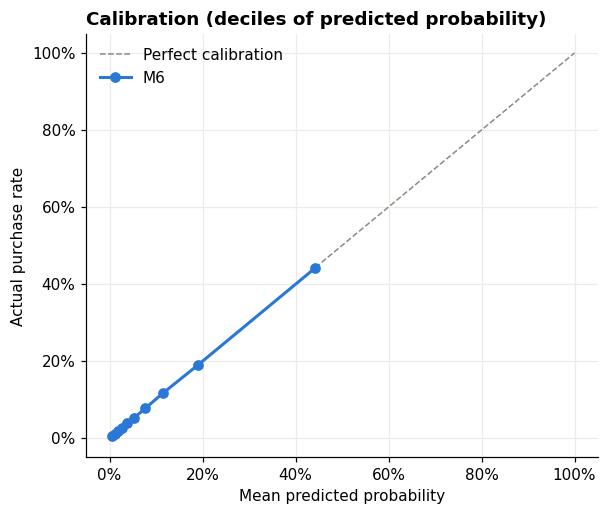

In [47]:
# ==============================
# 7.7.8 Row-level metrics on the evaluation customers
# ==============================
eval_df["p_m6"] = model_lgb.predict(eval_df[FEATURES], num_iteration=model_lgb.best_iteration)

y_true = eval_df["y"]
decay = eval_df["up_decay_score"]
row_metrics = pd.DataFrame({
    "AUC":    [roc_auc_score(y_true, decay), roc_auc_score(y_true, eval_df["p_m6"])],
    "PR-AUC": [average_precision_score(y_true, decay), average_precision_score(y_true, eval_df["p_m6"])],
}, index=["Baseline: up_decay_score (M2a)", "M6 LightGBM"])
display(row_metrics.style.format("{:.3f}"))

# Calibration: are predicted probabilities realistic?
print(f"Log-loss (M6): {log_loss(y_true, eval_df['p_m6']):.4f}")
print(f"Mean predicted probability: {eval_df['p_m6'].mean():.3%} | actual positive rate: {y_true.mean():.3%}")

calib = (eval_df.assign(bin=pd.qcut(eval_df["p_m6"], 10, labels=False, duplicates="drop"))
         .groupby("bin").agg(predicted=("p_m6", "mean"), actual=("y", "mean")))
fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], color=GREY, ls="--", lw=1, label="Perfect calibration")
ax.plot(calib["predicted"], calib["actual"], color=BLUE, lw=2, marker="o", label="M6")
ax.set(title="Calibration (deciles of predicted probability)",
       xlabel="Mean predicted probability", ylabel="Actual purchase rate")
pct_axis(ax); pct_axis(ax, "x")
ax.legend(frameon=False)
plt.show()

#### Training results (row level)

| | AUC | PR-AUC |
|---|---|---|
| Baseline: `up_decay_score` (M2a score) | 0.811 | 0.373 |
| **M6 LightGBM** | **0.839** | **0.436** |

- **Better separation of bought vs. not-bought candidates:** AUC +0.028 and **PR-AUC +17%** (the more relevant metric with only ~10% positives).
- **No overfitting:** validation AUC (0.839, 10% of training customers) equals the AUC on the 30k evaluation customers (0.839), which the model never saw.
- **Fast convergence:** AUC 0.837 at iteration 100; early stopping at iteration **483** with only +0.002 additional gain.
- **Excellent calibration:** mean predicted probability **9.740%** vs. actual rate **9.737%**, and every decile lies on the diagonal (e.g., top decile: ~44% predicted vs. ~44% actual). Predicted probabilities can be **trusted as real purchase probabilities**, which is essential for choosing a personalized K (M7).
- Note: row-level AUC mixes candidates from all customers. What matters for recommendations is the **ranking within each customer**, which is evaluated next with F1@K.

#### Evaluation as a recommender

- For each evaluation customer, candidates are **ranked by the predicted probability** and the top-K are recommended.
- **M6 + fill:** same as M5 fill-only, if a customer has fewer than K history products, the list is filled with M3a discovery products.
- Evaluated with the **same `evaluate()` function and ground truth** as M0–M5 → directly comparable.
- **Feature importance** (total gain) shows which signals the model relies on, including whether the **due ratio** adds information.

In [48]:
# ==============================
# 7.7.9 M6 recommendations and evaluation
# ==============================
recs_m6 = top_k_recs(eval_df, ["p_m6"])
recs_m6_fill = {u: blend(recs_m6.get(u, []), recs_m3a_new.get(u, []), 0, max(KS)) for u in eval_list}

run_eval(recs_m6, "M6 LightGBM")
run_eval(recs_m6_fill, "M6 LightGBM + fill")

# Comparison at every K: best previous model vs. M6
df = pd.DataFrame(results)
keep = ["Ceiling: perfect model", "Ceiling: perfect buy-it-again", "M0 Popularity",
        "M2a Buy-again: frequency + recency", "M5 Hybrid 10+0 (fill only)",
        "M5 Hybrid fill-only (all K)", "M6 LightGBM", "M6 LightGBM + fill"]
cmp = df[df["model"].isin(keep)].sort_values(["K", "f1"])
for k in KS:
    print(f"\nK = {k}")
    display(cmp[cmp["K"] == k].reset_index(drop=True).style.format(FMT))

# Relative gain of M6 + fill vs. M2a
gain = (df[df["model"] == "M6 LightGBM + fill"].set_index("K")[["precision", "recall", "f1", "ndcg"]] /
        df[df["model"] == "M2a Buy-again: frequency + recency"].set_index("K")[["precision", "recall", "f1", "ndcg"]] - 1)
print("\nRelative improvement of M6 + fill over M2a:")
display(gain.style.format("{:+.1%}"))


K = 5


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,M0 Popularity,5,0.094,0.046,0.055,36.1%,0.108,5.0,0.01%,15.4%
1,M2a Buy-again: frequency + recency,5,0.371,0.241,0.249,79.2%,0.434,5.0,34.07%,0.0%
2,M5 Hybrid fill-only (all K),5,0.371,0.241,0.249,79.2%,0.435,5.0,34.07%,0.0%
3,M6 LightGBM,5,0.393,0.255,0.265,81.0%,0.459,5.0,29.18%,0.0%
4,M6 LightGBM + fill,5,0.393,0.255,0.265,81.0%,0.459,5.0,29.18%,0.0%
5,Ceiling: perfect buy-it-again,5,0.714,0.449,0.483,93.4%,0.825,3.6,29.26%,0.0%
6,Ceiling: perfect model,5,0.889,0.621,0.641,100.0%,1.000,4.4,36.10%,40.3%



K = 10


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,M0 Popularity,10,0.073,0.069,0.063,45.5%,0.097,10.0,0.02%,17.8%
1,M2a Buy-again: frequency + recency,10,0.289,0.342,0.270,86.0%,0.415,9.8,47.48%,0.0%
2,M5 Hybrid 10+0 (fill only),10,0.289,0.343,0.271,86.1%,0.416,10.0,47.48%,0.2%
3,M6 LightGBM,10,0.305,0.359,0.286,87.2%,0.438,9.8,40.49%,0.0%
4,M6 LightGBM + fill,10,0.306,0.360,0.286,87.3%,0.439,10.0,40.50%,0.1%
5,Ceiling: perfect buy-it-again,10,0.515,0.554,0.470,93.4%,0.749,5.2,34.70%,0.0%
6,Ceiling: perfect model,10,0.730,0.847,0.699,100.0%,1.000,7.3,45.91%,40.3%



K = 20


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,M0 Popularity,20,0.051,0.094,0.060,51.9%,0.097,20.0,0.04%,20.5%
1,M2a Buy-again: frequency + recency,20,0.206,0.449,0.251,90.2%,0.429,18.5,62.08%,0.0%
2,M5 Hybrid fill-only (all K),20,0.207,0.453,0.253,90.6%,0.431,20.0,62.08%,0.5%
3,M6 LightGBM,20,0.216,0.464,0.262,90.9%,0.449,18.5,54.70%,0.0%
4,M6 LightGBM + fill,20,0.217,0.469,0.263,91.3%,0.451,20.0,54.70%,0.5%
5,Ceiling: perfect buy-it-again,20,0.306,0.597,0.361,93.4%,0.700,6.1,37.35%,0.0%
6,Ceiling: perfect model,20,0.487,0.974,0.585,100.0%,1.000,9.7,51.48%,40.1%



Relative improvement of M6 + fill over M2a:


,precision,recall,f1,ndcg
K,,,,
5,+5.9%,+5.8%,+6.1%,+5.7%
10,+5.9%,+5.3%,+5.8%,+5.6%
20,+5.1%,+4.4%,+4.9%,+5.2%


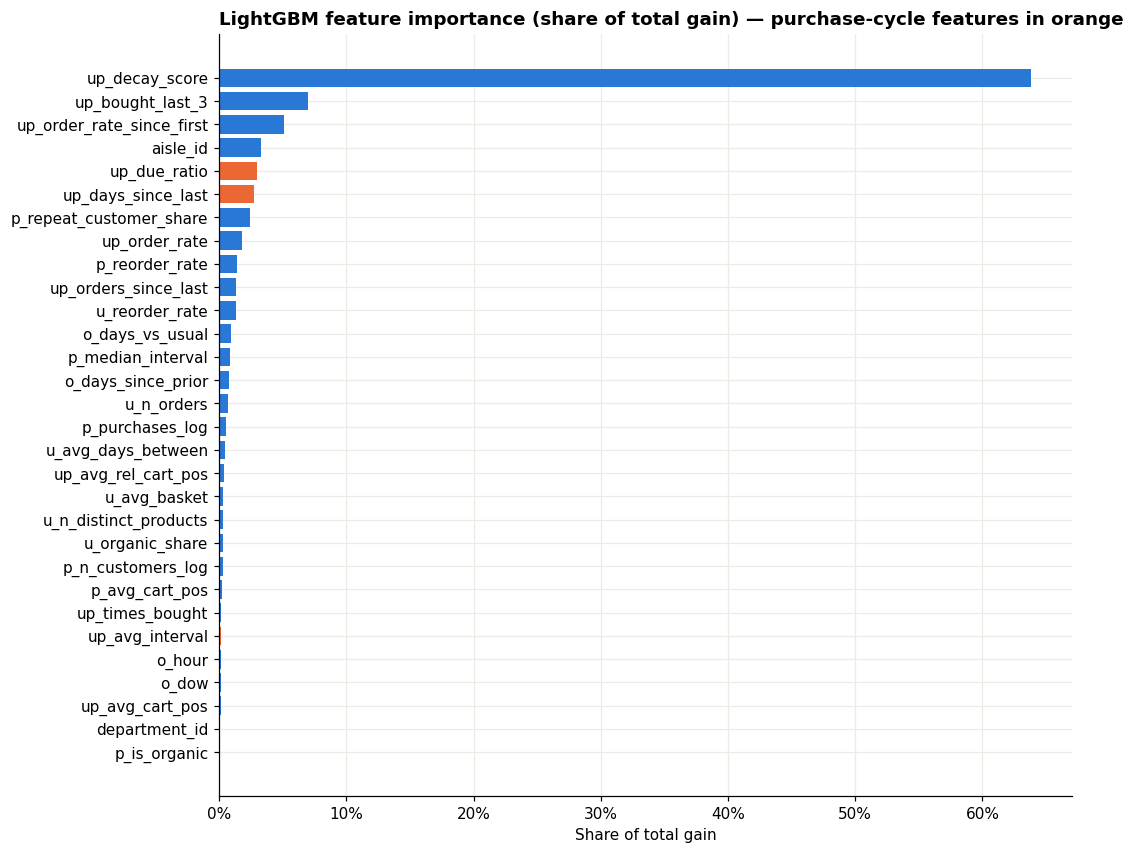

,feature,gain,splits,gain_share
0,up_decay_score,"5,091,281",909,63.8%
1,up_bought_last_3,"557,990",171,7.0%
2,up_order_rate_since_first,"405,787",533,5.1%
3,aisle_id,"259,444","7,432",3.3%
4,up_due_ratio,"234,582","1,107",2.9%
5,up_days_since_last,"218,620","1,697",2.7%
6,p_repeat_customer_share,"194,941",834,2.4%
7,up_order_rate,"143,698",858,1.8%
8,p_reorder_rate,"113,273",711,1.4%
9,up_orders_since_last,"107,985",422,1.4%


In [49]:
# ==============================
# 7.7.10 Feature importance (total gain)
# ==============================
imp = pd.DataFrame({
    "feature": FEATURES,
    "gain": model_lgb.feature_importance(importance_type="gain"),
    "splits": model_lgb.feature_importance(importance_type="split"),
})
imp["gain_share"] = imp["gain"] / imp["gain"].sum()
imp = imp.sort_values("gain_share", ascending=False).reset_index(drop=True)

cycle_feats = {"up_due_ratio", "up_avg_interval", "up_days_since_last"}
colors = [ORANGE if f in cycle_feats else BLUE for f in imp["feature"]]

fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(imp["feature"][::-1], imp["gain_share"][::-1], color=colors[::-1])
ax.set(title="LightGBM feature importance (share of total gain) — purchase-cycle features in orange",
       xlabel="Share of total gain")
pct_axis(ax, "x")
plt.show()

display(imp.style.format({"gain": "{:,.0f}", "splits": "{:,}", "gain_share": "{:.1%}"}))

In [50]:
# ==============================
# 7.7.11 Where does M6 improve? (F1@10 by segment)
# ==============================
seg["M5 fill-only"] = per_user_results[("M5 Hybrid 10+0 (fill only)", 10)]["f1"]
seg["M6 + fill"]    = per_user_results[("M6 LightGBM + fill", 10)]["f1"]
seg["gain"]         = seg["M6 + fill"] / seg["M5 fill-only"] - 1

for col in ["history_orders", "reorder_rate"]:
    t = seg.groupby(col, observed=True).agg(customers=("gain", "size"),
                                            m5=("M5 fill-only", "mean"),
                                            m6=("M6 + fill", "mean"))
    t["relative_gain"] = t["m6"] / t["m5"] - 1
    print(f"\nMean F1@10 by {col}:")
    display(t.style.format({"customers": "{:,}", "m5": "{:.3f}", "m6": "{:.3f}", "relative_gain": "{:+.1%}"}))


Mean F1@10 by history_orders:


,customers,m5,m6,relative_gain
history_orders,,,,
3–5,"8,682",0.236,0.251,+6.2%
6–10,"7,563",0.260,0.277,+6.2%
11–20,"6,695",0.283,0.299,+5.9%
21–50,"5,544",0.311,0.326,+4.7%
51–99,"1,516",0.323,0.333,+3.2%



Mean F1@10 by reorder_rate:


,customers,m5,m6,relative_gain
reorder_rate,,,,
<20% (explorer),"3,280",0.131,0.148,+13.4%
20–40%,"7,141",0.206,0.223,+8.3%
40–60%,"9,659",0.274,0.289,+5.3%
≥60% (routine),"9,920",0.361,0.375,+3.8%


### 7.7 M6 — Results

**Comparison with the best previous models**
| Model | K | Precision | Recall | F1 | Hit Rate | NDCG | Coverage |
|---|---|---|---|---|---|---|---|
| M2a Buy-again | 5 | 0.371 | 0.241 | 0.249 | 79.2% | 0.434 | 34.1% |
| **M6 LightGBM + fill** | 5 | **0.393** | **0.255** | **0.265** | **81.0%** | **0.459** | 29.2% |
| M2a Buy-again | 10 | 0.289 | 0.342 | 0.270 | 86.0% | 0.415 | 47.5% |
| M5 Hybrid fill-only | 10 | 0.289 | 0.343 | 0.271 | 86.1% | 0.416 | 47.5% |
| **M6 LightGBM + fill** | 10 | **0.306** | **0.360** | **0.286** | **87.3%** | **0.439** | 40.5% |
| M2a Buy-again | 20 | 0.206 | 0.449 | 0.251 | 90.2% | 0.429 | 62.1% |
| **M6 LightGBM + fill** | 20 | **0.217** | **0.469** | **0.263** | **91.3%** | **0.451** | 54.7% |
| *Ceiling: perfect buy-it-again* | 10 | 0.515 | 0.554 | 0.470 | 93.4% | 0.749 | 34.7% |

**1. LightGBM is the best model at every K**
- Relative improvement over M2a: **F1 +6.1% / +5.8% / +4.9%** and **NDCG +5.7% / +5.6% / +5.2%** at K = 5 / 10 / 20.
- At K = 10 it reaches **61% of the buy-it-again ceiling** in F1 (vs. 57% for M2a).
- F1 still peaks at **K = 10**.
- Trade-off: **coverage drops** from 47.5% to 40.5%. The model favors products that are staples for many customers, which slightly reduces diversity.

**2. Feature importance (share of total gain)**
| Rank | Feature | Gain share | Group |
|---|---|---|---|
| 1 | `up_decay_score` | **63.8%** | Recency-weighted frequency |
| 2 | `up_bought_last_3` | 7.0% | Recency |
| 3 | `up_order_rate_since_first` | 5.1% | Frequency |
| 4 | `aisle_id` | 3.3% | Product type |
| **5** | **`up_due_ratio`** | **2.9%** | **Purchase cycle** |
| 6 | `up_days_since_last` | 2.7% | Purchase cycle / recency |
| 7 | `p_repeat_customer_share` | 2.4% | Product staple-ness |
| … | order context (`o_days_vs_usual`, `o_days_since_prior`, hour, day) | 0.1–1.0% | Context |

- **Recency-weighted frequency dominates** (~64%), confirming that M2a's score was already the core signal.
- **The model uses the purchase cycle:** `up_due_ratio` ranks **5th** and the cycle features together account for **~5.8%** of the gain. However, the **ablation study (section 7.9)** shows that their actual incremental value is small (~0.3% F1): recency and frequency already capture most of that information.
- **Product type matters:** `aisle_id` and the product's share of repeat customers help separate staples from occasional products.
- **Time of day and day of week are almost irrelevant** (≤0.2%), consistent with the EDA (similar hourly patterns across days).
- Note: gain importance shows what the model *uses*, not a causal contribution. The **ablation study** in section 7.9 quantifies the real contribution of the purchase-cycle features.

**3. The largest gains are where simple models struggle**

| Segment | M5 fill-only | M6 + fill | Relative gain |
|---|---|---|---|
| History 3–5 orders | 0.236 | 0.251 | **+6.2%** |
| History 51–99 orders | 0.323 | 0.333 | +3.2% |
| Explorers (<20% reorders) | 0.131 | 0.148 | **+13.4%** |
| Routine (≥60% reorders) | 0.361 | 0.375 | +3.8% |

- M6 improves **every segment**, but the gains are **largest for explorers (+13.4%)** and **customers with short histories (+6.2%)**.
- For routine customers, ranking by frequency is already near-optimal. For less predictable customers, the additional signals (product staple-ness, aisle, purchase cycles, customer profile) make a bigger difference.

**Best model so far: M6 LightGBM + fill**, F1@10 = 0.286, NDCG@10 = 0.439.

**Next step:** since the model is well calibrated, its probabilities can be used to decide **how many** products to recommend to each customer (**M7, personalized K**).

### 7.8 M7 — Personalized K (Variable-Length Recommendations)

**Goal:** instead of recommending a fixed K = 10 products to everyone, decide **how many** products to recommend to each customer, using M6's (well-calibrated) probabilities. This is the natural setting for a **pre-filled cart**, where every extra product is friction.

**Metric:** precision, recall and **F1 per order** with each customer's own list length (`evaluate(..., k=None)`). This is the Kaggle-style metric. Fixed-K results are directly comparable because their lists have exactly K products.

**Strategies**
| Strategy | K for customer *u* | Parameters |
|---|---|---|
| **Fixed K = 10** (reference) | 10 | — |
| **Customer rule** | round(avg. basket size × reorder rate) → *typical number of reorders* | none |
| **Expected count** | round(Σ P(purchase) over candidates) → *expected number of reorders* | none |
| **Probability threshold** | all candidates with P ≥ *t* (at least 1) | *t* tuned on **validation customers** |
| **Expected-F1 maximization** | k that maximizes $\frac{2 \sum_{i \le k} p_i}{k + E[\,|T_u|\,]}$ | none |

For the expected-F1 strategy, $p_i$ are the sorted probabilities and $E[|T_u|]$ is the expected size of the next order: expected reorders ($\sum p_i$) **plus** expected new products (avg. basket × (1 − reorder rate)), since the ground truth also contains products the model cannot predict.

To separate the effect of **better ranking** from that of **better list length**, the customer rule is also applied to **M2a**.

In [51]:
# ==============================
# 7.8.1 Ranked candidates with probabilities (evaluation customers)
# ==============================
ranked = (eval_df[["user_id", "product_id", "p_m6"]]
          .sort_values(["user_id", "p_m6"], ascending=[True, False])
          .reset_index(drop=True))
ranked["rank"]  = ranked.groupby("user_id").cumcount() + 1
ranked["cum_p"] = ranked.groupby("user_id")["p_m6"].cumsum()

def recs_by_k(k_per_user):
    """Top-k_u products per customer from the M6 ranking."""
    sel = ranked[ranked["rank"] <= ranked["user_id"].map(k_per_user)]
    return sel.groupby("user_id")["product_id"].apply(list).to_dict()

uf = user_feat.reindex(eval_list)

# ==============================
# 7.8.2 Customer rule: typical number of reorders per order
# ==============================
k_rule = (uf["u_avg_basket"] * uf["u_reorder_rate"]).round().clip(1, 20).astype(int)

recs_m7_rule     = recs_by_k(k_rule)
recs_m2a_rule    = {u: recs_m2a.get(u, [])[:k_rule[u]] for u in eval_list}
run_eval(recs_m7_rule,  "M7 M6 + K customer rule", ks=[None])
run_eval(recs_m2a_rule, "M7 M2a + K customer rule", ks=[None])

# ==============================
# 7.8.3 Expected count: sum of predicted probabilities
# ==============================
k_expected = ranked.groupby("user_id")["p_m6"].sum().round().clip(1, 20).astype(int)
recs_m7_expected = recs_by_k(k_expected)
run_eval(recs_m7_expected, "M7 M6 + K expected count", ks=[None])

print(f"Average K — customer rule: {k_rule.mean():.1f} | expected count: {k_expected.mean():.1f}")

Average K — customer rule: 5.0 | expected count: 6.3


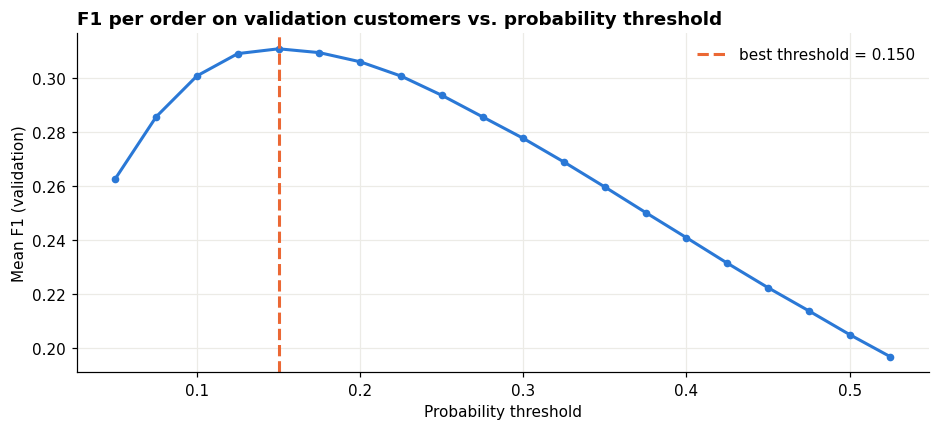

,threshold,f1_valid,avg_list_len
0,0.050,0.2629,30.6
1,0.075,0.2858,23.1
2,0.100,0.3009,18.3
3,0.125,0.3092,14.9
4,0.150,0.3110,12.4
5,0.175,0.3095,10.6
6,0.200,0.3062,9.1
7,0.225,0.3009,7.9
8,0.250,0.2937,6.9
9,0.275,0.2857,6.1


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage,new_hits_share
0,M7 M6 + threshold 0.150,variable,0.311,0.383,0.312,0.823,0.438,12.295,0.422,0.000


In [52]:
# ==============================
# 7.8.4 Probability threshold, tuned on VALIDATION customers (not the evaluation sample)
# ==============================
val_mask = ~fit_mask
valid_df = train_df.loc[val_mask, ["user_id", "product_id", "y"]].copy()
valid_df["p"] = model_lgb.predict(train_df.loc[val_mask, FEATURES], num_iteration=model_lgb.best_iteration)
valid_df["rank"] = valid_df.groupby("user_id")["p"].rank(method="first", ascending=False)

next_order_size = train_u.groupby("user_id").size()          # full next order (incl. new products)
T_valid = next_order_size.reindex(valid_df["user_id"].unique())

grid = []
for t in np.arange(0.05, 0.55, 0.025):
    sel = (valid_df["p"] >= t) | (valid_df["rank"] == 1)     # at least 1 product per customer
    g = valid_df[sel].groupby("user_id").agg(tp=("y", "sum"), n=("y", "size"))
    f1 = 2 * g["tp"] / (g["n"] + T_valid.loc[g.index])
    grid.append((t, f1.mean(), g["n"].mean()))
grid = pd.DataFrame(grid, columns=["threshold", "f1_valid", "avg_list_len"])
best_t = grid.loc[grid["f1_valid"].idxmax(), "threshold"]

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(grid["threshold"], grid["f1_valid"], color=BLUE, lw=2, marker="o", ms=4)
ax.axvline(best_t, color=ORANGE, ls="--", lw=2, label=f"best threshold = {best_t:.3f}")
ax.set(title="F1 per order on validation customers vs. probability threshold",
       xlabel="Probability threshold", ylabel="Mean F1 (validation)")
ax.legend(frameon=False)
plt.show()
display(grid.style.format({"threshold": "{:.3f}", "f1_valid": "{:.4f}", "avg_list_len": "{:.1f}"})
             .highlight_max(subset=["f1_valid"], color="#cde2fb"))

# Apply the tuned threshold to the evaluation customers
sel = ranked[(ranked["p_m6"] >= best_t) | (ranked["rank"] == 1)]
recs_m7_threshold = sel.groupby("user_id")["product_id"].apply(list).to_dict()
run_eval(recs_m7_threshold, f"M7 M6 + threshold {best_t:.3f}", ks=[None])

In [53]:
# ==============================
# 7.8.5 Expected-F1 maximization per customer
# ==============================
# Expected size of the next order = expected reorders + expected new products
exp_reorders = ranked.groupby("user_id")["p_m6"].sum()
exp_new      = (uf["u_avg_basket"] * (1 - uf["u_reorder_rate"])).clip(lower=0)
exp_T        = exp_reorders + exp_new

ranked["exp_f1"] = 2 * ranked["cum_p"] / (ranked["rank"] + ranked["user_id"].map(exp_T))
best_idx = ranked.groupby("user_id")["exp_f1"].idxmax()
k_f1opt = ranked.loc[best_idx].set_index("user_id")["rank"].astype(int)

recs_m7_f1opt = recs_by_k(k_f1opt)
run_eval(recs_m7_f1opt, "M7 M6 + expected-F1 maximization", ks=[None])
print(f"Average K — expected-F1 maximization: {k_f1opt.mean():.1f}")

Average K — expected-F1 maximization: 13.1


,model,K,precision,recall,f1,hit_rate,ndcg,avg_list_len,coverage
0,M7 M6 + expected-F1 maximization,variable,0.315,0.390,0.325,86.9%,0.431,13.1,43.60%
1,M7 M6 + threshold 0.150,variable,0.311,0.383,0.312,82.3%,0.438,12.3,42.22%
2,M7 M6 + K expected count,variable,0.393,0.267,0.296,77.5%,0.440,6.3,31.35%
3,M6 LightGBM + fill,10,0.306,0.360,0.286,87.3%,0.439,10.0,40.50%
4,M7 M6 + K customer rule,variable,0.422,0.234,0.274,74.0%,0.459,5.0,28.53%
5,M2a Buy-again: frequency + recency,10,0.289,0.342,0.270,86.0%,0.415,9.8,47.48%
6,M6 LightGBM + fill,5,0.393,0.255,0.265,81.0%,0.459,5.0,29.18%
7,M6 LightGBM + fill,20,0.217,0.469,0.263,91.3%,0.451,20.0,54.70%
8,M7 M2a + K customer rule,variable,0.396,0.221,0.259,72.2%,0.432,5.0,31.28%
9,M2a Buy-again: frequency + recency,20,0.206,0.449,0.251,90.2%,0.429,18.5,62.08%


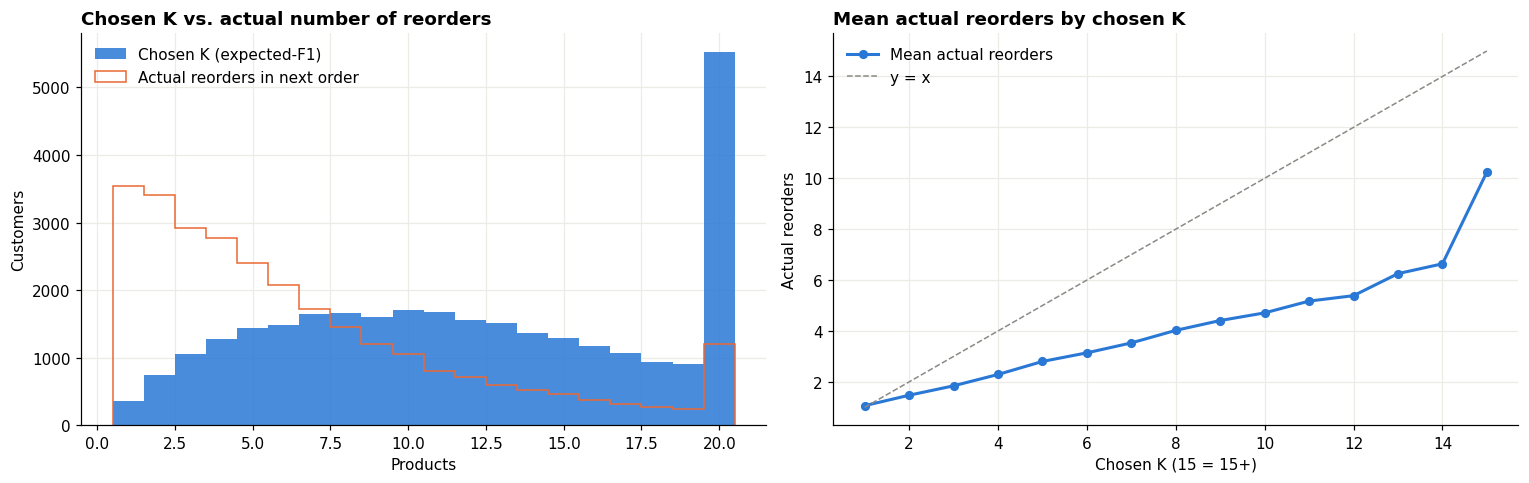

Spearman correlation (chosen K vs. actual reorders): 0.59


In [54]:
# ==============================
# 7.8.6 Comparison: fixed K vs. variable K (F1 per order)
# ==============================
df = pd.DataFrame(results)
fixed = df[df["model"].isin(["M2a Buy-again: frequency + recency", "M6 LightGBM + fill"]) & df["K"].isin([5, 10, 20])]
variable = df[df["model"].str.startswith("M7")]
cmp = pd.concat([fixed, variable]).sort_values("f1", ascending=False)
display(cmp[["model", "K", "precision", "recall", "f1", "hit_rate", "ndcg", "avg_list_len", "coverage"]]
        .reset_index(drop=True).style.format(FMT).highlight_max(subset=["f1"], color="#cde2fb"))

# ==============================
# 7.8.7 Chosen K vs. actual next-order size
# ==============================
actual_size = pd.Series({u: len(t) for u, t in truth_full.items()})
actual_reorders = pd.Series({u: len(t & history.get(u, set())) for u, t in truth_full.items()})

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
bins_k = np.arange(0.5, 21.5, 1)
axes[0].hist(k_f1opt.clip(upper=20), bins=bins_k, color=BLUE, alpha=0.85, label="Chosen K (expected-F1)")
axes[0].hist(actual_reorders.clip(upper=20), bins=bins_k, histtype="step", color=ORANGE, lw=2,
             label="Actual reorders in next order")
axes[0].set(title="Chosen K vs. actual number of reorders", xlabel="Products", ylabel="Customers")
axes[0].legend(frameon=False)

comp = pd.DataFrame({"k": k_f1opt, "actual": actual_reorders}).dropna()
by_k = comp.groupby(comp["k"].clip(upper=15))["actual"].mean()
axes[1].plot(by_k.index, by_k.values, color=BLUE, lw=2, marker="o", ms=5, label="Mean actual reorders")
axes[1].plot([1, 15], [1, 15], color=GREY, ls="--", lw=1, label="y = x")
axes[1].set(title="Mean actual reorders by chosen K", xlabel="Chosen K (15 = 15+)", ylabel="Actual reorders")
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"Spearman correlation (chosen K vs. actual reorders): "
      f"{comp.corr(method='spearman').iloc[0, 1]:.2f}")

### 7.8 M7 — Results

**F1 per order: fixed K vs. variable K**
| Model / strategy | K | Precision | Recall | F1 | Hit Rate | NDCG | Avg. list length | Coverage |
|---|---|---|---|---|---|---|---|---|
| **M6 + expected-F1 maximization** | variable | 0.315 | **0.390** | **0.325** | 86.9% | 0.431 | 13.1 | 43.6% |
| M6 + threshold 0.150 | variable | 0.311 | 0.383 | 0.312 | 82.3% | 0.438 | 12.3 | 42.2% |
| M6 + K expected count | variable | 0.393 | 0.267 | 0.296 | 77.5% | 0.440 | 6.3 | 31.4% |
| M6 LightGBM + fill | 10 | 0.306 | 0.360 | 0.286 | 87.3% | 0.439 | 10.0 | 40.5% |
| M6 + K customer rule | variable | **0.422** | 0.234 | 0.274 | 74.0% | **0.459** | 5.0 | 28.5% |
| M2a Buy-again | 10 | 0.289 | 0.342 | 0.270 | 86.0% | 0.415 | 9.8 | 47.5% |
| M2a + K customer rule | variable | 0.396 | 0.221 | 0.259 | 72.2% | 0.432 | 5.0 | 31.3% |

**1. Personalizing K is the single largest improvement of the project**
- **Expected-F1 maximization** reaches **F1 = 0.325**: **+13.6%** vs. M6 with fixed K = 10 and **+20%** vs. M2a.
- The **probability threshold** (tuned on validation customers) is close behind: **0.312**. Its validation F1 (0.311) matches the evaluation F1, so the tuning generalizes.

**2. Separating the two effects**
- **Better ranking, same K:** M6 vs. M2a with the customer rule → 0.274 vs. 0.259 (**+5.8%**), the same gain as with fixed K.
- **Better K, same model:** M6 fixed K = 10 vs. expected-F1 maximization → 0.286 vs. 0.325 (**+13.6%**).
- → Deciding **how many** products to recommend is worth **more than twice** the gain of a better ranking model. Both effects are complementary.

**3. Intuitive rules recommend too few products**
- Recommending "as many products as the customer usually reorders" (**customer rule**, avg. K = 5.0) or "as many as the model expects" (**expected count**, avg. K = 6.3) maximizes **precision** (0.42 / 0.39) but sacrifices recall, and F1 ends up **below or close to fixed K = 10**.
- **The F1-optimal list is about 2× the number of products actually reordered:** when the model picks K = 10, customers reorder ~4.7 products on average (right chart). Including products with moderate probability improves recall more than it hurts precision.
- This matches a known theoretical result: the **F1-optimal probability threshold is about half of the achievable F1** (0.150 ≈ 0.31 / 2).

**4. The chosen K adapts to each customer**
- The chosen K spans the whole range (1 to 20+, avg. 13.1), while actual reorders are concentrated in small numbers.
- Chosen K and actual reorders grow together **monotonically** (Spearman correlation **0.59**): the model correctly identifies which customers will repeat many products and which will repeat few.

**Business implications**
- **For a pre-filled cart**, the list length should be **personalized**, not fixed.
- **F1 weights false positives and misses equally**, which may not match the business cost:
  - If removing unwanted products from a pre-filled cart is very annoying, **precision matters more** → use a **higher threshold** (e.g., t = 0.30 → ~5 products, higher precision).
  - If the goal is to **remind** customers of everything they might need, **recall matters more** → use a lower threshold or longer lists.
- The **threshold curve** gives the business a **menu of trade-offs** between list length, precision and recall, to be validated with **A/B tests**.

**Best overall model: M6 LightGBM + expected-F1 maximization**, F1 per order = **0.325**.

### 7.9 Ablation Study: How Much Do Purchase Cycles Contribute?

Feature importance shows what the model *uses*, but not how much performance would be lost without a feature (correlated features can partially replace each other). An **ablation study** answers this directly: retrain the model **without** a feature group and measure the drop.

| Variant | Features removed | Question |
|---|---|---|
| **Full model** | — (30 features) | Reference (M6 / M7) |
| **No due ratio** | `up_due_ratio` | What does the due ratio add on its own? |
| **No purchase-cycle features** | `up_due_ratio`, `up_avg_interval`, `up_days_since_last` | What does day-based cycle information add as a whole? |

**Fair comparison:** same parameters, same fit/validation customers, same early stopping and same evaluation customers. Each variant is evaluated on:
- **Row level:** AUC and PR-AUC.
- **Fixed K = 10** (+ fill): F1@10 and NDCG@10 → ranking quality (M6).
- **Personalized K** (expected-F1 maximization): F1 per order → final system (M7).

In [55]:
# ==============================
# 7.9.1 Train and evaluate a model variant
# ==============================
def run_variant(name, feats, seed=SEED):
    cats = [c for c in CATEGORICAL if c in feats]
    dtr = lgb.Dataset(train_df.loc[fit_mask, feats], train_df.loc[fit_mask, "y"],
                      categorical_feature=cats, free_raw_data=True)
    dva = lgb.Dataset(train_df.loc[~fit_mask, feats], train_df.loc[~fit_mask, "y"],
                      categorical_feature=cats, reference=dtr)
    m = lgb.train({**params, "seed": seed}, dtr, num_boost_round=2_000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)])
    pred = m.predict(eval_df[feats], num_iteration=m.best_iteration)

    # Fixed K = 10 (+ fill)
    tmp = eval_df[["user_id", "product_id"]].assign(p=pred)
    recs = top_k_recs(tmp, ["p"])
    recs_fill = {u: blend(recs.get(u, []), recs_m3a_new.get(u, []), 0, max(KS)) for u in eval_list}
    s10, _ = evaluate(recs_fill, k=10, name=name)

    # Personalized K (expected-F1 maximization)
    r = tmp.sort_values(["user_id", "p"], ascending=[True, False]).reset_index(drop=True)
    r["rank"]  = r.groupby("user_id").cumcount() + 1
    r["cum_p"] = r.groupby("user_id")["p"].cumsum()
    exp_T_v = r.groupby("user_id")["p"].sum() + exp_new
    r["ef1"] = 2 * r["cum_p"] / (r["rank"] + r["user_id"].map(exp_T_v))
    k_opt = r.loc[r.groupby("user_id")["ef1"].idxmax()].set_index("user_id")["rank"]
    sel = r[r["rank"] <= r["user_id"].map(k_opt)]
    s_var, _ = evaluate(sel.groupby("user_id")["product_id"].apply(list).to_dict(), k=None, name=name)

    return {
        "variant": name, "n_features": len(feats), "best_iteration": m.best_iteration,
        "AUC": roc_auc_score(eval_df["y"], pred),
        "PR-AUC": average_precision_score(eval_df["y"], pred),
        "F1@10": s10["f1"], "NDCG@10": s10["ndcg"], "F1 personalized K": s_var["f1"],
    }

In [56]:
# ==============================
# 7.9.2 Run the ablation
# ==============================
CYCLE_FEATURES = ["up_due_ratio", "up_avg_interval", "up_days_since_last"]

# Full model: reuse the already-trained M6 / M7 results (same split and parameters)
df = pd.DataFrame(results)
ablation = [{
    "variant": "Full model", "n_features": len(FEATURES), "best_iteration": model_lgb.best_iteration,
    "AUC": roc_auc_score(eval_df["y"], eval_df["p_m6"]),
    "PR-AUC": average_precision_score(eval_df["y"], eval_df["p_m6"]),
    "F1@10": df[(df["model"] == "M6 LightGBM + fill") & (df["K"] == 10)]["f1"].iloc[0],
    "NDCG@10": df[(df["model"] == "M6 LightGBM + fill") & (df["K"] == 10)]["ndcg"].iloc[0],
    "F1 personalized K": df[df["model"] == "M7 M6 + expected-F1 maximization"]["f1"].iloc[0],
}]

variants = {
    "No due ratio": [f for f in FEATURES if f != "up_due_ratio"],
    "No purchase-cycle features": [f for f in FEATURES if f not in CYCLE_FEATURES],
}
for name, feats in variants.items():
    ablation.append(run_variant(name, feats))
    print(f"✓ {name} ({len(feats)} features)")

# Optional: noise reference → retrain the FULL model with another seed.
# Differences between variants smaller than this are within random variation.
RUN_NOISE_CHECK = False
if RUN_NOISE_CHECK:
    ablation.append(run_variant("Full model (seed 2)", FEATURES, seed=SEED + 1))
    print("✓ Full model (seed 2)")

✓ No due ratio (29 features)
✓ No purchase-cycle features (27 features)


,n_features,best_iteration,AUC,PR-AUC,F1@10,NDCG@10,F1 personalized K
variant,,,,,,,
Full model,30,483,0.8386,0.4359,0.2862,0.4387,0.3251
No due ratio,29,434,0.8385,0.4360,0.2862,0.4388,0.3250
No purchase-cycle features,27,713,0.8373,0.4339,0.2854,0.4373,0.3241



Relative change vs. the full model:


,AUC Δ%,PR-AUC Δ%,F1@10 Δ%,NDCG@10 Δ%,F1 personalized K Δ%
variant,,,,,
Full model,+0.00%,+0.00%,+0.00%,+0.00%,+0.00%
No due ratio,-0.01%,+0.03%,-0.03%,+0.01%,-0.05%
No purchase-cycle features,-0.15%,-0.45%,-0.30%,-0.33%,-0.33%


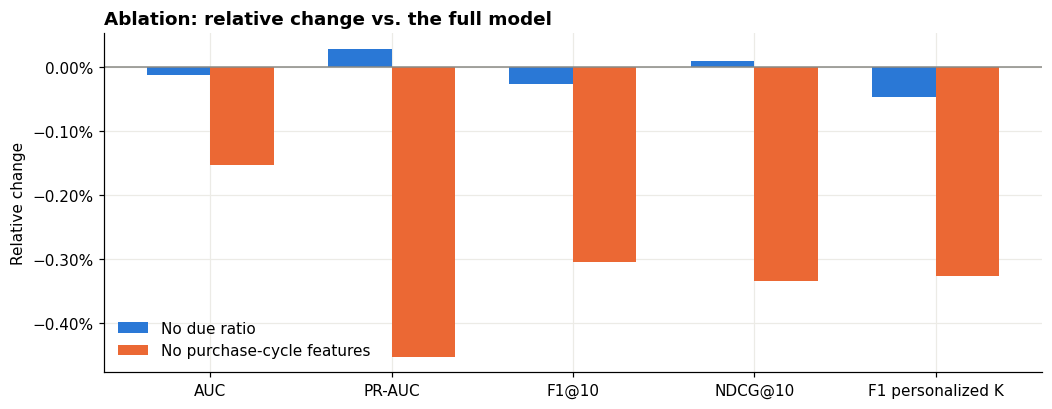

In [57]:
# ==============================
# 7.9.3 Ablation results
# ==============================
abl = pd.DataFrame(ablation).set_index("variant")
metrics = ["AUC", "PR-AUC", "F1@10", "NDCG@10", "F1 personalized K"]
delta = (abl[metrics] / abl.loc["Full model", metrics] - 1).add_suffix(" Δ%")

display(abl.style.format({"best_iteration": "{:,}", **{m: "{:.4f}" for m in metrics}}))
print("\nRelative change vs. the full model:")
display(delta.style.format("{:+.2%}"))

fig, ax = plt.subplots(figsize=(11, 4))
x = np.arange(len(metrics))
width = 0.35
for i, v in enumerate([idx for idx in abl.index if idx != "Full model"]):
    ax.bar(x + (i - 0.5) * width, delta.loc[v].values, width=width,
           color=[BLUE, ORANGE, GREEN][i], label=v)
ax.axhline(0, color=GREY, lw=1)
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set(title="Ablation: relative change vs. the full model", ylabel="Relative change")
pct_axis(ax)
ax.legend(frameon=False)
plt.show()

### 7.9 Ablation — Results

| Variant | Features | Iterations | AUC | PR-AUC | F1@10 | NDCG@10 | F1 personalized K |
|---|---|---|---|---|---|---|---|
| Full model | 30 | 483 | 0.8386 | 0.4359 | 0.2862 | 0.4387 | 0.3251 |
| No due ratio | 29 | 434 | 0.8385 | 0.4360 | 0.2862 | 0.4388 | 0.3250 |
| No purchase-cycle features | 27 | 713 | 0.8373 | 0.4339 | 0.2854 | 0.4373 | 0.3241 |

**Relative change vs. the full model**
| Variant | AUC | PR-AUC | F1@10 | NDCG@10 | F1 personalized K |
|---|---|---|---|---|---|
| No due ratio | −0.01% | +0.03% | −0.03% | +0.01% | −0.05% |
| No purchase-cycle features | −0.15% | −0.45% | −0.30% | −0.33% | −0.33% |

**1. The due ratio on its own adds practically nothing**
- Removing `up_due_ratio` leaves every metric unchanged (changes between −0.05% and +0.03%).
- The remaining cycle features (`up_days_since_last`, `up_avg_interval`) **almost fully compensate** for its absence: the model can reconstruct the same information from them.

**2. Purchase-cycle information as a whole adds a small but consistent gain**
- Removing all three cycle features lowers **every metric** in the same direction: **−0.30% F1@10**, **−0.33% F1 with personalized K**, **−0.45% PR-AUC**.
- The model without them needs **more trees** (713 vs. 483 iterations) to partially compensate using recency and frequency features.
- Differences of this size may be close to the random variation between training runs; a retraining with a different seed (`RUN_NOISE_CHECK = True`) would confirm it. The consistent direction across all five metrics suggests a **real but small** effect.

**3. Feature importance overstated the contribution**
- `up_due_ratio` ranked **5th in gain importance (2.9%)**, yet removing it has no measurable impact.
- **Importance shows what the model *uses*, not what it *needs*:** when features are correlated, removing one lets the others take over. Ablation measures the true **incremental value**.

**Conclusion on the purchase-cycle hypothesis (H3)**
- Purchase cycles are a **real behavioral pattern** (clear in the EDA: 28% vs. 17.5% purchase rate when a product is due).
- For **ranking** products, however, most of that information is already captured by **recency and frequency**: its incremental value is about **+0.3%**.
- Its main business value lies in **timing**, i.e., deciding **when** to send reorder reminders (optimal window: due ratio ≈ 0.75–1.25), rather than in improving the order of recommendations.

## 8. Conclusions and Business Recommendations

### 8.1 Results Summary

| Model | Idea | K | F1 | NDCG | Main takeaway |
|---|---|---|---|---|---|
| M0 Popularity | Same best-sellers for everyone | 10 | 0.063 | 0.097 | Weak floor; near-zero coverage |
| M1 Buy-again: frequency | Customer's most bought products | 10 | 0.259 | 0.398 | **4×** popularity: history is the key signal |
| M2a + recency | Time-decayed frequency | 10 | 0.270 | 0.415 | Recency adds +4% |
| M2b + purchase cycle (rule) | Due-ratio multiplier | 10 | 0.270 | 0.414 | No gain as a hand-crafted rule |
| M3a Item-item CF | Similar customers' products | 10 (new only) | 0.030 | 0.045 | Best discovery model, but ~2.5% precision |
| M4 Association rules | Co-purchase complements | 10 (new only) | 0.018–0.027 | 0.026–0.040 | Complements depend on session context |
| M5 Hybrid fill-only | Buy-again + discovery fill | 10 | 0.271 | 0.416 | Mixing in discovery slots always lowers accuracy |
| M6 LightGBM + fill | Supervised ranking of history (30 features) | 10 | 0.286 | 0.439 | **+6%** over M2a; largest gains for explorers |
| **M7 LightGBM + expected-F1 K** | **Personalized list length** | **variable** | **0.325** | 0.431 | **+13.6%** over fixed K: the largest single gain |

**Reference ceilings (K = 10):** perfect buy-it-again F1 = 0.470 · perfect model F1 = 0.699.

*Note: these ceilings assume a **fixed K = 10**. With a personalized K, a perfect buy-it-again model could score higher (no unused slots), so they are a reference for M0–M6 rather than exact ceilings for M7.*

**In practical terms:** with the final model, a customer's personalized list (~13 products on average) contains **~4 products they actually buy** in their next order, covering **~39% of that order**.

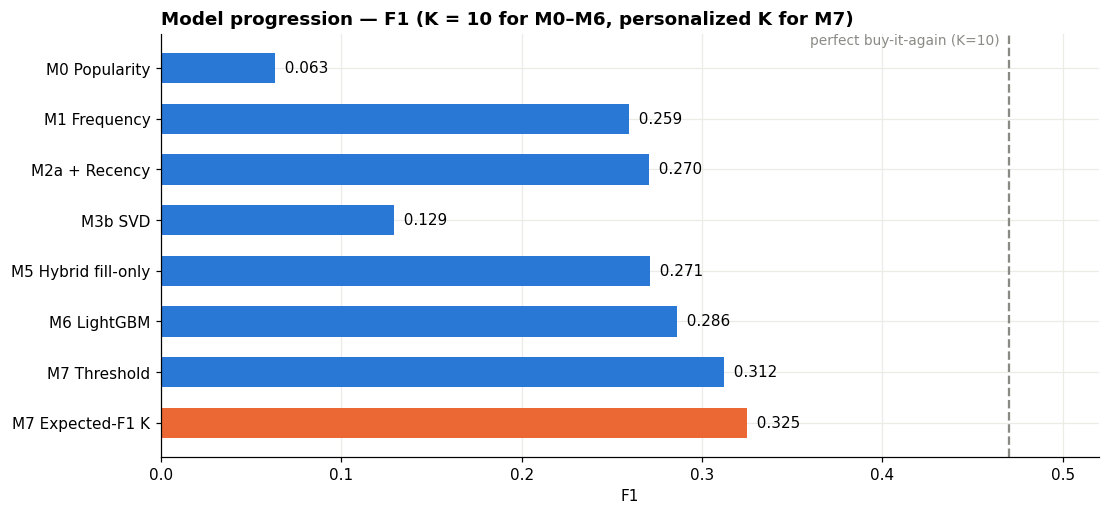

In [58]:
# ==============================
# 8.1.1 Model progression (main F1 metric)
# ==============================
df = pd.DataFrame(results)
journey = [
    ("M0 Popularity", 10, "M0 Popularity"),
    ("M1 Buy-again: frequency", 10, "M1 Frequency"),
    ("M2a Buy-again: frequency + recency", 10, "M2a + Recency"),
    ("M3b SVD", 10, "M3b SVD"),
    ("M5 Hybrid 10+0 (fill only)", 10, "M5 Hybrid fill-only"),
    ("M6 LightGBM + fill", 10, "M6 LightGBM"),
    (f"M7 M6 + threshold {best_t:.3f}", "variable", "M7 Threshold"),
    ("M7 M6 + expected-F1 maximization", "variable", "M7 Expected-F1 K"),
]
vals = [df[(df["model"] == m) & (df["K"] == k)]["f1"].iloc[0] for m, k, _ in journey]
labels = [lab for _, _, lab in journey]
colors = [ORANGE if v == max(vals) else BLUE for v in vals]

fig, ax = plt.subplots(figsize=(11, 5))
ax.barh(labels[::-1], vals[::-1], color=colors[::-1], height=0.6)
for y, v in enumerate(vals[::-1]):
    ax.text(v, y, f"  {v:.3f}", va="center", fontsize=10)
ax.axvline(0.470, color=GREY, ls="--", lw=1.5)
ax.text(0.465, len(vals) - 0.6, "perfect buy-it-again (K=10)", color=GREY, fontsize=9, ha="right", va="bottom")
ax.set(title="Model progression — F1 (K = 10 for M0–M6, personalized K for M7)", xlabel="F1")
ax.set_xlim(0, 0.52)
plt.show()

### 8.2 Key Learnings

1. **Grocery recommendation is mainly a *reorder* problem.** ~60% of the next order comes from the customer's own history, and using that history alone multiplies accuracy by **4×** vs. popularity.
2. **Ranking the history well matters more than adding new products.** Recency, frequency and product "staple-ness", combined by a supervised model, improve ranking by **~6%**, with the largest gains for **explorers (+13%)** and **customers with short histories (+6%)**.
3. **Deciding *how many* products to recommend matters even more.** A personalized list length improves F1 by **+13.6%**, more than twice the gain of a better ranking model. The F1-optimal list is about **2× the number of products actually reordered**.
4. **Discovery is an order of magnitude harder.** New products are predicted correctly only ~2.5% of the time; mixing them into the "Buy it again" list **reduces accuracy for every customer segment**, and even reduces catalog coverage.
5. **A strong EDA signal is not always an incremental model gain.** The purchase cycle was clear in the EDA and ranked 5th in feature importance, yet the ablation shows it adds only ~0.3% F1: recency and frequency already contain most of that information. **Feature importance shows what a model uses, not what it needs**, and ablation is the right tool to measure true contribution.
6. **Context matters less than expected.** Time of day and day of week carry almost no predictive value (≤0.2% of model gain); *days since the previous order* is the useful contextual signal.

### 8.3 Hypotheses Tested

| # | Hypothesis | Where | Result |
|---|---|---|---|
| H1 | Customers mostly repeat what they bought before | EDA 5.5, M1 | ✅ **Confirmed:** 59.9% of next-order products were bought before; M1 = 4× popularity |
| H2 | Recent purchases are more predictive | EDA 5.5, M2a | ✅ **Confirmed:** +4% F1; `up_decay_score` is the top feature (64% of gain) |
| H3 | Each customer has a purchase cycle per product; "due" products are more likely to be bought | EDA 5.5b, M2b, M6, ablation 7.9 | ⚠️ **Partially confirmed:** strong pattern in the EDA (28% vs. 17.5% purchase rate), but **small incremental value for ranking**: no gain as a rule (M2b), and the ablation shows **~0.3% F1** from all cycle features (≈0% from the due ratio alone), since recency already captures most of it. Main value: **timing of reorder reminders** |
| H4 | Similar customers help discover new products | M3 | ⚠️ **Partially confirmed:** item-item CF beats popularity by +30% on new products, but precision is only ~2.5% |
| H5 | Cross-aisle complements (e.g., avocado → tortillas) predict the next order | EDA 5.6, M4c | ❌ **Rejected offline:** least accurate association model. Complements depend on **what is in the cart now**, not on long-term history |
| H6 | Explorers benefit from discovery slots | M5 | ❌ **Rejected offline:** discovery lowers F1 even for explorers (0.130 → 0.117) |
| H7 | A personalized list length beats a fixed K | EDA 5.3, M7 | ✅ **Confirmed:** **+13.6% F1**, the largest single improvement |
| H8 | Time of day / day of week help predict what is bought | EDA 5.2, M6 | ❌ **Mostly rejected:** ≤0.2% of model gain |

### 8.4 Business Recommendations

| Surface | Recommendation | Model | KPI to track |
|---|---|---|---|
| **"Buy it again" / pre-filled cart** | Rank the customer's history with the supervised model and **personalize the list length**. Use a **higher probability threshold** if removing unwanted products is costly for customers (higher precision), or a lower one to maximize reminders (higher recall). | M6 + M7 | Time to checkout, conversion, items per order, **cart removal rate** |
| **Reorder reminders** (push / email) | Notify when a staple product is **due** (due ratio ≈ 0.75–1.25), not much later: after ~2× the usual cycle, the customer has likely moved on. | Purchase-cycle features | Reorder rate, purchase frequency, churn |
| **"Complete your meal" / "Frequently bought together"** | Use **cross-aisle association rules** in the cart, triggered by what the customer has **just added** (session-based), not from long-term history. | M4c | Attach rate, average order value |
| **"More flavors you may like"** | Use **same-aisle, high-lift** pairs to suggest other variants of product lines the customer already buys. | M4b | Discovery rate within category |
| **"Discover" carousel** | Keep discovery in a **separate surface** with its own goals; do not mix it into "Buy it again". | M3a | Share of new products bought, catalog exposure, long-term basket growth |
| **New customers (cold start)** | Rely on **popularity and collaborative signals** until the customer has a few orders of history. | M0 / M3a | Activation, 2nd- and 3rd-order conversion |

**Validation:** all of these recommendations come from **offline** evaluation on the next order. Before rollout, they should be validated with **A/B tests** measuring business KPIs, especially for discovery, whose value (exposure, basket growth, brand monetization) is not captured by next-order accuracy.

### 8.5 Limitations and Next Steps

**Limitations**
- **Offline, next-order evaluation only:** it does not capture long-term effects (habit formation, discovery value, customer satisfaction).
- **Evaluation on a 30k-customer sample** for fast iteration; final results should be confirmed on all 131k train customers (e.g., with cross-validation by customer).
- **LightGBM hyperparameters were not tuned:** only the number of iterations was optimized (early stopping), using standard values for the rest.
- **Ablation differences are small** (~0.3%); a retraining with a different seed would be needed to confirm they exceed random variation.
- **Kaggle score is a local estimate:** the submission file was generated but not submitted to the competition.
- **No prices, margins, promotions or stock data:** recommendations optimize purchase probability, not revenue or profit.
- **Timelines reconstructed from `days_since_prior_order`**, capped at 30 days → purchase cycles are underestimated for infrequent customers.
- **Candidate generation limited to the customer's history** in the final model → the ceiling is the perfect buy-it-again model (~60% of the next order).
- **F1 treats false positives and misses equally**, which may not reflect the real business cost of each error.

**Next steps**
1. **Full evaluation** on all 131k train customers (cross-validation by customer).
2. **Hyperparameter tuning** (e.g., Optuna on the validation customers) and a **ranking objective** (LambdaRank).
3. **Richer features:** customer × aisle preferences, substitutes, order streaks, product embeddings.
4. **Exact expected-F1 optimization** and a dedicated model for `None` (the main gap to the top Kaggle solutions).
5. **Better discovery models:** implicit ALS, popularity-normalized similarities, and **session-based** recommendations using the current cart.
6. **Business-aware objective:** weight precision vs. recall (F-beta) or optimize expected revenue.
7. **Official Kaggle submission** to confirm the local estimate on the leaderboard.
8. **Online A/B tests** for each surface.

## 9. Kaggle Benchmark

**Competition format:** one row per `test` order with a space-separated list of predicted `product_id`s, or `None`.

```
order_id,products
17,39276 29259
34,None
```

**Kaggle metric:** mean F1 per order, where the ground truth contains **only reordered products** (new products are not evaluated). If the customer reorders nothing, the correct answer is **`None`**, which is treated as one more "product".

**Strategy**
1. Use M6 probabilities (P(product is reordered)), which are well calibrated.
2. For each customer, choose the selection that maximizes the **expected F1** among:
   - top-*k* products,
   - top-*k* products + `None`,
   - only `None`,

   where $P(\text{None}) = \prod_i (1 - p_i)$ assuming independence between products, and the expected F1 is approximated as
   $E[F1] \approx \frac{2 \cdot E[TP]}{|\text{prediction}| + E[|\text{truth}|]}$.
3. **Validate locally** with the Kaggle metric on the 30k evaluation customers before generating the submission.
4. Compute features for the 75k `test` customers with the same pipeline and predict with the **already trained M6**.

In [59]:
# ==============================
# 9.1 Kaggle metric and selection strategy
# ==============================
def kaggle_f1(pred, truth_k):
    """Mean F1 per order. Both pred and truth are sets that may contain 'None'."""
    scores = []
    for u, t in truth_k.items():
        p = set(pred.get(u, [])) or {"None"}
        tp = len(p & t)
        if tp == 0:
            scores.append(0.0)
            continue
        prec, rec = tp / len(p), tp / len(t)
        scores.append(2 * prec * rec / (prec + rec))
    return np.mean(scores)

def best_selection(prods, probs, allow_none=True):
    """Choose top-k, top-k + None, or only None, maximizing the (approximate) expected F1."""
    order = np.argsort(-probs)
    prods, probs = prods[order], probs[order]
    k = np.arange(1, len(probs) + 1)
    cum, s = np.cumsum(probs), probs.sum()

    ef1 = 2 * cum / (k + s)                                  # top-k
    best_k = int(ef1.argmax())
    best_val, choice = ef1[best_k], list(prods[:best_k + 1])

    if allow_none:
        p_none = float(np.prod(1 - probs))
        ef1_with_none = 2 * (cum + p_none) / (k + 1 + s + p_none)   # top-k + None
        j = int(ef1_with_none.argmax())
        if p_none >= max(best_val, ef1_with_none[j]):        # only None
            return ["None"]
        if ef1_with_none[j] > best_val:
            return list(prods[:j + 1]) + ["None"]
    return choice

def select_all(scores, allow_none=True):
    """scores: DataFrame with user_id, product_id, p → {user_id: selection}."""
    return {u: best_selection(g["product_id"].values, g["p"].values, allow_none)
            for u, g in scores.groupby("user_id", sort=False)}

# ==============================
# 9.2 Local validation on the evaluation customers (Kaggle metric)
# ==============================
truth_kaggle = {u: (t & history.get(u, set())) or {"None"} for u, t in truth_full.items()}
print(f"Evaluation orders with no reorders ('None'): "
      f"{np.mean([t == {'None'} for t in truth_kaggle.values()]):.1%}")

scores_eval = eval_df[["user_id", "product_id"]].assign(p=eval_df["p_m6"])
sel_no_none = select_all(scores_eval, allow_none=False)
sel_none    = select_all(scores_eval, allow_none=True)

local = pd.Series({
    "M2a top-10": kaggle_f1({u: recs_m2a.get(u, [])[:10] for u in truth_kaggle}, truth_kaggle),
    "M6 top-10": kaggle_f1({u: recs_m6.get(u, [])[:10] for u in truth_kaggle}, truth_kaggle),
    "M6 expected-F1 (no None)": kaggle_f1(sel_no_none, truth_kaggle),
    "M6 expected-F1 + None": kaggle_f1(sel_none, truth_kaggle),
}, name="Kaggle F1 (local)")
display(local.to_frame().style.format("{:.4f}").highlight_max(color="#cde2fb"))

print(f"Share of customers predicted as only 'None': {np.mean([s == ['None'] for s in sel_none.values()]):.1%}")
print(f"Share with 'None' added to products: {np.mean([('None' in s) and len(s) > 1 for s in sel_none.values()]):.1%}")
print(f"Average number of products predicted: {np.mean([len([x for x in s if x != 'None']) for s in sel_none.values()]):.1f}")

Evaluation orders with no reorders ('None'): 6.6%


,Kaggle F1 (local)
M2a top-10,0.3300
M6 top-10,0.3491
M6 expected-F1 (no None),0.3880
M6 expected-F1 + None,0.3975


Share of customers predicted as only 'None': 2.3%
Share with 'None' added to products: 4.3%
Average number of products predicted: 9.2


In [60]:
# ==============================
# 9.3 Feature pipeline as a reusable function (same logic as sections 7.7.1–7.7.4)
# ==============================
def build_features(customers, eval_set):
    cols = ["order_id", "user_id", "product_id", "order_number", "add_to_cart_order", "cum_days"]
    p = prior.loc[prior["user_id"].isin(customers), cols].copy()
    p["n_orders"]     = p["user_id"].map(n_prior_orders).astype("int16")
    p["orders_ago"]   = (p["n_orders"] - p["order_number"]).astype("int16")
    p["decay_w"]      = (DECAY ** p["orders_ago"]).astype("float32")
    p["rel_cart_pos"] = (p["add_to_cart_order"] / p["order_id"].map(basket_prior)).astype("float32")
    p["in_last_3"]    = (p["orders_ago"] < 3).astype("int8")

    f = (p.groupby(["user_id", "product_id"])
         .agg(up_times_bought=("order_number", "size"), up_first_order=("order_number", "min"),
              up_last_order=("order_number", "max"), up_avg_cart_pos=("add_to_cart_order", "mean"),
              up_avg_rel_cart_pos=("rel_cart_pos", "mean"), up_decay_score=("decay_w", "sum"),
              up_bought_last_3=("in_last_3", "sum"), up_first_day=("cum_days", "min"),
              up_last_day=("cum_days", "max"))
         .reset_index())
    del p

    f["u_n_orders"]                = f["user_id"].map(n_prior_orders).astype("int16")
    f["up_order_rate"]             = f["up_times_bought"] / f["u_n_orders"]
    f["up_orders_since_last"]      = f["u_n_orders"] - f["up_last_order"]
    f["up_order_rate_since_first"] = f["up_times_bought"] / (f["u_n_orders"] - f["up_first_order"] + 1)

    ctx = (orders.loc[orders["eval_set"] == eval_set,
                      ["user_id", "order_dow", "order_hour_of_day", "days_since_prior_order", "cum_days"]]
           .rename(columns={"order_dow": "o_dow", "order_hour_of_day": "o_hour",
                            "days_since_prior_order": "o_days_since_prior", "cum_days": "o_target_day"}))
    f = f.merge(ctx, on="user_id", how="left")
    f["up_days_since_last"] = f["o_target_day"] - f["up_last_day"]
    interval = (f["up_last_day"] - f["up_first_day"]) / (f["up_times_bought"] - 1)
    f["up_avg_interval"] = interval.where((f["up_times_bought"] >= 2) & (interval > 0))
    f["up_due_ratio"]    = f["up_days_since_last"] / f["up_avg_interval"]
    f = f.drop(columns=["up_first_order", "up_last_order", "up_first_day", "up_last_day", "o_target_day"])

    f = f.merge(prod_feat, left_on="product_id", right_index=True, how="left")

    uf_ = pd.DataFrame(index=pd.Index(customers, name="user_id"))
    uf_["u_reorder_rate"]        = cust_rr
    uf_["u_avg_basket"]          = basket_df.groupby("user_id")["basket_size"].mean()
    uf_["u_avg_days_between"]    = orders[orders["eval_set"] == "prior"].groupby("user_id")["days_since_prior_order"].mean()
    uf_["u_n_distinct_products"] = user_product.groupby("user_id").size()
    uf_["u_organic_share"]       = (org_w.groupby(user_product["user_id"]).sum() /
                                    user_product.groupby("user_id")["times_bought"].sum())
    f = f.merge(uf_, left_on="user_id", right_index=True, how="left")
    f["o_days_vs_usual"] = f["o_days_since_prior"] / f["u_avg_days_between"]

    fl = f.select_dtypes("float64").columns
    f[fl] = f[fl].astype("float32")
    for c in f.select_dtypes("float32").columns:
        f.loc[np.isinf(f[c]), c] = np.nan
    return f

# Sanity check: rebuilding features for some evaluation customers must match eval_df
check_users = eval_users[:2_000]
rebuilt = build_features(check_users, "train").sort_values(["user_id", "product_id"]).reset_index(drop=True)
original = eval_df[eval_df["user_id"].isin(check_users)].sort_values(["user_id", "product_id"]).reset_index(drop=True)
max_diff = (rebuilt[FEATURES].astype(float) - original[FEATURES].astype(float)).abs().max().max()
print(f"Rows: rebuilt {len(rebuilt):,} vs. original {len(original):,} | max absolute difference: {max_diff:.2e}")

Rows: rebuilt 126,760 vs. original 126,760 | max absolute difference: 7.63e-06


In [61]:
# ==============================
# 9.4 Features and predictions for the test customers
# ==============================
test_orders = orders.loc[orders["eval_set"] == "test", ["order_id", "user_id"]]
test_customers = test_orders["user_id"].unique()

test_df = build_features(test_customers, "test")
test_df["p"] = model_lgb.predict(test_df[FEATURES], num_iteration=model_lgb.best_iteration)
print(f"Test customers: {len(test_customers):,} | candidates: {len(test_df):,} | "
      f"mean predicted probability: {test_df['p'].mean():.2%}")

# ==============================
# 9.5 Selection and submission file
# ==============================
sel_test = select_all(test_df[["user_id", "product_id", "p"]], allow_none=True)

submission = test_orders.assign(
    products=test_orders["user_id"].map(lambda u: " ".join(str(x) for x in sel_test.get(u, ["None"]))))
submission = submission[["order_id", "products"]].sort_values("order_id")
submission.to_csv("submission.csv", index=False)

print(f"Submission rows: {len(submission):,} (expected 75,000)")
print(f"Orders predicted as only 'None': {(submission['products'] == 'None').mean():.1%}")
display(submission.head(10))

Test customers: 75,000 | candidates: 4,833,292 | mean predicted probability: 9.81%
Submission rows: 75,000 (expected 75,000)
Orders predicted as only 'None': 2.6%


,order_id,products
611292,17,13107 21463 38777 26429 47766
584613,34,47766 16083 39475 21137 2596 43504 47792 13176...
3102779,137,24852 23794 38689 41787 25890 2326 5134
1929637,182,9337 5479 39275 13629 41149 47672 11520 32109 ...
590591,257,24852 49235 27104 27966 37646 29837 39475 4501...
1888538,313,45007 12779 46906 21903 13198 30391 25890 28535
2880687,353,40688 35561 33000 21137
924638,386,47766 24852 39180 42265 45066 38281 21479 1587...
2009806,414,20392 20564 21230 27845 33320 21709 4472 14947...
556925,418,47766 40268 30489 13702 5262 41950 45364


### 9. Kaggle Benchmark — Results

**Local validation (Kaggle metric, 30k evaluation customers)**
| Strategy | Kaggle F1 (local) | Gain vs. previous row |
|---|---|---|
| M2a top-10 | 0.3300 | — |
| M6 top-10 | 0.3491 | +5.8% (better ranking) |
| M6 expected-F1 (no None) | 0.3880 | +11.1% (personalized list length) |
| **M6 expected-F1 + None** | **0.3975** | +2.4% (`None` option) |

- **6.6%** of evaluation orders contain no reorders (correct answer: `None`).
- The final strategy predicts **only `None`** for **2.3%** of customers, adds `None` to the product list for **4.3%**, and predicts **9.2 products** on average.
- The model is **conservative with `None`** (2.3% predicted vs. 6.6% actual): predicting `None` alone is only worth it when the model is very confident that nothing will be reordered.
- The same pattern as in the rest of the project holds: **deciding how many products to predict** (+11.1%) adds more than **better ranking** (+5.8%).

**Predictions for the test customers**
- Feature pipeline verified: rebuilding features for 2,000 evaluation customers matches the original table (max. difference 7.6e-06, float32 rounding).
- **75,000 test orders**, 4.83M candidates. Mean predicted probability **9.81%**, consistent with the reorder rate observed in training (~9.7–9.8%) → no sign of distribution shift.
- **2.6%** of test orders predicted as only `None`, similar to the evaluation sample.
- A submission file in the competition format (`submission.csv`) was generated but **not submitted** to Kaggle. The performance reported here is a **local estimate**.

**Comparison with the competition leaderboard (reference values)**
| Reference | Kaggle F1 |
|---|---|
| Competition winner | 0.4091 |
| Top solutions | ~0.405 |
| Participant ranked 535 / 2,623 | 0.3980 |
| **This project (local estimate)** | **0.3975** |
| This project, fixed top-10 (no personalized K) | 0.3491 |

- The local estimate would place this approach roughly in the **top ~20%** of the leaderboard, about **0.012 points (~3%) below the winner**.
- **Caveat:** the estimate was computed on 30k `train` customers, while the official leaderboard is computed on the 75k `test` orders, so the official score could differ by a few thousandths.
- **What separates this approach from the top solutions:** exact expected-F1 optimization (instead of the approximation used here), a dedicated model for `None`, more training data (using earlier orders as additional targets), richer features and model ensembles.

In [62]:
# ==============================
# End of execution
# ==============================
end = time.time()
delta = end - start

hours, remainder = divmod(delta, 3600)
minutes, seconds = divmod(remainder, 60)
print(f"Total execution time: {int(hours)}h {int(minutes)}m {int(seconds)}s ({delta:,.0f} seconds)")

Total execution time: 0h 12m 51s (771 seconds)
